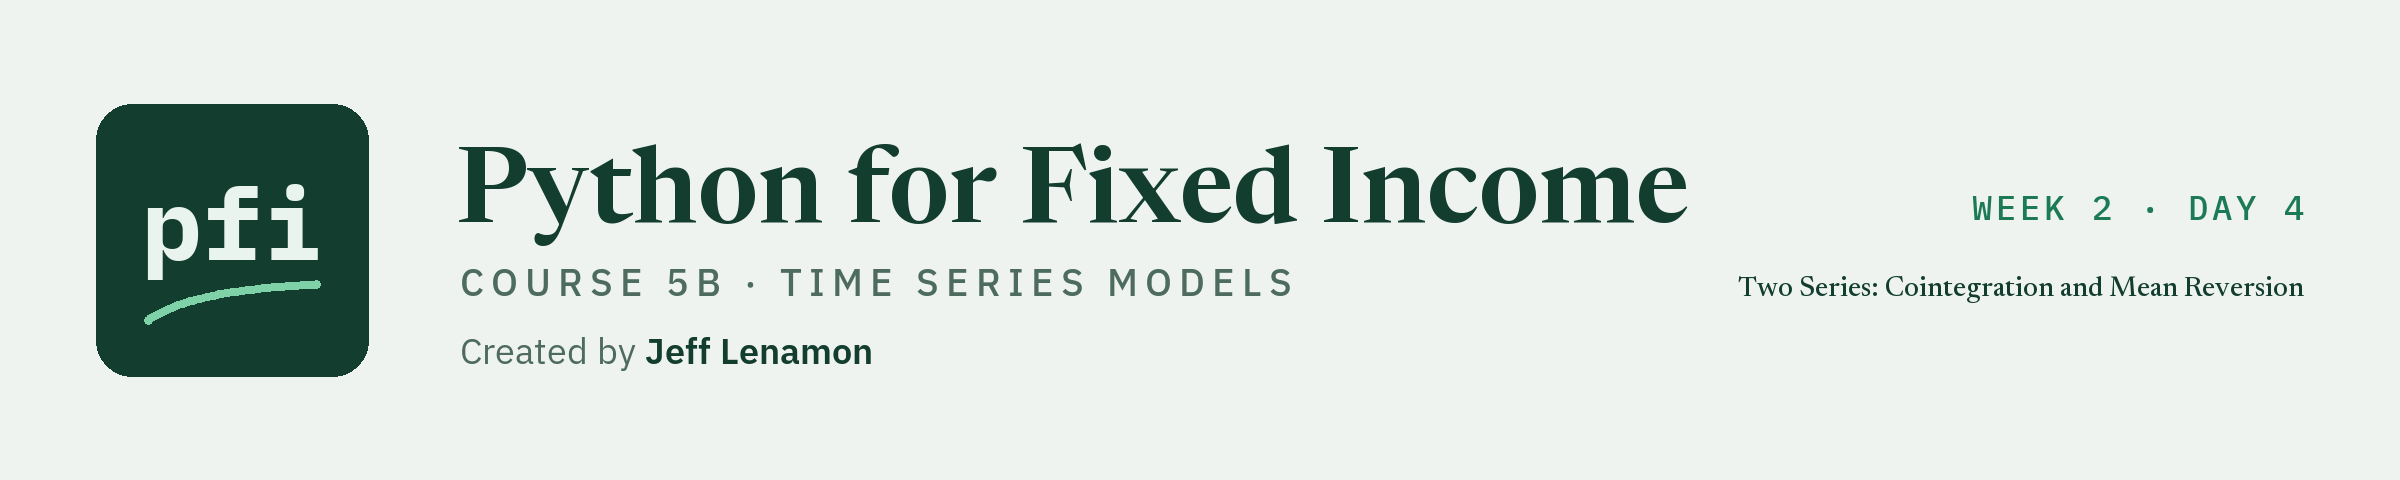

# Two Series: Cointegration and Mean Reversion

Week 2, Day 4. Describe how two series move together: the hedge ratio, a test of cointegration, and the half-life of the gap between them, on the Treasury curve and the invented spreads.

**Data:** `treasury_par_yields.csv`, 2,940 days of U.S. Treasury par yields, 2015-01-02 to 2026-10-02: **real**, U.S. Department of the Treasury, public domain.

**Data:** `course3_synthetic_spreads.csv`, 2,940 daily investment grade and high yield spreads in bp, one per date of the Treasury file: **synthetic**, invented for Course 3, not ICE, Moody's, or any index.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course5b_time_series/week2/day4/09_two_series_cointegration_and_mean_reversion.ipynb)

Until today each model had one series. Two series that move together raise a new question. Two levels can be highly correlated and tell nothing (day 3's spurious regression), or they can be tied together so that the gap between them keeps returning to a level. The second case is named **cointegration**, and a test, the **Engle-Granger** test, asks which case a pair is. A **hedge ratio** says how many bp one series moved per bp of the other. The **half-life** says how long the gap took to close by half. All three describe a pair over a stretch of dates; none says what the pair will do next.

* **The task is in the past tense.** "The gap between the two series closed at a half-life of N trading days over these years." That sentence is the whole of what today's numbers say. Every fit is on dates inside 2015-01-02 to 2022-12-30, and nothing is fitted for or reported at a later date. The held-out years stay closed until the capstone.
* **A description, never a trade.** Nothing here says a gap is rich or cheap, that it will close, or that any position should be taken. A gap with a short half-life over past years is a fact about those years.
* **Two pairs.** The **5 Yr and 10 Yr** Treasury yields in bp (real: the U.S. Treasury's public file), and the **IG and HY spreads** in bp (invented: Course 3's synthetic spreads, which are not ICE, Moody's, or any index).
* **The honest findings come first, and they differ by pair.** The 5 Yr and 10 Yr are correlated at 0.97 in levels and the test does not find them cointegrated. The invented IG and HY spreads are, and the notebook shows how far that holds from one fold to the next.

Today you will:

1. Compare the correlation of two series' levels with the correlation of their daily changes.
2. Fit a hedge ratio, draw the gap between the series, and describe it with bands of its own standard deviation.
3. Test a pair for cointegration, read every setting of `coint`, and sweep the trend and the lag choice.
4. Measure the half-life of the gap from an AR(1), with the sign checked.
5. Draw a rolling hedge ratio, and ask fold by fold whether a ratio fitted on earlier dates still described the next dates.
6. Say what these numbers describe, and what they do not.

Q. Set up today's work folder: the thread settings, the seed, the data files, and the modules.

## Before you start: install the libraries

Run this cell first. It checks that every library this course pins in its `requirements.txt` is installed and installs only what is missing, so it finishes in a second on a machine set up from the repo's `requirements.txt` and does the installing for you in Google Colab. If it installs anything in Colab, restart the session (Runtime, Restart session) and run the notebook again from the top.

In [1]:
# install what this notebook needs: the course's pinned libraries, only those not already present
import importlib.util
import subprocess
import sys

# import name: the pinned package, from course5b_time_series/requirements.txt
NEEDED = {
    "arch": "arch==8.0.0",
    "catboost": "catboost==1.2.10",
    "imblearn": "imbalanced-learn==0.14.2",
    "ipykernel": "ipykernel==7.4.0",
    "ipywidgets": "ipywidgets==8.1.9",
    "jinja2": "jinja2==3.1.6",
    "lightgbm": "lightgbm==4.7.0",
    "matplotlib": "matplotlib==3.11.2",
    "numpy": "numpy==2.5.3",
    "openpyxl": "openpyxl==3.1.5",
    "optuna": "optuna==5.0.0",
    "pandas": "pandas==3.0.6",
    "pytest": "pytest==9.1.1",
    "sklearn": "scikit-learn==1.9.1",
    "scipy": "scipy==1.18.1",
    "shap": "shap==0.52.0",
    "statsmodels": "statsmodels==0.15.0",
    "xgboost": "xgboost==3.4.1",
}

# a package is present when Python can find its module; the version is left as the machine has it
missing = [pin for module, pin in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    print(f"{len(NEEDED)} packages checked, {len(missing)} installed: restart the session and run again from the top")
else:
    print(f"{len(NEEDED)} packages checked, all present")

18 packages checked, all present


In [2]:
# today's setup: the thread settings, the modules, the seed, the course data, and a fresh work folder
import os

# one thread for the maths libraries, so every run of the notebook gives the same last digits.
# These two lines must run before numpy, pandas, statsmodels, arch, or LightGBM is imported: if you ran another
# cell first, restart the kernel and run this cell first (in Colab: Runtime, Restart session).
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

import importlib
import importlib.metadata
import importlib.util
import platform
import shutil
import subprocess
import sys
import tempfile
import urllib.request
from pathlib import Path

# packages a Colab runtime or a new environment may lack: stop with the line that installs the missing one
for module_name, install_name in [("statsmodels", "statsmodels"), ("arch", "arch"), ("scipy", "scipy"), ("sklearn", "scikit-learn"), ("lightgbm", "lightgbm"), ("pytest", "pytest")]:
    if importlib.util.find_spec(module_name) is None:
        raise RuntimeError(f"{install_name} is not installed. Run  !pip install {install_name}  in a new cell, "
                           "then run this cell again.")

import numpy as np
import pandas as pd

# the versions the saved outputs of this notebook came from (course5b_time_series/requirements.txt)
PINNED = {"numpy": "2.5.3", "pandas": "3.0.6", "scipy": "1.18.1", "statsmodels": "0.15.0", "arch": "8.0.0", "scikit-learn": "1.9.1", "lightgbm": "4.7.0", "matplotlib": "3.11.2", "pytest": "9.1.1"}
installed = {name: importlib.metadata.version(name) for name in PINNED}
print(f"Python {platform.python_version()}; " + ", ".join(f"{name} {version}" for name, version in installed.items()))
different = [name for name in PINNED if installed[name] != PINNED[name]]
if different:
    print(f"Not the course's pinned version: {', '.join(different)}. Printed numbers may differ in the last digits from the saved notebook.")

# the seed: one number for every random choice the course makes, so every run makes the same choices
SEED = 42

# remember the notebook's own folder, so that running this cell again starts from the same place
if "notebook_folder" not in globals():
    notebook_folder = Path.cwd()

# 1. find the course data before moving: the repo's data folder on your machine, GitHub in Colab
RAW_DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"
local_data = (notebook_folder / ".." / ".." / ".." / "data").resolve()
on_github = not (local_data / "treasury_par_yields.csv").exists()

# 2. a fresh work folder for today, in the system temp folder, outside the course repo
work = Path(tempfile.mkdtemp(prefix="pfi_course5b_09_"))
os.chdir(work)

# 3. copy today's data files into the work folder
DATA_FILES = ["treasury_par_yields.csv", "course3_synthetic_spreads.csv"]
for name in DATA_FILES:
    if on_github:
        urllib.request.urlretrieve(RAW_DATA + name, work / name)
    else:
        shutil.copy(local_data / name, work / name)

# print the folder's name only: its full path would show your user name
print(f"Work folder: {work.name}, in your temp folder")
print(f"Data files from {'GitHub' if on_github else 'the data folder of the course repo'}: {', '.join(DATA_FILES)}")
print(f"SEED = {SEED}")

Python 3.13.8; numpy 2.5.3, pandas 3.0.6, scipy 1.18.1, statsmodels 0.15.0, arch 8.0.0, scikit-learn 1.9.1, lightgbm 4.7.0, matplotlib 3.11.2, pytest 9.1.1
Work folder: pfi_course5b_09_o07l31a8, in your temp folder
Data files from the data folder of the course repo: treasury_par_yields.csv, course3_synthetic_spreads.csv
SEED = 42


The setup cell is the same in every Course 5B notebook. `mlkit.py`, `tskit.py`, and its tests below are the files as day 8 left them, and `plotkit.py` is the series' chart helpers, unchanged. Today appends three functions to `tskit.py`.

Q. Write `mlkit.py`, Course 4's complete module, unchanged. `tskit` imports it.

In [3]:
%%writefile mlkit.py
"""mlkit: the small pieces of machine learning that scikit-learn leaves to the analyst, written down and tested.

Written day by day in Python for Fixed Income, Course 4: Machine Learning.

Conventions, the same in every function:
- The seed is 42 wherever a function takes one, so every run gives the same numbers.
- Spreads are in basis points (bp). A model of log_oas is fitted in natural logs of bp; its errors are reported
  in bp after exp, and exp of a fitted log is a median-type value, not a mean.
- The positive class is 1 (default, bankrupt). Precision, recall, and F1 are for class 1 only.
- A row is flagged when its model probability is at least the threshold (probability >= threshold).
- Rows that fit a model, rows that choose a setting, and rows that report a result are kept apart; the split
  functions here prove it with a check that stops.
- Inputs of the wrong shape, or empty inputs, raise ValueError with a message that says what was wrong.
"""
import numpy as np  # arrays and arithmetic
import pandas as pd  # tables with labels
from numpy.typing import ArrayLike  # a list, an array, or a pandas Series


def assert_disjoint(train_index: ArrayLike, test_index: ArrayLike) -> None:
    """Stop if any row label is in both the training rows and the test rows.

    Inputs: the labels (or positions) of the rows in each part, for example X_train.index and X_test.index.
    Output: None when the parts share no label.
    Convention: a row in both parts is a test row the model has already seen, which flatters every metric.
    Raises AssertionError naming how many labels are in both parts, and ValueError if either part is empty.
    """
    # the labels of each part as sets
    train = set(np.asarray(train_index).tolist())
    test = set(np.asarray(test_index).tolist())
    if not train or not test:
        raise ValueError("train_index and test_index must both hold at least one label")
    # the labels found in both parts
    shared = train & test
    if shared:
        raise AssertionError(f"{len(shared)} row labels are in both the training and the test rows")


def _as_1d_array(values: ArrayLike, name: str) -> np.ndarray:
    """Return `values` as a 1-D float array, or raise ValueError naming the input."""
    array = np.asarray(values, dtype=float)
    if array.ndim != 1:
        raise ValueError(f"{name} must be one-dimensional, not {array.ndim}-dimensional")
    if array.size == 0:
        raise ValueError(f"{name} is empty")
    return array


def regression_metrics(y_true: ArrayLike, y_fitted: ArrayLike) -> dict[str, float]:
    """R-squared, mean absolute error, and root mean squared error of fitted values.

    Inputs: y_true and y_fitted, the same length, in the target's unit (for example oas in bp).
    Output: {"r2", "mae", "rmse"}. r2 is unitless, 1 - SS_res / SS_tot on the rows given (on test rows it can
    be negative); mae and rmse are in the target's unit. For a log_oas model, pass exp of both to get bp.
    Convention: equal to scikit-learn's r2_score, mean_absolute_error, and root_mean_squared_error.
    Excel: =RSQ(...) only for a straight line on one feature; =AVERAGE(ABS(a-b)) and =SQRT(SUMXMY2(a,b)/COUNT(a)).
    Raises ValueError if the inputs are empty, not one-dimensional, or of different lengths.
    """
    # check both inputs and that they line up row for row
    actual = _as_1d_array(y_true, "y_true")
    fitted = _as_1d_array(y_fitted, "y_fitted")
    if actual.size != fitted.size:
        raise ValueError(f"y_true has {actual.size} values and y_fitted has {fitted.size}")
    # each error in the target's unit
    errors = actual - fitted
    # R-squared: the share of the spread around the mean that the fitted values account for
    ss_res = float(np.sum(errors ** 2))
    ss_tot = float(np.sum((actual - actual.mean()) ** 2))
    r2 = 1 - ss_res / ss_tot
    # the average size of an error, and the square root of the average squared error
    mae = float(np.mean(np.abs(errors)))
    rmse = float(np.sqrt(np.mean(errors ** 2)))
    return {"r2": r2, "mae": mae, "rmse": rmse}


def adjusted_r2(r2: float, n_rows: int, n_features: int) -> float:
    """Adjusted R-squared: R-squared with a charge for each feature.

    Inputs: r2 on the training rows (unitless), n_rows the number of training rows, n_features the number of
    features not counting the intercept.
    Output: 1 - (1 - r2) x (n_rows - 1) / (n_rows - n_features - 1), unitless. An in-sample measure, so it is
    computed on training rows only.
    Excel: =1-(1-R2)*(n-1)/(n-k-1)
    Raises ValueError if n_features is negative or n_rows is not above n_features + 1.
    """
    # the formula needs at least one degree of freedom left after the features and the intercept
    if n_features < 0:
        raise ValueError(f"n_features must be 0 or more, not {n_features}")
    if n_rows <= n_features + 1:
        raise ValueError(f"n_rows ({n_rows}) must be greater than n_features + 1 ({n_features + 1})")
    # scale the unexplained share by the ratio of degrees of freedom
    return 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1)


def rating_dummies(ratings: pd.Series, levels: list[str], reference: str) -> pd.DataFrame:
    """One indicator column per rating level except the reference level, which the intercept stands for.

    Inputs: ratings, one text rating per bond (for example "BBB+"); levels, every allowed level in the order the
    columns should follow (the rating column of ratings.csv, known in advance, not learned from the data);
    reference, the level left out.
    Output: a DataFrame with the same index, one float column (0.0 or 1.0) per level except reference, named
    rating_<level>, in the order of levels. A coefficient on rating_BB is then the difference from a bond rated
    `reference`, other features fixed.
    Convention: floats, not booleans, so every library and an Excel formula read the same 0.0 and 1.0. The
    reference is named by the caller, never chosen by alphabetical order.
    Raises ValueError if ratings is empty, reference is not in levels, or a rating is not in levels.
    """
    # check the inputs before building anything
    if len(ratings) == 0:
        raise ValueError("ratings is empty")
    if reference not in levels:
        raise ValueError(f"reference {reference!r} is not one of the levels")
    unknown = sorted(set(ratings) - set(levels))
    if unknown:
        raise ValueError(f"ratings not in levels: {unknown}")
    # one column per level, 1.0 where the bond has that rating
    columns = {f"rating_{level}": (ratings == level).astype(float) for level in levels if level != reference}
    return pd.DataFrame(columns, index=ratings.index)


def vif_table(X: pd.DataFrame) -> pd.Series:
    """Variance inflation factor of each feature: how much its coefficient's variance grows from the overlap with
    the other features.

    Input: X, the features as numeric columns (no constant column; one is added inside).
    Output: a Series named vif, one value per column, sorted from highest to lowest. VIF_j = 1 / (1 - R2_j),
    where R2_j is the R-squared of column j regressed on a constant and every other column. 1 means no overlap;
    above 5 is called high and above 10 very high, as conventions. A column that is an exact copy (or exact
    combination) of others has R2_j = 1 and VIF infinity.
    Convention: equal to statsmodels' variance_inflation_factor on X with a constant added.
    Excel: =1/(1-INDEX(LINEST(xj, other columns, TRUE, TRUE), 3, 1))
    Raises ValueError if X has fewer than two columns or fewer rows than columns plus two.
    """
    # check there is something to regress on, and enough rows to do it
    if X.shape[1] < 2:
        raise ValueError(f"X needs at least two columns, not {X.shape[1]}")
    if X.shape[0] < X.shape[1] + 2:
        raise ValueError(f"X has {X.shape[0]} rows, too few for {X.shape[1]} columns")
    values = X.to_numpy(dtype=float)
    result = {}
    for j, name in enumerate(X.columns):
        # column j is the target; a constant and the other columns are the features
        target = values[:, j]
        others = np.column_stack([np.ones(len(values)), np.delete(values, j, axis=1)])
        # least squares fit and its R-squared
        coefficients, *_ = np.linalg.lstsq(others, target, rcond=None)
        ss_res = float(np.sum((target - others @ coefficients) ** 2))
        ss_tot = float(np.sum((target - target.mean()) ** 2))
        r2 = 1 - ss_res / ss_tot
        # an exact combination of the others leaves no residual (R-squared 1 to the last digit): the VIF is infinite
        result[name] = np.inf if r2 >= 1 else 1 / (1 - r2)
    return pd.Series(result, name="vif").sort_values(ascending=False)


from scipy import stats  # Jarque-Bera and Shapiro-Wilk
from statsmodels.stats.diagnostic import het_breuschpagan  # Breusch-Pagan
from statsmodels.tools import add_constant  # the intercept column


def residual_tests(residuals: pd.Series, exog: pd.DataFrame) -> dict[str, float]:
    """p-values of three checks on a regression's residuals: constant variance and normality (two tests).

    Inputs: residuals, actual minus fitted on the training rows, in the target's unit; exog, the features the
    model was fitted on, without a constant (one is added inside), with the same rows.
    Output: {"breusch_pagan", "jarque_bera", "shapiro_wilk"}, each a p-value between 0 and 1. A small p-value
    (below 0.05, the course's convention) means the data would be surprising if the assumption held:
    - breusch_pagan: statsmodels het_breuschpagan with its default (Koenker's form, n x R-squared of the squared
      residuals regressed on a constant and exog); the assumption is constant variance;
    - jarque_bera: scipy.stats.jarque_bera (skew and kurtosis); the assumption is normal residuals;
    - shapiro_wilk: scipy.stats.shapiro; the assumption is normal residuals.
    Excel has no function for these; Breusch-Pagan can be built from LINEST and CHISQ.DIST.RT.
    Raises ValueError if the inputs are empty or have different numbers of rows.
    """
    # check the two inputs line up
    if len(residuals) == 0 or len(exog) == 0:
        raise ValueError("residuals and exog must not be empty")
    if len(residuals) != len(exog):
        raise ValueError(f"residuals has {len(residuals)} rows and exog has {len(exog)}")
    values = np.asarray(residuals, dtype=float)
    # Breusch-Pagan: returns the LM statistic, its p-value, then an F form; the LM p-value is kept
    _, bp_pvalue, _, _ = het_breuschpagan(values, add_constant(np.asarray(exog, dtype=float), has_constant="add"))
    # the two normality tests
    jb_pvalue = stats.jarque_bera(values).pvalue
    sw_pvalue = stats.shapiro(values).pvalue
    return {"breusch_pagan": float(bp_pvalue), "jarque_bera": float(jb_pvalue), "shapiro_wilk": float(sw_pvalue)}


from sklearn.pipeline import Pipeline  # the type of a chain of steps


def named_coefficients(pipeline: Pipeline) -> pd.Series:
    """The fitted coefficients of a pipeline's last step, labelled with the feature names that step saw.

    Input: a fitted scikit-learn Pipeline whose last step has coef_ (LinearRegression, Ridge, Lasso,
    LogisticRegression) and whose step before it has get_feature_names_out (a ColumnTransformer, a scaler).
    Output: a Series of coefficients indexed by feature name, in the order the model used them. Units: per unit
    of each feature as the model saw it, so per standard deviation after StandardScaler; the intercept is not
    included. For a binary LogisticRegression the one row of coef_ is used (log-odds of class 1).
    Raises ValueError if the last step has no coef_ (a tree, for example) or the pipeline has one step only.
    """
    # the model is the last step; the names come from everything before it
    if len(pipeline.steps) < 2:
        raise ValueError("the pipeline needs a preprocessing step before the model")
    model = pipeline.steps[-1][1]
    if not hasattr(model, "coef_"):
        raise ValueError(f"the last step, {type(model).__name__}, has no coef_")
    names = pipeline[:-1].get_feature_names_out()
    # a binary classifier keeps its coefficients in one row; flatten it
    coefficients = np.ravel(model.coef_)
    if coefficients.size != len(names):
        raise ValueError(f"{coefficients.size} coefficients but {len(names)} feature names")
    return pd.Series(coefficients, index=names, name="coefficient")


def odds_ratios(coefficients: pd.Series) -> pd.Series:
    """Odds ratios from logistic regression coefficients: exp of each coefficient, the intercept left out.

    Input: coefficients in log-odds, indexed by feature name, as statsmodels' Logit params (the intercept is
    named "const") or a Series with an entry named "intercept".
    Output: a Series of exp(coefficient) per feature: the factor by which the odds of class 1 multiply for one
    more unit of that feature, other features fixed. The unit is the feature's own (per 10,000 NT dollars if the
    feature was divided by 10,000; per standard deviation if it was scaled).
    Excel: =EXP(coef)
    Raises ValueError if no coefficient is left once the intercept is removed.
    """
    # leave out the intercept: exp of it is the odds when every feature is 0, not a ratio
    slopes = coefficients.drop(labels=["const", "intercept"], errors="ignore")
    if slopes.empty:
        raise ValueError("no coefficients left after removing the intercept")
    return np.exp(slopes).rename("odds_ratio")


def logistic_probability(z: float | ArrayLike) -> float | np.ndarray:
    """The logistic curve: turns log-odds z into a probability between 0 and 1.

    Input: z, a number or an array of numbers in log-odds (intercept plus coefficients times features).
    Output: 1 / (1 + exp(-z)), a float for a number, an array for an array. z = 0 gives 0.5.
    Excel: =1/(1+EXP(-z))
    """
    # numpy's exp works on a number and on an array alike
    probability = 1 / (1 + np.exp(-np.asarray(z, dtype=float)))
    return float(probability) if probability.ndim == 0 else probability


def _check_labels(y_true: ArrayLike, y_flag: ArrayLike) -> tuple[np.ndarray, np.ndarray]:
    """Return both inputs as integer arrays of 0 and 1, or raise ValueError."""
    actual = np.asarray(y_true)
    flagged = np.asarray(y_flag)
    if actual.ndim != 1 or flagged.ndim != 1 or actual.size == 0:
        raise ValueError("y_true and y_flag must be non-empty and one-dimensional")
    if actual.size != flagged.size:
        raise ValueError(f"y_true has {actual.size} values and y_flag has {flagged.size}")
    for name, values in (("y_true", actual), ("y_flag", flagged)):
        others = sorted(set(values.tolist()) - {0, 1})
        if others:
            raise ValueError(f"{name} holds labels other than 0 and 1: {others[:5]}")
    return actual.astype(int), flagged.astype(int)


def confusion_counts(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, int]:
    """The four cells of the confusion matrix, with 1 (default) as the positive class.

    Inputs: y_true, the actual outcome per row (0 or 1); y_flag, the model's flag per row (0 or 1), for example
    (probability >= threshold).
    Output: {"tn", "fp", "fn", "tp"} as whole numbers: true negatives (0 flagged 0), false positives (0 flagged
    1), false negatives (1 flagged 0), true positives (1 flagged 1). They add up to the number of rows.
    Convention: the same counts as confusion_matrix(y_true, y_flag).ravel() in scikit-learn.
    Excel: =COUNTIFS(actual,1,flag,1) and the other three combinations.
    Raises ValueError on labels other than 0 and 1, empty inputs, or inputs of different lengths.
    """
    actual, flagged = _check_labels(y_true, y_flag)
    # count each combination of actual and flag
    return {"tn": int(np.sum((actual == 0) & (flagged == 0))), "fp": int(np.sum((actual == 0) & (flagged == 1))),
            "fn": int(np.sum((actual == 1) & (flagged == 0))), "tp": int(np.sum((actual == 1) & (flagged == 1)))}


def classification_metrics(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, float]:
    """Accuracy, precision, recall, and F1 for class 1 (default), from 0/1 flags.

    Inputs: y_true and y_flag, as confusion_counts.
    Output: {"accuracy", "precision", "recall", "f1"}, each between 0 and 1:
    accuracy (TP + TN) / n; precision TP / (TP + FP), the share of flagged rows that are defaults; recall
    TP / (TP + FN), the share of defaults that are flagged; F1 their harmonic mean, 2TP / (2TP + FP + FN).
    Convention: pos_label=1, binary averaging, zero_division=0 (a model that flags nothing has precision 0, not
    an error), as scikit-learn's functions with those arguments.
    Excel: =TP/(TP+FP), =TP/(TP+FN) with the COUNTIFS cells.
    Raises ValueError as confusion_counts.
    """
    counts = confusion_counts(y_true, y_flag)
    tn, fp, fn, tp = counts["tn"], counts["fp"], counts["fn"], counts["tp"]
    # each ratio is 0 when its denominator is 0 (zero_division=0)
    accuracy = (tp + tn) / (tn + fp + fn + tp)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if tp + fp + fn else 0.0
    return {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}


def threshold_for_recall(y_true: ArrayLike, proba: ArrayLike, target_recall: float) -> float:
    """The highest threshold at which the model still catches at least `target_recall` of the defaults.

    Inputs: y_true, actual outcomes (0 or 1) on the rows used to choose (validation rows, or out-of-fold
    predictions on training rows, never test rows); proba, the model probability of class 1 per row;
    target_recall, the share of defaults the desk asks to catch, above 0 and at most 1.
    Output: one of the distinct probabilities. Flagging rows with probability >= that threshold gives recall at
    least target_recall, and the next higher distinct probability would give less. A higher threshold flags
    fewer rows, so this is the threshold with the fewest flags that meets the target.
    Convention: the course's threshold rule, stated as an illustration of the recall-against-precision choice.
    Raises ValueError if target_recall is not in (0, 1], the inputs differ in length, or there is no row of
    class 1.
    """
    # check the target and the inputs
    if not 0 < target_recall <= 1:
        raise ValueError(f"target_recall must be above 0 and at most 1, not {target_recall}")
    scores = _as_1d_array(proba, "proba")
    # y_true is checked as a set of 0/1 labels the same length as proba
    actual, _ = _check_labels(y_true, np.zeros(scores.size, dtype=int))
    positives = int(actual.sum())
    if positives == 0:
        raise ValueError("y_true has no row of class 1, so recall is undefined")
    # sort rows from the highest probability down; lowering the threshold adds rows in this order
    order = np.argsort(-scores, kind="stable")
    sorted_scores, sorted_actual = scores[order], actual[order]
    # defaults caught when every row down to this one is flagged
    caught = np.cumsum(sorted_actual)
    # a threshold equal to a probability flags every row with that probability, so look at the last row of
    # each run of equal probabilities
    last_of_run = np.append(sorted_scores[1:] != sorted_scores[:-1], True)
    recall = caught[last_of_run] / positives
    thresholds = sorted_scores[last_of_run]
    # thresholds run from high to low and recall only rises: take the first one that meets the target
    meets = np.nonzero(recall >= target_recall)[0]
    return float(thresholds[meets[0]])


from sklearn.model_selection import KFold, StratifiedKFold  # the course's cross-validation splitters


def cv_folds(kind: str = "classification") -> KFold | StratifiedKFold:
    """The course's cross-validation splitter, so the choice lives in one place.

    Input: kind, "classification" or "regression".
    Output: StratifiedKFold(5, shuffle=True, random_state=42) for classification (each fold keeps the share of
    class 1), KFold(5, shuffle=True, random_state=42) for regression. Pass it as cv= to GridSearchCV,
    cross_val_score, or cross_val_predict, on training rows only.
    Convention: never for dated rows, which use walk_forward_splits or TimeSeriesSplit (no shuffle).
    Raises ValueError for any other kind.
    """
    # five folds, shuffled once with the course's seed
    if kind == "classification":
        return StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    if kind == "regression":
        return KFold(n_splits=5, shuffle=True, random_state=42)
    raise ValueError(f'kind must be "classification" or "regression", not {kind!r}')


import re  # whole-word search

from sklearn.metrics import average_precision_score, roc_auc_score

# words that turn a description into a forecast, advice, or a lending decision; a reminder, not a proof
FORECAST_WORDS = ["will", "expect", "expects", "should", "forecast", "forecasts", "cheap", "rich", "attractive",
                  "signal", "signals", "buy", "sell", "approve", "decline", "lend", "invest"]


def compare_models(models: dict, X: pd.DataFrame, y: ArrayLike, thresholds: dict[str, float]) -> pd.DataFrame:
    """One row of metrics per fitted model, on the rows given.

    Inputs: models, {name: a fitted classifier with predict_proba}, fitted by the caller on training rows;
    X and y, the rows to report on (validation rows, or the test rows once at the end); thresholds,
    {name: threshold} for every model, chosen on rows other than these test rows.
    Output: a DataFrame indexed by model name with columns roc_auc and average_precision (from probabilities,
    no threshold), then threshold, accuracy, precision, recall, f1 for rows flagged at probability >= threshold.
    Convention: nothing is fitted here; an unfitted model raises scikit-learn's NotFittedError.
    Raises ValueError if models is empty or a model has no threshold.
    """
    # check every model has a threshold before computing anything
    if not models:
        raise ValueError("models is empty")
    missing = sorted(set(models) - set(thresholds))
    if missing:
        raise ValueError(f"no threshold for: {missing}")
    rows = {}
    for name, model in models.items():
        # the model probability of class 1 per row
        proba = model.predict_proba(X)[:, 1]
        # metrics that rank without a threshold, then metrics at the model's threshold
        row = {"roc_auc": roc_auc_score(y, proba), "average_precision": average_precision_score(y, proba),
               "threshold": thresholds[name]}
        row |= classification_metrics(y, (proba >= thresholds[name]).astype(int))
        rows[name] = row
    return pd.DataFrame.from_dict(rows, orient="index")


def assert_descriptive(text: str) -> None:
    """Stop if a written description uses a word from FORECAST_WORDS.

    Input: text, a description of what a model shows.
    Output: None if no listed word appears as a whole word, in any case.
    Convention: the list is a reminder, not a proof. A text can pass and still make a forecast in other words,
    and a listed word can be harmless in context; the check makes the writer look again.
    Raises ValueError naming every listed word found, in the order of FORECAST_WORDS.
    """
    # whole words only, ignoring case: "willing" does not match "will"
    found = [word for word in FORECAST_WORDS if re.search(rf"\b{word}\b", text, flags=re.IGNORECASE)]
    if found:
        raise ValueError(f"the text uses forecast, advice, or lending words: {found}")


def walk_forward_splits(dates: pd.DatetimeIndex, min_train: int, test_size: int,
                        gap: int = 0) -> list[tuple[np.ndarray, np.ndarray]]:
    """Expanding-window splits for dated rows: train on the past, test on the rows that follow.

    Inputs: dates, the rows' dates, unique and ascending; min_train, the rows in the first training window;
    test_size, the rows in each test window; gap, rows left out between the last training row and the first
    test row (use the number of rows a target or feature spans; 0 for a same-day target).
    Output: a list of (train_positions, test_positions), integer positions into dates. Fold k trains on
    positions 0 to min_train + k x test_size - 1 and tests the next test_size positions after `gap` rows.
    The window steps forward by test_size; a last test window shorter than test_size is dropped.
    Convention: never shuffled; every training date is before every test date.
    Raises ValueError if the dates are not unique and ascending, min_train or test_size is below 1, gap is
    negative, or there are too few rows for one fold.
    """
    # check the dates and the sizes
    index = pd.DatetimeIndex(dates)
    if not (index.is_unique and index.is_monotonic_increasing):
        raise ValueError("dates must be unique and ascending")
    if min_train < 1 or test_size < 1 or gap < 0:
        raise ValueError(f"need min_train >= 1, test_size >= 1, gap >= 0; got {min_train}, {test_size}, {gap}")
    splits = []
    train_end = min_train  # one past the last training position
    # add folds while a whole test window fits after the gap
    while train_end + gap + test_size <= len(index):
        test_start = train_end + gap
        splits.append((np.arange(0, train_end), np.arange(test_start, test_start + test_size)))
        train_end += test_size
    if not splits:
        raise ValueError(f"{len(index)} rows are too few for min_train {min_train}, gap {gap}, test_size {test_size}")
    return splits


def assert_past_only(train_dates: ArrayLike, test_dates: ArrayLike, gap: int = 0,
                     calendar: ArrayLike | None = None) -> None:
    """Stop unless every training date is earlier than every test date, with a gap where one is asked for.

    Inputs: the dates of the training rows and of the test rows; gap, the rows of `calendar` that must lie
    strictly between the last training date and the first test date; calendar, every date of the dataset
    (needed when gap is above 0).
    Output: None when the split uses only the past.
    Raises AssertionError naming the last training date and the first test date when the order or the gap is
    wrong, and ValueError if either part is empty or a gap is asked for without a calendar.
    """
    train = pd.DatetimeIndex(train_dates)
    test = pd.DatetimeIndex(test_dates)
    if len(train) == 0 or len(test) == 0:
        raise ValueError("train_dates and test_dates must both hold at least one date")
    # the latest training date must come before the earliest test date
    last_train, first_test = train.max(), test.min()
    if not last_train < first_test:
        raise AssertionError(f"a training date ({last_train.date()}) is not before the first test date "
                             f"({first_test.date()})")
    if gap > 0:
        if calendar is None:
            raise ValueError("a gap is counted in rows of the calendar, so calendar is needed")
        # rows of the calendar strictly between the two dates
        days = pd.DatetimeIndex(calendar)
        between = int(((days > last_train) & (days < first_test)).sum())
        if between < gap:
            raise AssertionError(f"only {between} rows lie between {last_train.date()} and {first_test.date()}, "
                                 f"fewer than the gap of {gap}")


from collections.abc import Iterable

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


def elbow_table(X: ArrayLike, k_values: Iterable[int], seed: int = 42) -> pd.DataFrame:
    """Inertia and silhouette of K-means for each number of clusters, to choose k by judgement.

    Inputs: X, the features already scaled (K-means measures distance, so units decide the clusters); k_values,
    the numbers of clusters to try, each 2 or more; seed, passed as random_state.
    Output: a DataFrame indexed by k (named k) with columns inertia (the within-cluster sum of squared distances,
    in squared scaled units; it falls as k rises) and silhouette (the mean silhouette coefficient, Euclidean,
    -1 to 1; higher means tighter, better separated clusters).
    Convention: KMeans(n_clusters=k, n_init=10, random_state=seed), n_init written out.
    Raises ValueError if k_values is empty, a k is below 2, or a k is not below the number of rows.
    """
    # check the k values before fitting
    ks = list(k_values)
    if not ks:
        raise ValueError("k_values is empty")
    n_rows = len(X)
    bad = [k for k in ks if k < 2 or k >= n_rows]
    if bad:
        raise ValueError(f"each k must be at least 2 and below the {n_rows} rows; not {bad}")
    rows = []
    for k in ks:
        # fit K-means with ten starts and the course's seed
        model = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X)
        rows.append({"k": k, "inertia": float(model.inertia_), "silhouette": float(silhouette_score(X, model.labels_))})
    return pd.DataFrame(rows).set_index("k")


def cluster_profile(frame: pd.DataFrame, labels: ArrayLike, columns: list[str]) -> pd.DataFrame:
    """Describe each cluster in the data's own units: how many rows, and the median of each column.

    Inputs: frame, the rows in their original units (oas in bp, duration in years), not the scaled features the
    clusters were fitted on; labels, the cluster of each row, in the same order; columns, the columns to profile.
    Output: a DataFrame indexed by cluster (named cluster, sorted), with count and one median column per name in
    columns, in the frame's units. A profile describes a group; it does not rank one.
    Excel: a pivot table counts and averages but has no median; =MEDIAN(IF(labels=k, column)) does.
    Raises ValueError if labels and frame differ in length, frame is empty, or a column is not in frame.
    """
    # check the inputs line up and the columns exist
    labels = np.asarray(labels)
    if len(frame) == 0:
        raise ValueError("frame is empty")
    if len(labels) != len(frame):
        raise ValueError(f"labels has {len(labels)} values and frame has {len(frame)} rows")
    missing = [c for c in columns if c not in frame.columns]
    if missing:
        raise ValueError(f"columns not in frame: {missing}")
    # group the original rows by cluster, then count and take medians
    grouped = frame[columns].groupby(pd.Series(labels, index=frame.index, name="cluster"))
    profile = grouped.median()
    profile.insert(0, "count", grouped.size())
    return profile.sort_index()


from sklearn.decomposition import PCA


def pca_loadings(pca: PCA, names: list[str]) -> pd.DataFrame:
    """The loadings of a fitted PCA, one column per component, each with a fixed sign.

    Inputs: pca, a fitted scikit-learn PCA; names, the input columns in the order the PCA saw them (for the
    curve, the tenors).
    Output: a DataFrame indexed by name with columns PC1, PC2, ...: each component's weights on the inputs
    (pca.components_ transposed, unit length). A component's sign is arbitrary, so each column is multiplied by
    -1 where needed to make its loadings sum to a positive number; a rerun or another library then gives the
    same picture. Scores that match these loadings are (X - pca.mean_) @ loadings.
    Excel: no PCA function; =MMULT(changes less their column means, loadings) gives the scores.
    Raises ValueError if names does not have one entry per input column.
    """
    # one name per input column
    components = np.asarray(pca.components_)
    if len(names) != components.shape[1]:
        raise ValueError(f"{len(names)} names for {components.shape[1]} input columns")
    loadings = pd.DataFrame(components.T, index=names,
                            columns=[f"PC{i}" for i in range(1, components.shape[0] + 1)])
    # flip each component whose loadings sum to a negative number
    signs = np.where(loadings.sum(axis=0) < 0, -1.0, 1.0)
    return loadings * signs


def explained_table(pca: PCA) -> pd.DataFrame:
    """The share of variance each component of a fitted PCA accounts for, and the running total, in percent.

    Input: pca, a fitted scikit-learn PCA.
    Output: a DataFrame indexed by PC1, PC2, ... with explained_pct (explained_variance_ratio_ x 100) and
    cumulative_pct (the running sum). With every component kept, the last cumulative_pct is 100.
    """
    # the ratios in percent, then their running sum
    explained = np.asarray(pca.explained_variance_ratio_) * 100
    index = [f"PC{i}" for i in range(1, len(explained) + 1)]
    return pd.DataFrame({"explained_pct": explained, "cumulative_pct": np.cumsum(explained)}, index=index)

Writing mlkit.py


Q. Write `tskit.py` and `test_tskit.py` as they stand at the start of today: the reference version at the end of the last notebook.

In [4]:
%%writefile tskit.py
"""tskit: the time series pieces of Course 5B, written down and tested.

Written day by day in Python for Fixed Income, Course 5B: Time Series Models.

Conventions, the same in every function:
- A series is a pandas Series, and a frame a DataFrame, indexed by date: unique and ascending.
- Yields are in percent and changes in bp, as in the Treasury file; each docstring states its unit.
- A function that describes or repairs data never fills an earlier date from a later one unless its docstring
  says so in its first lines.
- A fitted value is for a date inside the file, from a model fitted on earlier dates only; it is never a
  statement about a date after the file ends.
- Inputs of the wrong shape, or empty inputs, raise ValueError with a message that says what was wrong.
"""
import numpy as np  # arrays and arithmetic
import pandas as pd  # dated tables

import mlkit  # Course 4's module: its walk-forward splits and its past-only check are used from day 2


def _check_dated(index: pd.Index, name: str) -> None:
    """Stop unless the index is a DatetimeIndex that is not empty, unique, and ascending."""
    if not isinstance(index, pd.DatetimeIndex):
        raise ValueError(f"{name} must be indexed by date (a DatetimeIndex)")
    if len(index) == 0:
        raise ValueError(f"{name} is empty")
    if not (index.is_unique and index.is_monotonic_increasing):
        raise ValueError(f"{name} must have unique dates in ascending order")


def gap_report(frame: pd.DataFrame) -> pd.DataFrame:
    """One row per column of a dated frame: where the series starts and ends, and where its values are blank.

    Input: frame, dated rows (a DatetimeIndex, unique and ascending), one column per series.
    Output: a DataFrame indexed by column name, with
      rows: the rows in the frame;
      first_valid, last_valid: the first and last dates that hold a value (NaT for a column with none);
      before_start: blank rows before first_valid (a series that had not started yet);
      blank_inside: blank cells from first_valid to last_valid (outages and gaps inside the series);
      after_end: blank rows after last_valid;
      longest_inside: the longest run of consecutive blank rows inside the series (0 when there is none).
    A date with no row at all (a market holiday) is not in the frame, so it is not counted here: compare the
    index with a calendar to find those.
    Raises ValueError for an empty frame or an index that is not dated, unique, and ascending.
    """
    _check_dated(frame.index, "frame")
    rows = []
    for column in frame.columns:
        blank = frame[column].isna().to_numpy()
        first, last = frame[column].first_valid_index(), frame[column].last_valid_index()
        if first is None:
            # no value at all: every row counts as before the start
            rows.append({"column": column, "rows": len(blank), "first_valid": pd.NaT, "last_valid": pd.NaT,
                         "before_start": len(blank), "blank_inside": 0, "after_end": 0, "longest_inside": 0})
            continue
        start, end = frame.index.get_loc(first), frame.index.get_loc(last)
        inside = blank[start:end + 1]
        runs = gap_runs(frame[column].iloc[start:end + 1]) if inside.any() else None
        rows.append({"column": column, "rows": len(blank), "first_valid": first, "last_valid": last,
                     "before_start": start, "blank_inside": int(inside.sum()), "after_end": len(blank) - 1 - end,
                     "longest_inside": int(runs["rows"].max()) if runs is not None else 0})
    return pd.DataFrame(rows).set_index("column")


def gap_runs(series: pd.Series) -> pd.DataFrame:
    """Every run of consecutive blank values in a dated series: its first and last dates and its length in rows.

    Input: series, values indexed by date (unique and ascending).
    Output: a DataFrame with one row per run, in date order, and columns
      start, end: the first and last dates of the run;
      rows: the number of blank rows in the run;
      kind: "before start" for a run on the first row (the series had not started), "after end" for a run that
      reaches the last row, and "inside" for every other run.
    With nothing blank, an empty DataFrame with the same columns. A run counts rows, not calendar days: a blank
    Friday and the blank Monday after it are one run of 2 rows.
    Raises ValueError for an empty series or an index that is not dated, unique, and ascending.
    """
    _check_dated(series.index, "series")
    blank = series.isna()
    # a new run number starts wherever blank switches between True and False
    run_number = (blank != blank.shift(fill_value=not blank.iloc[0])).cumsum()
    runs = []
    for _, run in series[blank].groupby(run_number[blank]):
        first, last = series.index.get_loc(run.index[0]), series.index.get_loc(run.index[-1])
        kind = "before start" if first == 0 else "after end" if last == len(series) - 1 else "inside"
        runs.append({"start": run.index[0], "end": run.index[-1], "rows": len(run), "kind": kind})
    return pd.DataFrame(runs, columns=["start", "end", "rows", "kind"])


def apply_corrections(frame: pd.DataFrame, corrections: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Apply a table of corrections to a dated frame; return the corrected copy and a log of every change.

    Inputs: frame, dated rows, one column per series; corrections, a DataFrame with the columns date, column,
    value, source: one row per cell to set. value may be NaN, to blank a value known to be wrong (DataFrame.update
    skips a NaN, so it can never blank a cell).
    Output: (corrected, log). corrected is a copy of frame; the input is not changed. log is a DataFrame with the
    columns date, column, old, new, source: one row per cell whose value changed, in the order of corrections.
    A correction that leaves a cell as it was (the same number, or blank to blank) is not a change and is not
    logged.
    Raises ValueError if corrections lacks one of its four columns, if a date or a column is not in frame, or if
    one cell is corrected twice.
    """
    _check_dated(frame.index, "frame")
    needed = ["date", "column", "value", "source"]
    missing = [name for name in needed if name not in corrections.columns]
    if missing:
        raise ValueError(f"corrections needs the columns {needed}; missing {missing}")
    dates = pd.DatetimeIndex(corrections["date"])
    unknown_dates = dates[~dates.isin(frame.index)]
    if len(unknown_dates):
        raise ValueError(f"dates not in frame: {[str(d.date()) for d in unknown_dates]}")
    unknown_columns = sorted(set(corrections["column"]) - set(frame.columns))
    if unknown_columns:
        raise ValueError(f"columns not in frame: {unknown_columns}")
    cells = list(zip(dates, corrections["column"]))
    if len(set(cells)) != len(cells):
        raise ValueError("a cell is corrected twice: one row per cell")
    corrected = frame.copy()
    log = []
    for (date, column), value, source in zip(cells, corrections["value"], corrections["source"]):
        old = corrected.at[date, column]
        # blank to blank, or the same number, is not a change
        if (pd.isna(old) and pd.isna(value)) or old == value:
            continue
        corrected.at[date, column] = value
        log.append({"date": date, "column": column, "old": old, "new": value, "source": source})
    return corrected, pd.DataFrame(log, columns=["date", "column", "old", "new", "source"])


NAIVE_KINDS = ("last", "mean", "drift")


def naive_values(series: pd.Series, kind: str, n_train: int | None = None) -> pd.Series:
    """The naive value for each date, built only from the dates before it.

    Input: series, a dated Series of levels (yields or spreads in bp); kind, one of
      "last": the value on the row before (the last value carried forward);
      "mean": the average of the values so far;
      "drift": the last value plus the average change so far;
    n_train, the rows of the training window, or None.
    Output: with n_train None, a Series on every date of the input, NaN where no earlier date exists (the first row
    for "last" and "mean", the first two rows for "drift"), each value using the dates before it. With n_train set,
    the Series for the dates from row n_train on, where "mean" and "drift" use the average level and the average
    change of the first n_train rows only, fixed for the whole test window, and "last" still uses the row before.
    Raises ValueError for an unknown kind, an input that is not dated and ascending, or an n_train outside 2 to
    one less than the rows.
    """
    _check_dated(series.index, "series")
    if kind not in NAIVE_KINDS:
        raise ValueError(f"kind must be one of {NAIVE_KINDS}, not {kind!r}")
    last = series.shift(1)
    if n_train is None:
        # expanding averages, shifted one row so a date never sees itself
        mean = series.expanding().mean().shift(1)
        change = series.diff().expanding().mean().shift(1)
        return {"last": last, "mean": mean, "drift": last + change}[kind]
    if not 2 <= n_train < len(series):
        raise ValueError(f"n_train must be from 2 to {len(series) - 1}, not {n_train}")
    train = series.iloc[:n_train]
    fixed = {"last": last, "mean": pd.Series(train.mean(), index=series.index),
             "drift": last + train.diff().mean()}[kind]
    return fixed.iloc[n_train:]


def _paired(actual, values) -> tuple[np.ndarray, np.ndarray]:
    """Two equal-length arrays with no NaN; anything else is a mistake to fix, not to hide."""
    a, v = np.asarray(actual, dtype=float), np.asarray(values, dtype=float)
    if a.shape != v.shape or a.ndim != 1 or len(a) == 0:
        raise ValueError(f"need two non-empty arrays of one length; got shapes {a.shape} and {v.shape}")
    if np.isnan(a).any() or np.isnan(v).any():
        raise ValueError("NaN in the scored values: drop those dates, or fill them on purpose, before scoring")
    return a, v


def mae(actual, values) -> float:
    """Mean absolute error: the average size of a miss, in the unit of the inputs (bp in this course)."""
    a, v = _paired(actual, values)
    return float(np.abs(a - v).mean())


def rmse(actual, values) -> float:
    """Root mean squared error, in the unit of the inputs. Squaring weights big misses more than MAE does."""
    a, v = _paired(actual, values)
    return float(np.sqrt(((a - v) ** 2).mean()))


def mase(actual, values, baseline) -> float:
    """MAE of `values` divided by the MAE of `baseline`, on the same dates (here: the last value carried forward).

    1.0 means as far from the actual values as the baseline; below 1.0 is closer. Raises ValueError if the
    baseline is exact on every date (a division by zero) or the inputs do not pair.
    """
    scale = mae(actual, baseline)
    if scale == 0:
        raise ValueError("the baseline has no error on these dates, so a ratio to it is undefined")
    return mae(actual, values) / scale


def walk_forward_score(series: pd.Series, fit_one, splits, check: bool = True) -> tuple[pd.DataFrame, pd.Series]:
    """Score a rule fold by fold, walk-forward, and check that it uses only the past.

    Inputs: series, a dated Series with no NaN (levels in bp); fit_one(history, n_train), a function that fits on
    history.iloc[:n_train] and returns one value per row from n_train to the end of history, the value for row t
    using only rows before t; splits, the (train_positions, test_positions) list of mlkit.walk_forward_splits
    with gap 0; check, whether to prove the past-only rule by removing later rows (default True).
    Output: (scores, values). scores has one row per fold: test_start, test_end, rows, mae, rmse, all against the
    actual series. values is a Series on the series' dates, NaN outside the test windows.
    The proof: the values for the first half of each test window plus one row are recomputed with every later row
    set to NaN; a value that moves used a later row, and AssertionError names its date.
    Raises ValueError for a series with NaN, a split with a gap, or a wrong number of values.
    """
    _check_dated(series.index, "series")
    if series.isna().any():
        raise ValueError("the series has blank dates: score only dates with a value (day 1)")
    values = pd.Series(np.nan, index=series.index)
    rows = []
    for number, (train, test) in enumerate(splits, start=1):
        mlkit.assert_past_only(series.index[train], series.index[test])
        n_train, end = len(train), int(test[-1]) + 1
        if int(test[0]) != n_train:
            raise ValueError("splits must have gap 0: the test window starts on the row after training")
        history = series.iloc[:end]
        found = np.asarray(fit_one(history, n_train), dtype=float)
        if found.shape != (end - n_train,):
            raise ValueError(f"fit_one returned {found.shape} values; the test window has {end - n_train} rows")
        if check:
            # rows from the halfway row on are removed: values up to and including that row may not move
            half = n_train + len(found) // 2
            removed = history.copy()
            removed.iloc[half:] = np.nan
            again = np.asarray(fit_one(removed, n_train), dtype=float)
            moved = np.flatnonzero(~np.isclose(found[:half - n_train + 1], again[:half - n_train + 1], equal_nan=True))
            if len(moved):
                raise AssertionError(f"fold {number}: the value for {history.index[n_train + moved[0]].date()} changed "
                                     "when later rows were removed, so it used a row that is not before its date")
        actual = series.iloc[test].to_numpy()
        values.iloc[test] = found
        rows.append({"fold": number, "test_start": series.index[test[0]], "test_end": series.index[test[-1]],
                     "rows": len(test), "mae": mae(actual, found), "rmse": rmse(actual, found)})
    return pd.DataFrame(rows).set_index("fold"), values


import warnings  # kpss_summary names the one warning it handles

from statsmodels.tools.sm_exceptions import InterpolationWarning  # statsmodels' ADF and KPSS tests
from statsmodels.tsa.stattools import adfuller, kpss


def _values(series: pd.Series, name: str) -> np.ndarray:
    """The values of a Series as floats, or ValueError: a test needs at least 20 values and no blank."""
    if not isinstance(series, pd.Series):
        raise ValueError(f"{name} must be a pandas Series")
    values = series.to_numpy(dtype=float)
    if len(values) < 20:
        raise ValueError(f"{name} has {len(values)} values; a stationarity test needs at least 20")
    if np.isnan(values).any():
        raise ValueError(f"{name} has blank values: drop them first (the first change of a series is blank)")
    return values


def adf_summary(series: pd.Series, regression: str = "c", maxlag: int | None = None, autolag: str | None = "AIC") -> dict:
    """The augmented Dickey-Fuller test of a series, in a few named numbers.

    Null hypothesis: the series has a unit root (it wanders; it is not stationary). A small p-value rejects it.
    Inputs: series, values with no blank (levels or changes); regression, "c" (a constant), "ct" (a constant and a
    trend), or "n" (neither); maxlag, the most lagged changes to include (None lets statsmodels set it); autolag,
    the rule that picks the number of lagged changes up to maxlag ("AIC", "BIC", or None to use exactly maxlag).
    Output: a dict with statistic, p_value, lags_used, n_obs, critical_5pct (the 5 percent critical value), and
    rejects_unit_root (True when p_value is below 0.05).
    Raises ValueError for a series that is not a Series, has fewer than 20 values, or has a blank.
    """
    values = _values(series, "series")
    result = adfuller(values, maxlag=maxlag, regression=regression, autolag=autolag, result_object=True)
    return {"statistic": float(result.statistic), "p_value": float(result.pvalue), "lags_used": int(result.lags),
            "n_obs": int(result.nobs), "critical_5pct": float(result.critical_values["5%"]),
            "rejects_unit_root": bool(result.pvalue < 0.05)}


def kpss_summary(series: pd.Series, regression: str = "c", nlags: str | int = "auto") -> dict:
    """The KPSS test of a series, in a few named numbers.

    Null hypothesis: the series is stationary (around a constant for "c", around a trend for "ct"). A small p-value
    rejects it, which is the opposite reading of the ADF test.
    Inputs: series, values with no blank; regression, "c" or "ct"; nlags, "auto" or the number of lags in the
    long-run variance estimate.
    Output: a dict with statistic, p_value, lags_used, critical_5pct, p_note, and rejects_stationarity (True when
    p_value is below 0.05). statsmodels interpolates p-values in a table that runs from 0.01 to 0.1, so a statistic
    outside the table gives 0.01 or 0.1 exactly; p_note then says "at most 0.01" or "at least 0.1", and "inside the
    table" otherwise.
    Raises ValueError for a series that is not a Series, has fewer than 20 values, or has a blank.
    """
    values = _values(series, "series")
    # statsmodels warns when the statistic is outside its p-value table; p_note carries that information instead
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", InterpolationWarning)
        result = kpss(values, regression=regression, nlags=nlags, result_object=True)
    p_value = float(result.pvalue)
    note = "at most 0.01" if p_value <= 0.01 else "at least 0.1" if p_value >= 0.1 else "inside the table"
    return {"statistic": float(result.statistic), "p_value": p_value, "lags_used": int(result.lags),
            "critical_5pct": float(result.critical_values["5%"]), "p_note": note, "rejects_stationarity": bool(p_value < 0.05)}


def acf_by_hand(series: pd.Series, lag: int) -> float:
    """The autocorrelation of a series at one lag, from the definition.

    The values' average is taken away; the autocorrelation at lag k is the sum, over every date that has a value k rows
    before it, of the product of the two deviations, divided by the sum of every deviation squared. It equals
    statsmodels' acf (adjusted=False), and differs a little from pandas' Series.autocorr, which takes the correlation
    of the two offset stretches.
    Inputs: series, values with no blank (changes in bp, say); lag, the rows between the two values (0 gives 1.0).
    Output: a float from -1 to 1.
    Raises ValueError for a series that is not a Series, has fewer than 3 values or a blank or no variation, or for a
    lag that is negative or not below the number of values.
    """
    if not isinstance(series, pd.Series):
        raise ValueError("series must be a pandas Series")
    values = series.to_numpy(dtype=float)
    if len(values) < 3:
        raise ValueError(f"series has {len(values)} values; an autocorrelation needs at least 3")
    if np.isnan(values).any():
        raise ValueError("series has blank values: drop them first (the first change of a series is blank)")
    if not 0 <= lag < len(values):
        raise ValueError(f"lag must be from 0 to {len(values) - 1}; got {lag}")
    deviations = values - values.mean()
    total = float((deviations ** 2).sum())
    if total == 0:
        raise ValueError("series does not vary, so its autocorrelation is undefined")
    return float((deviations[lag:] * deviations[:len(values) - lag]).sum() / total)


from statsmodels.tools.sm_exceptions import EstimationWarning  # the one warning fit_arima handles
from statsmodels.tsa.arima.model import ARIMA


def fit_arima(values, order: tuple, trend: str = "c", require_convergence: bool = True, **settings):
    """Fit an ARIMA(p, d, q) by maximum likelihood to a plain array and return statsmodels' results.

    Inputs: values, a one-dimensional array of floats with no blank (daily changes in bp, say); order, the tuple (p, d, q);
    trend, "n" (none), "c" (a constant), "t" (a time trend), or "ct"; require_convergence, whether to raise if the
    optimiser did not converge (the default) or return the results anyway, for a grid that records `converged`;
    settings, any other ARIMA setting by name (enforce_stationarity=False, say).
    Output: the fitted results; results.mle_retvals["converged"] says whether the optimiser converged.
    The array goes in without its dates on purpose: a series of trading days has no frequency, and statsmodels warns
    about a date index it cannot use. Two statsmodels messages are handled here and nowhere else: the optimiser's
    ConvergenceWarning is switched off through method_kwargs (the result says so instead), and the EstimationWarning
    "starting parameters replaced by zeros", which reports a fallback for mixed AR and MA orders, is caught.
    Raises ValueError for an order that is not three non-negative integers or values with a blank, and RuntimeError when
    require_convergence is True and the optimiser did not converge.
    """
    if len(order) != 3 or not all(isinstance(k, (int, np.integer)) and k >= 0 for k in order):
        raise ValueError(f"order must be three non-negative integers (p, d, q); got {order}")
    array = np.asarray(values, dtype=float)
    if array.ndim != 1 or len(array) < 10 or np.isnan(array).any():
        raise ValueError("values must be a one-dimensional array of at least 10 numbers with no blank")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", EstimationWarning)
        results = ARIMA(array, order=order, trend=trend, **settings).fit(method_kwargs={"warn_convergence": False})
    if require_convergence and not results.mle_retvals["converged"]:
        raise RuntimeError(f"ARIMA{tuple(order)} did not converge on {len(array)} values: try a smaller order")
    return results


def arima_grid(values, max_p: int, max_q: int, trend: str = "c") -> pd.DataFrame:
    """The information criteria of every ARIMA(p, 0, q) with p up to max_p and q up to max_q, on one array.

    Input: values, as for fit_arima (a stationary series: a change, not a level); trend as for fit_arima.
    Output: a DataFrame with one row per (p, q), in order, and the columns p, q, aic, bic, converged. AIC is
    2k - 2 ln L and BIC is k ln(n) - 2 ln L, with k fitted parameters (including the variance) and L the likelihood:
    lower is better, and BIC charges more per parameter. A fit that did not converge keeps its row, with converged False.
    Only criteria of fits to the same values can be compared.
    """
    rows = []
    for p in range(max_p + 1):
        for q in range(max_q + 1):
            results = fit_arima(values, (p, 0, q), trend=trend, require_convergence=False)
            rows.append({"p": p, "q": q, "aic": float(results.aic), "bic": float(results.bic),
                         "converged": bool(results.mle_retvals["converged"])})
    return pd.DataFrame(rows)


def walk_forward_arima(series: pd.Series, order: tuple, splits, trend: str = "c", check: bool = True) -> tuple[pd.DataFrame, pd.Series]:
    """Score an ARIMA's one-step values fold by fold, walk-forward, with the past-only proof of walk_forward_score.

    Inputs: series, a dated Series with no NaN, the series the ARIMA is fitted to (daily changes in bp for a stationary
    model, order (p, 0, q)); order, the tuple (p, d, q); splits, from mlkit.walk_forward_splits with gap 0 and positions in
    this series; trend, as for fit_arima; check, as for walk_forward_score.
    Each fold fits the ARIMA once, on its training rows only, then gives the model's value for every test row: the
    fitted model is run over the test rows with .append(..., refit=False), whose .predict gives the one-step value for each
    row from the rows before it. The parameters do not change inside a fold, and are refitted at the next fold.
    Output: (scores, values), as walk_forward_score returns them: the MAE and RMSE of each fold against the actual series,
    and the model's value for every test date.
    Raises what fit_arima and walk_forward_score raise (RuntimeError if a fold's fit does not converge).
    """
    fitted = {}

    def fit_one(history: pd.Series, n_train: int) -> np.ndarray:
        # the fit uses only the training rows, so it is shared by the proof's second run
        if n_train not in fitted:
            fitted[n_train] = fit_arima(history.iloc[:n_train].to_numpy(), order, trend=trend)
        run = fitted[n_train].append(history.iloc[n_train:].to_numpy(), refit=False)
        return np.asarray(run.predict(start=n_train, end=len(history) - 1), dtype=float)

    return walk_forward_score(series, fit_one, splits, check=check)


from statsmodels.tsa.holtwinters import ExponentialSmoothing


def ewma(series: pd.Series, alpha: float) -> pd.Series:
    """The exponentially weighted moving average of a series, one recursive step per row.

    Input: series, a dated Series with no blank (levels in bp, or squared changes); alpha, the weight on the newest
    row, above 0 and up to 1 (1 gives the series back; a small alpha gives a slow average).
    Output: a Series on the same dates with s[0] = x[0] and s[t] = alpha x[t] + (1 - alpha) s[t-1], which is
    pandas' ewm(alpha=alpha, adjust=False).mean(). The value on a date uses that date's row and the rows before it;
    to use it as a value for a date, shift it down one row.
    Raises ValueError for an alpha outside (0, 1], an empty series, or a blank.
    """
    if not 0 < alpha <= 1:
        raise ValueError(f"alpha must be above 0 and at most 1, not {alpha}")
    values = series.to_numpy(dtype=float)
    if len(values) == 0 or np.isnan(values).any():
        raise ValueError("the series must have at least one row and no blank")
    smoothed = np.empty(len(values))
    smoothed[0] = values[0]
    for row in range(1, len(values)):
        smoothed[row] = alpha * values[row] + (1 - alpha) * smoothed[row - 1]
    return pd.Series(smoothed, index=series.index)


def smoothing_values(values, level0: float, alpha: float, trend0: float = 0.0, beta: float = 0.0, phi: float = 1.0) -> np.ndarray:
    """The one-step value of an exponential smoothing for every row, by the recursion, from fixed coefficients.

    Inputs: values, a one-dimensional array of levels in bp (a NaN stops the recursion from that row on); level0 and
    trend0, the state before the first row; alpha, beta, and phi, the weights on the newest level, on the newest trend,
    and the damping of the trend (1 means no damping). With trend0 = 0 and beta = 0 this is simple smoothing.
    Output: an array the length of values. Entry t is level[t-1] + phi x trend[t-1], the value for row t given only the
    rows before it, where level[t] = alpha x[t] + (1 - alpha)(level[t-1] + phi trend[t-1]) and
    trend[t] = beta (level[t] - level[t-1]) + (1 - beta) phi trend[t-1].
    """
    array = np.asarray(values, dtype=float)
    out = np.empty(len(array))
    level, trend = level0, trend0
    for row in range(len(array)):
        out[row] = level + phi * trend
        new_level = alpha * array[row] + (1 - alpha) * (level + phi * trend)
        trend = beta * (new_level - level) + (1 - beta) * phi * trend
        level = new_level
    return out


def fit_smoothing(values, trend: str | None = None, damped: bool = False, **settings):
    """Fit an exponential smoothing by least squares to a plain array and return statsmodels' results.

    Inputs: values, a one-dimensional array of floats with no blank (levels in bp); trend, None for simple smoothing
    or "add" for Holt's linear trend; damped, whether the trend is damped (needs trend="add"); settings, any other
    ExponentialSmoothing setting by name (initialization_method, bounds). The starting level and trend are estimated
    along with the weights, from these values only.
    Output: the fitted results; results.params holds smoothing_level, smoothing_trend, damping_trend, initial_level,
    and initial_trend (nan for a part the model does not have).
    The array goes in without its dates for the reason fit_arima gives: a series of trading days has no frequency.
    Raises ValueError for values with a blank or fewer than 10 numbers.
    """
    array = np.asarray(values, dtype=float)
    if array.ndim != 1 or len(array) < 10 or np.isnan(array).any():
        raise ValueError("values must be a one-dimensional array of at least 10 numbers with no blank")
    settings.setdefault("initialization_method", "estimated")
    return ExponentialSmoothing(array, trend=trend, damped_trend=damped, **settings).fit()


def walk_forward_smoothing(series: pd.Series, splits, trend: str | None = None, damped: bool = False,
                           check: bool = True) -> tuple[pd.DataFrame, pd.Series]:
    """Score an exponential smoothing's one-step values fold by fold, walk-forward, with walk_forward_score's proof.

    Inputs: series, a dated Series of levels in bp with no NaN; splits, from mlkit.walk_forward_splits with gap 0;
    trend and damped, as for fit_smoothing; check, as for walk_forward_score.
    Each fold fits the weights and the starting state on its training rows only, then runs the recursion
    (smoothing_values) over the training rows and on through the fold's rows with those weights held fixed: the value
    for a test row uses only the rows before it. The weights are fitted again at the next fold.
    Output: (scores, values), as walk_forward_score returns them. The level folds are day 2's, so the last value
    carried forward scores day 2's numbers on the same dates.
    """
    fitted = {}

    def fit_one(history: pd.Series, n_train: int) -> np.ndarray:
        # the fit uses only the training rows, so it is shared by the proof's second run
        if n_train not in fitted:
            fitted[n_train] = fit_smoothing(history.iloc[:n_train].to_numpy(), trend=trend, damped=damped).params
        p = fitted[n_train]
        trended = trend is not None
        found = smoothing_values(history.to_numpy(), p["initial_level"], p["smoothing_level"],
                                 trend0=float(p["initial_trend"]) if trended else 0.0,
                                 beta=float(p["smoothing_trend"]) if trended else 0.0,
                                 phi=float(p["damping_trend"]) if damped else 1.0)
        return found[n_train:]

    return walk_forward_score(series, fit_one, splits, check=check)


from arch import arch_model

ABS_SCALE = float(np.sqrt(2 / np.pi))   # for a normal shock with standard deviation s, the average absolute shock is s x ABS_SCALE


def garch_half_life(alpha: float, beta: float) -> float:
    """The number of rows after which half of a volatility shock has faded, from a GARCH(1,1)'s alpha and beta.

    Inputs: alpha, the weight on the latest squared shock; beta, the weight on the variance before. Their sum is the
    persistence: the share of a variance gap that is still there one row later.
    Output: ln(0.5) / ln(alpha + beta) rows. At a persistence of 0.9 it is 6.6 rows; at 0.99 it is 69.
    Raises ValueError unless 0 < alpha + beta < 1: at 1 or above a shock never fades and the half-life does not exist.
    """
    persistence = alpha + beta
    if not 0 < persistence < 1:
        raise ValueError(f"alpha + beta must be above 0 and below 1 for a half-life; got {persistence:.4f}")
    return float(np.log(0.5) / np.log(persistence))


def fit_garch(changes, mean: str = "Constant", vol: str = "GARCH", p: int = 1, o: int = 0, q: int = 1,
              dist: str = "normal", **settings):
    """Fit a GARCH-family model by maximum likelihood to a plain array of changes and return arch's results.

    Inputs: changes, a one-dimensional array of at least 100 daily changes in bp with no blank (a change, never a level);
    mean, vol, p, o, q, dist, as for arch_model ("Constant" or "Zero" mean; "GARCH", "EGARCH", ...; lags of the squared
    shock, the asymmetry term, and the variance; "normal", "t", "skewt", "ged"); settings, any other arch_model setting.
    Output: the fitted results. For a GARCH(1,1), results.params is mu, omega, alpha[1], beta[1] (then nu for "t").
    The data are not rescaled (changes in bp are of the size arch expects), the optimiser's progress is not printed,
    and the fit raises if the optimiser did not converge.
    Raises ValueError for fewer than 100 values or a blank, and RuntimeError when the optimiser did not converge.
    """
    array = np.asarray(changes, dtype=float)
    if array.ndim != 1 or len(array) < 100 or np.isnan(array).any():
        raise ValueError("changes must be a one-dimensional array of at least 100 numbers with no blank")
    model = arch_model(array, mean=mean, vol=vol, p=p, o=o, q=q, dist=dist, rescale=False, **settings)
    results = model.fit(disp="off", update_freq=0)
    if results.convergence_flag != 0:
        raise RuntimeError(f"{vol}({p}, {o}, {q}) with a {dist} shock did not converge on {len(array)} values")
    return results


def garch_variance(changes, mu: float, omega: float, alpha: float, beta: float, variance0: float) -> np.ndarray:
    """The one-step variance of a GARCH(1,1) for every row, by the recursion, from fixed coefficients.

    Inputs: changes, a one-dimensional array in bp (a NaN stops the recursion from the next row on); mu, omega, alpha, and
    beta, the model's mean and variance coefficients; variance0, the variance for the first row.
    Output: an array the length of changes. Entry 0 is variance0, and entry t is
    omega + alpha (changes[t-1] - mu)^2 + beta x entry t-1: the variance for row t uses only the rows before it.
    """
    array = np.asarray(changes, dtype=float)
    out = np.empty(len(array))
    out[0] = variance0
    for row in range(1, len(array)):
        out[row] = omega + alpha * (array[row - 1] - mu) ** 2 + beta * out[row - 1]
    return out


def walk_forward_garch(changes: pd.Series, splits, check: bool = True) -> tuple[pd.DataFrame, pd.Series]:
    """Score a GARCH(1,1)'s one-step volatility fold by fold, walk-forward, against the size of each change.

    Inputs: changes, a dated Series of daily changes in bp with no NaN; splits, from mlkit.walk_forward_splits with gap 0
    and positions in this series; check, as for walk_forward_score.
    Each fold fits a normal GARCH(1,1) once, on its training rows only, then runs the variance recursion over the fold's
    rows from the last training row's variance, with the coefficients held fixed: the volatility for a test row uses
    only the rows before it. What is scored is the model's value for the absolute change, ABS_SCALE x the volatility,
    against the absolute change: MAE and RMSE by fold, as walk_forward_score computes them.
    Output: (scores, volatility): the scores table, and the fitted volatility in bp for every test date (NaN elsewhere).
    Raises what fit_garch and walk_forward_score raise.
    """
    fitted = {}

    def fit_one(history_abs: pd.Series, n_train: int) -> np.ndarray:
        # the signed changes with the same rows blank as the (possibly cut) history the proof hands over
        signed = changes.iloc[:len(history_abs)].to_numpy(dtype=float).copy()
        signed[np.isnan(history_abs.to_numpy())] = np.nan
        if n_train not in fitted:
            fitted[n_train] = fit_garch(changes.iloc[:n_train].to_numpy())
        result = fitted[n_train]
        mu, omega, alpha, beta = (float(v) for v in np.asarray(result.params)[:4])
        variance = garch_variance(signed[n_train - 1:], mu, omega, alpha, beta, float(result.conditional_volatility[-1]) ** 2)
        return ABS_SCALE * np.sqrt(variance[1:])

    scores, values = walk_forward_score(changes.abs(), fit_one, splits, check=check)
    return scores, values / ABS_SCALE


from lightgbm import LGBMRegressor


def lag_features(frame: pd.DataFrame, column: str, lags: list, windows: list, others: bool = True, calendar: bool = True) -> pd.DataFrame:
    """The features for scoring one column's value on each date, built only from the rows before that date.

    Inputs: frame, a dated DataFrame of daily changes in bp (one column per series, ascending dates, no NaN needed);
    column, the series to be scored; lags, whole numbers of 1 or more (lag 3 is the value three rows back); windows, whole
    numbers of 2 or more (rows in a rolling window); others, whether to add each other column's value one row back;
    calendar, whether to add the weekday (Monday is 0) and the month, which are known in advance for any date.
    Output: a DataFrame on the same dates with the columns "<column> lag L" for each lag; for each window w, "<column> mean w",
    "<column> sd w", and "<column> abs mean w" (the mean, the standard deviation, and the mean absolute value of the w rows
    before the date); "<other> lag 1" for each other column; then "weekday" and "month". The first max(lags, windows) rows have
    NaN where the history is too short.
    Every rolling statistic is taken on the column shifted one row down, so a window ends on the row before the date: shift first,
    then roll. A window taken before the shift would include the date's own value, which is the leak this module refuses.
    Raises ValueError for a column that is not in the frame, a lag below 1, or a window below 2.
    """
    if column not in frame.columns:
        raise ValueError(f"{column!r} is not a column of the frame: {list(frame.columns)}")
    if any(int(lag) != lag or lag < 1 for lag in lags):
        raise ValueError(f"lags must be whole numbers of 1 or more (a lag of 0 is the row itself); got {list(lags)}")
    if any(int(window) != window or window < 2 for window in windows):
        raise ValueError(f"windows must be whole numbers of 2 or more; got {list(windows)}")
    series = frame[column]
    features = {f"{column} lag {lag}": series.shift(lag) for lag in lags}
    past = series.shift(1)
    for window in windows:
        features[f"{column} mean {window}"] = past.rolling(window).mean()
        features[f"{column} sd {window}"] = past.rolling(window).std()
        features[f"{column} abs mean {window}"] = past.abs().rolling(window).mean()
    if others:
        for other in frame.columns:
            if other != column:
                features[f"{other} lag 1"] = frame[other].shift(1)
    if calendar:
        features["weekday"] = pd.Series(frame.index.dayofweek, index=frame.index)
        features["month"] = pd.Series(frame.index.month, index=frame.index)
    return pd.DataFrame(features)


def walk_forward_lgbm(features: pd.DataFrame, target: pd.Series, splits, check: bool = True, **settings) -> tuple[pd.DataFrame, pd.Series]:
    """Score LightGBM's value for each test date fold by fold, walk-forward, with walk_forward_score's proof.

    Inputs: features, a DataFrame on the same dates as target, built only from earlier rows (lag_features); target, a dated
    Series with no NaN (daily changes in bp, or their absolute values); splits, from mlkit.walk_forward_splits with gap 0 and
    positions in this series; check, as for walk_forward_score; settings, any LGBMRegressor setting by name (n_estimators=100,
    learning_rate=0.03, objective="l1", ...). random_state is 42, n_jobs is 1, and verbose is -1 unless a setting says otherwise.
    Each fold fits one LGBMRegressor on its training rows only, leaving out the rows whose features are NaN (the first rows,
    where a window was too short), then gives its value for every test row from that row's features. The next fold is fitted
    again on a longer window.
    Output: (scores, values), as walk_forward_score returns them.
    """
    params = {"random_state": 42, "n_jobs": 1, "verbose": -1} | settings
    fitted = {}

    def fit_one(history: pd.Series, n_train: int) -> np.ndarray:
        # the model sees training rows only, so the fit is shared by the proof's second run
        if n_train not in fitted:
            train_features, train_target = features.iloc[:n_train], target.iloc[:n_train]
            complete = train_features.notna().all(axis=1).to_numpy()
            fitted[n_train] = LGBMRegressor(**params).fit(train_features[complete], train_target[complete])
        return np.asarray(fitted[n_train].predict(features.iloc[n_train:len(history)]), dtype=float)

    return walk_forward_score(target, fit_one, splits, check=check)


def assert_features_past_only(build, frame: pd.DataFrame, rows) -> None:
    """Prove that the features built by `build` on a date use nothing from that date or later.

    Inputs: build, a function from a frame to a feature DataFrame on the same dates (for example
    lambda f: lag_features(f, "10 Yr", [1, 2], [5])); frame, the dated DataFrame of values; rows, the positions to test.
    For each position t, every row of the frame from t on is changed (1,000 is added to every value), and the features are
    built again: the features dated up to and including t must not move. A feature that moves used the row at t or later.
    Output: None when every tested position passes.
    Raises AssertionError naming the feature and the date, and ValueError for a position outside the frame.
    """
    base = build(frame)
    for position in rows:
        if not 0 < position < len(frame):
            raise ValueError(f"position {position} is outside the frame of {len(frame)} rows")
        changed = frame.copy()
        changed.iloc[position:] = changed.iloc[position:] + 1_000.0
        again = build(changed)
        for name in base.columns:
            same = base[name].iloc[:position + 1].equals(again[name].iloc[:position + 1])
            if not same:
                moved = (base[name].iloc[:position + 1] != again[name].iloc[:position + 1]) & ~(base[name].iloc[:position + 1].isna() & again[name].iloc[:position + 1].isna())
                first = moved.idxmax()
                raise AssertionError(f"the feature {name!r} dated {first.date()} changed when the rows from {frame.index[position].date()} on changed, "
                                     "so it uses a row that is not before its date")

Writing tskit.py


In [5]:
%%writefile test_tskit.py
"""Tests for tskit, written day by day in Course 5B. Small seeded arrays only: no data file is read."""
import numpy as np
import pandas as pd
import pytest

import tskit


def dated_frame() -> pd.DataFrame:
    """Ten business days and two seeded columns of yields in percent. Column a starts on the third day and has a
    two-day blank inside (days 5 and 6, a Friday and a Monday); column b has a value on every day."""
    rng = np.random.default_rng(42)
    dates = pd.bdate_range("2024-01-01", periods=10)
    frame = pd.DataFrame({"a": rng.normal(4.0, 0.1, 10), "b": rng.normal(4.5, 0.1, 10)}, index=dates)
    frame.iloc[:2, 0] = np.nan
    frame.iloc[4:6, 0] = np.nan
    return frame


def test_gap_report_counts():
    report = tskit.gap_report(dated_frame())
    a, b = report.loc["a"], report.loc["b"]
    assert (a["rows"], a["before_start"], a["blank_inside"], a["after_end"], a["longest_inside"]) == (10, 2, 2, 0, 2)
    assert a["first_valid"] == pd.Timestamp("2024-01-03")
    assert (b["before_start"], b["blank_inside"], b["longest_inside"]) == (0, 0, 0)


def test_gap_report_refuses_unsorted_dates():
    frame = dated_frame()
    with pytest.raises(ValueError, match="ascending"):
        tskit.gap_report(frame.iloc[::-1])
    with pytest.raises(ValueError, match="DatetimeIndex"):
        tskit.gap_report(frame.reset_index(drop=True))


def test_gap_runs_kinds_and_lengths():
    runs = tskit.gap_runs(dated_frame()["a"])
    assert runs["rows"].tolist() == [2, 2]
    assert runs["kind"].tolist() == ["before start", "inside"]
    # a Friday and the Monday after it are one run of two rows
    assert runs["start"].iloc[1] == pd.Timestamp("2024-01-05") and runs["end"].iloc[1] == pd.Timestamp("2024-01-08")
    series = dated_frame()["b"]
    series.iloc[-3:] = np.nan
    assert tskit.gap_runs(series)["kind"].tolist() == ["after end"]


def test_gap_runs_none_blank():
    runs = tskit.gap_runs(dated_frame()["b"])
    assert runs.empty and runs.columns.tolist() == ["start", "end", "rows", "kind"]


def test_apply_corrections_logs_and_copies():
    frame = dated_frame()
    day = frame.index[3]
    corrections = pd.DataFrame({"date": [day, frame.index[4]], "column": ["b", "b"],
                                "value": [9.99, frame.at[frame.index[4], "b"]], "source": ["desk", "desk"]})
    corrected, log = tskit.apply_corrections(frame, corrections)
    assert corrected.at[day, "b"] == 9.99 and frame.at[day, "b"] != 9.99
    # the second correction changes nothing, so only the first is logged
    assert log[["column", "new", "source"]].values.tolist() == [["b", 9.99, "desk"]]
    assert log["old"].iloc[0] == frame.at[day, "b"]


def test_apply_corrections_blanks_where_update_does_not():
    frame = dated_frame()
    day = frame.index[8]
    corrections = pd.DataFrame({"date": [day], "column": ["b"], "value": [np.nan], "source": ["desk"]})
    updated = frame.copy()
    updated.update(corrections.pivot(index="date", columns="column", values="value"))
    assert updated.at[day, "b"] == frame.at[day, "b"]
    corrected, log = tskit.apply_corrections(frame, corrections)
    assert np.isnan(corrected.at[day, "b"]) and len(log) == 1 and np.isnan(log["new"].iloc[0])


def test_apply_corrections_refusals():
    frame = dated_frame()
    good = {"date": [frame.index[0]], "column": ["b"], "value": [4.0], "source": ["desk"]}
    with pytest.raises(ValueError, match="missing"):
        tskit.apply_corrections(frame, pd.DataFrame(good).drop(columns="source"))
    with pytest.raises(ValueError, match="dates not in frame"):
        tskit.apply_corrections(frame, pd.DataFrame(good | {"date": [pd.Timestamp("2024-01-06")]}))
    with pytest.raises(ValueError, match="columns not in frame"):
        tskit.apply_corrections(frame, pd.DataFrame(good | {"column": ["c"]}))
    with pytest.raises(ValueError, match="twice"):
        tskit.apply_corrections(frame, pd.concat([pd.DataFrame(good)] * 2))


def levels_series() -> pd.Series:
    """Five business days of a hand-checkable level series: 1, 2, 4, 7, 11 (the changes 1, 2, 3, 4)."""
    return pd.Series([1.0, 2.0, 4.0, 7.0, 11.0], index=pd.bdate_range("2024-01-01", periods=5))


def seeded_walk(rows: int = 40) -> pd.Series:
    """A seeded random walk in bp on business days."""
    rng = np.random.default_rng(42)
    return pd.Series(100.0 + rng.normal(0.0, 2.0, rows).cumsum(), index=pd.bdate_range("2024-01-01", periods=rows))


def last_value(history, n_train):
    return tskit.naive_values(history, "last", n_train).to_numpy()


def test_naive_values_use_only_earlier_dates():
    series = levels_series()
    last = tskit.naive_values(series, "last")
    mean = tskit.naive_values(series, "mean")
    drift = tskit.naive_values(series, "drift")
    assert np.isnan(last.iloc[0]) and last.iloc[1:].tolist() == [1.0, 2.0, 4.0, 7.0]
    assert np.isnan(mean.iloc[0]) and mean.iloc[1:].tolist() == pytest.approx([1.0, 1.5, 7 / 3, 3.5])
    # the last value plus the average change so far: 2 + 1, 4 + 1.5, 7 + 2
    assert drift.iloc[:2].isna().all() and drift.iloc[2:].tolist() == pytest.approx([3.0, 5.5, 9.0])
    # changing the last row moves no value dated before it
    other = series.copy()
    other.iloc[-1] = 99.0
    for kind in tskit.NAIVE_KINDS:
        assert tskit.naive_values(other, kind).iloc[:-1].equals(tskit.naive_values(series, kind).iloc[:-1])


def test_naive_values_with_a_training_window():
    series = levels_series()
    # the first 3 rows: mean level 7/3, average change 1.5, both fixed over the test window
    assert tskit.naive_values(series, "last", 3).tolist() == [4.0, 7.0]
    assert tskit.naive_values(series, "mean", 3).tolist() == pytest.approx([7 / 3, 7 / 3])
    assert tskit.naive_values(series, "drift", 3).tolist() == pytest.approx([5.5, 8.5])
    with pytest.raises(ValueError, match="kind"):
        tskit.naive_values(series, "median")
    with pytest.raises(ValueError, match="n_train"):
        tskit.naive_values(series, "last", 5)


def test_mae_rmse_mase_by_hand():
    actual, values, baseline = [1.0, 2.0, 3.0, 4.0], [1.0, 3.0, 3.0, 2.0], [2.0, 2.0, 5.0, 4.0]
    assert tskit.mae(actual, values) == 0.75
    assert tskit.rmse(actual, values) == pytest.approx(np.sqrt(5 / 4))
    # the baseline misses by 1, 0, 2, 0: MAE 0.75, so the ratio is exactly 1
    assert tskit.mase(actual, values, baseline) == 1.0
    assert tskit.mase(actual, actual, baseline) == 0.0
    assert tskit.mase(actual, baseline, values) == 1.0


def test_scoring_refuses_what_it_cannot_score():
    with pytest.raises(ValueError, match="NaN"):
        tskit.mae([1.0, np.nan], [1.0, 2.0])
    with pytest.raises(ValueError, match="one length"):
        tskit.rmse([1.0, 2.0], [1.0])
    with pytest.raises(ValueError, match="undefined"):
        tskit.mase([1.0, 2.0], [1.5, 2.5], [1.0, 2.0])


def test_walk_forward_score_last_value():
    series = seeded_walk()
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=20, test_size=10)
    scores, values = tskit.walk_forward_score(series, last_value, splits)
    assert len(scores) == 2 and scores["rows"].tolist() == [10, 10]
    # the last value's miss is the change itself
    changes = series.diff().abs()
    assert scores["mae"].iloc[0] == pytest.approx(changes.iloc[20:30].mean())
    assert values.iloc[:20].isna().all() and values.iloc[20:40].notna().all()
    assert values.iloc[25] == series.iloc[24]


def test_walk_forward_score_catches_a_later_row():
    series = seeded_walk()
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=20, test_size=10)

    def same_day(history, n_train):
        # the value for a date is the date's own value
        return history.iloc[n_train:].to_numpy()

    def whole_window_mean(history, n_train):
        # every value uses the mean of the whole test window, later rows included
        return np.full(len(history) - n_train, history.mean())

    with pytest.raises(AssertionError, match="later rows"):
        tskit.walk_forward_score(series, same_day, splits)
    with pytest.raises(AssertionError, match="later rows"):
        tskit.walk_forward_score(series, whole_window_mean, splits)
    # with the proof off, the cheat scores perfectly: that is why the proof is on by default
    scores, _ = tskit.walk_forward_score(series, same_day, splits, check=False)
    assert scores["mae"].max() == 0.0


def test_walk_forward_score_refusals():
    series = seeded_walk()
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=20, test_size=10)
    blank = series.copy()
    blank.iloc[3] = np.nan
    with pytest.raises(ValueError, match="blank"):
        tskit.walk_forward_score(blank, last_value, splits)
    gapped = tskit.mlkit.walk_forward_splits(series.index, min_train=20, test_size=5, gap=2)
    with pytest.raises(ValueError, match="gap 0"):
        tskit.walk_forward_score(series, last_value, gapped)
    with pytest.raises(ValueError, match="values"):
        tskit.walk_forward_score(series, lambda history, n_train: np.zeros(3), splits)


def walk_and_noise() -> tuple[pd.Series, pd.Series]:
    """A seeded random walk and seeded white noise, 500 values each."""
    rng = np.random.default_rng(42)
    noise = pd.Series(rng.standard_normal(500))
    return noise.cumsum(), noise


def test_adf_summary_walk_and_noise():
    walk, noise = walk_and_noise()
    on_walk, on_noise = tskit.adf_summary(walk), tskit.adf_summary(noise)
    # a random walk has a unit root: the test does not reject it; noise does not: the test rejects
    assert not on_walk["rejects_unit_root"] and on_walk["p_value"] > 0.05
    assert on_noise["rejects_unit_root"] and on_noise["p_value"] < 0.001
    assert on_walk["statistic"] > on_walk["critical_5pct"] and on_noise["statistic"] < on_noise["critical_5pct"]


def test_adf_with_no_lags_is_a_regression():
    walk, _ = walk_and_noise()
    summary = tskit.adf_summary(walk, regression="c", maxlag=0, autolag=None)
    # the change on its lagged level and a constant: the statistic is the slope divided by its standard error
    y = walk.to_numpy()
    X = np.column_stack([np.ones(len(y) - 1), y[:-1]])
    target = np.diff(y)
    beta, *_ = np.linalg.lstsq(X, target, rcond=None)
    resid = target - X @ beta
    se = np.sqrt(resid @ resid / (len(target) - 2) * np.linalg.inv(X.T @ X)[1, 1])
    assert summary["statistic"] == pytest.approx(beta[1] / se)
    assert summary["lags_used"] == 0 and summary["n_obs"] == len(target)


def test_kpss_summary_reads_the_other_way():
    walk, noise = walk_and_noise()
    on_walk, on_noise = tskit.kpss_summary(walk), tskit.kpss_summary(noise)
    # KPSS rejects stationarity for the walk and does not for the noise, the reverse of ADF's reading
    assert on_walk["rejects_stationarity"] and not on_noise["rejects_stationarity"]
    assert on_walk["p_note"] in ("at most 0.01", "inside the table") and on_noise["p_note"] == "at least 0.1"
    assert on_noise["p_value"] == 0.1


def test_summaries_refuse_bad_input():
    walk, _ = walk_and_noise()
    blank = walk.copy()
    blank.iloc[3] = np.nan
    for function in (tskit.adf_summary, tskit.kpss_summary):
        with pytest.raises(ValueError, match="blank"):
            function(blank)
        with pytest.raises(ValueError, match="at least 20"):
            function(walk.iloc[:10])
        with pytest.raises(ValueError, match="Series"):
            function(walk.to_numpy())


def test_acf_by_hand_on_five_numbers():
    series = pd.Series([1.0, 2.0, 3.0, 4.0, 5.0])
    # deviations -2 -1 0 1 2, their squares sum to 10: lag 1 gives 4 / 10, lag 2 gives -1 / 10
    assert tskit.acf_by_hand(series, 0) == 1.0
    assert tskit.acf_by_hand(series, 1) == pytest.approx(0.4)
    assert tskit.acf_by_hand(series, 2) == pytest.approx(-0.1)


def test_acf_by_hand_equals_statsmodels():
    from statsmodels.tsa.stattools import acf
    rng = np.random.default_rng(42)
    shocks = rng.standard_normal(300)
    series = pd.Series(shocks[1:] + 0.5 * shocks[:-1])
    library = acf(series, nlags=8, result_object=False)
    assert [tskit.acf_by_hand(series, lag) for lag in range(9)] == pytest.approx(library, abs=1e-12)
    # the same on a series with a date index: only the values matter
    dated = series.set_axis(pd.bdate_range("2024-01-01", periods=len(series)))
    assert tskit.acf_by_hand(dated, 3) == pytest.approx(library[3], abs=1e-12)


def test_acf_by_hand_refusals():
    series = pd.Series([1.0, 2.0, 4.0, 3.0, 5.0])
    with pytest.raises(ValueError, match="lag must be"):
        tskit.acf_by_hand(series, 5)
    with pytest.raises(ValueError, match="lag must be"):
        tskit.acf_by_hand(series, -1)
    with pytest.raises(ValueError, match="blank"):
        tskit.acf_by_hand(series.where(series != 4.0), 1)
    with pytest.raises(ValueError, match="does not vary"):
        tskit.acf_by_hand(pd.Series([2.0] * 5), 1)
    with pytest.raises(ValueError, match="at least 3"):
        tskit.acf_by_hand(series.iloc[:2], 1)
    with pytest.raises(ValueError, match="Series"):
        tskit.acf_by_hand(series.to_numpy(), 1)


def ar1_series(rows: int = 600, phi: float = 0.6) -> pd.Series:
    """A seeded AR(1) of daily changes in bp on business days."""
    rng = np.random.default_rng(42)
    shocks = rng.standard_normal(rows)
    values = np.zeros(rows)
    for row in range(1, rows):
        values[row] = phi * values[row - 1] + shocks[row]
    return pd.Series(values, index=pd.bdate_range("2020-01-01", periods=rows))


def test_fit_arima_recovers_an_ar1():
    results = tskit.fit_arima(ar1_series().to_numpy(), (1, 0, 0))
    constant, phi, variance = results.params
    # 600 seeded values: the coefficient is near the 0.6 that made them
    assert phi == pytest.approx(0.6, abs=0.1) and variance == pytest.approx(1.0, abs=0.25)
    assert results.mle_retvals["converged"]


def test_arima_grid_bic_picks_the_ar1():
    grid = tskit.arima_grid(ar1_series().to_numpy(), 2, 2)
    assert len(grid) == 9 and grid["converged"].all()
    best = grid.loc[grid["bic"].idxmin()]
    assert (best["p"], best["q"]) == (1, 0)


def test_walk_forward_arima_of_order_zero_is_the_training_mean():
    series = ar1_series(rows=140)
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=80, test_size=30)
    scores, values = tskit.walk_forward_arima(series, (0, 0, 0), splits)
    for train, test in splits:
        assert values.iloc[test].to_numpy() == pytest.approx(series.iloc[train].mean(), abs=1e-4)
    assert len(scores) == 2 and scores["rows"].tolist() == [30, 30]


def test_walk_forward_arima_uses_only_the_past():
    series = ar1_series(rows=140)
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=80, test_size=30)
    _, values = tskit.walk_forward_arima(series, (1, 0, 0), splits)
    # change every row from position 100 on: no value dated before position 100 may move
    other = series.copy()
    other.iloc[100:] = other.iloc[100:] + 5.0
    _, again = tskit.walk_forward_arima(other, (1, 0, 0), splits, check=False)
    assert values.iloc[:100].equals(again.iloc[:100])
    assert not values.iloc[100:110].equals(again.iloc[100:110])


def test_walk_forward_arima_beats_the_mean_on_an_ar1():
    series = ar1_series()
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=300, test_size=100)
    model, _ = tskit.walk_forward_arima(series, (1, 0, 0), splits)
    mean, _ = tskit.walk_forward_arima(series, (0, 0, 0), splits)
    assert (model["mae"] < mean["mae"]).all()


def test_arima_refusals():
    values = ar1_series().to_numpy()
    with pytest.raises(ValueError, match="three non-negative"):
        tskit.fit_arima(values, (1, 0))
    with pytest.raises(ValueError, match="three non-negative"):
        tskit.fit_arima(values, (1, -1, 0))
    blank = values.copy()
    blank[3] = np.nan
    with pytest.raises(ValueError, match="no blank"):
        tskit.fit_arima(blank, (1, 0, 0))


def level_series(rows: int = 400) -> pd.Series:
    """A seeded level that wanders slowly, plus noise, in bp on business days."""
    rng = np.random.default_rng(7)
    level = 100.0 + np.cumsum(rng.normal(0.0, 0.3, rows))
    return pd.Series(level + rng.normal(0.0, 2.0, rows), index=pd.bdate_range("2020-01-01", periods=rows))


def test_ewma_equals_pandas_and_alpha_one_is_the_series():
    series = level_series()
    for alpha in (0.05, 0.3, 0.9):
        assert tskit.ewma(series, alpha).to_numpy() == pytest.approx(series.ewm(alpha=alpha, adjust=False).mean().to_numpy(), abs=1e-10)
    assert tskit.ewma(series, 1.0).equals(series)


def test_ewma_refusals():
    series = level_series(rows=20)
    for alpha in (0.0, -0.1, 1.5):
        with pytest.raises(ValueError, match="alpha"):
            tskit.ewma(series, alpha)
    blank = series.copy()
    blank.iloc[3] = np.nan
    with pytest.raises(ValueError, match="no blank"):
        tskit.ewma(blank, 0.5)


def test_smoothing_values_equal_statsmodels_fitted_values():
    values = level_series().to_numpy()
    for trend, damped in ((None, False), ("add", False), ("add", True)):
        results = tskit.fit_smoothing(values, trend=trend, damped=damped)
        p = results.params
        found = tskit.smoothing_values(values, p["initial_level"], p["smoothing_level"],
                                       trend0=float(p["initial_trend"]) if trend else 0.0,
                                       beta=float(p["smoothing_trend"]) if trend else 0.0,
                                       phi=float(p["damping_trend"]) if damped else 1.0)
        assert found == pytest.approx(results.fittedvalues, abs=1e-6)


def test_simple_smoothing_with_alpha_one_is_the_last_value():
    values = level_series(rows=50).to_numpy()
    found = tskit.smoothing_values(values, values[0], 1.0)
    assert found[1:] == pytest.approx(values[:-1], abs=1e-12)


def test_walk_forward_smoothing_uses_only_the_past():
    series = level_series(rows=200)
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=100, test_size=40)
    _, values = tskit.walk_forward_smoothing(series, splits)
    # change every row from position 150 on: no value dated before position 150 may move
    other = series.copy()
    other.iloc[150:] = other.iloc[150:] + 20.0
    _, again = tskit.walk_forward_smoothing(other, splits, check=False)
    assert values.iloc[:150].equals(again.iloc[:150])
    assert not values.iloc[150:160].equals(again.iloc[150:160])


def test_smoothing_beats_the_last_value_on_a_noisy_level():
    series = level_series(rows=500)
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=200, test_size=100)
    smooth, _ = tskit.walk_forward_smoothing(series, splits)
    last = [tskit.mae(series.iloc[test], series.shift(1).iloc[test]) for _, test in splits]
    assert (smooth["mae"].to_numpy() < np.array(last)).all()


def test_fit_smoothing_refusals():
    values = level_series().to_numpy()
    blank = values.copy()
    blank[5] = np.nan
    with pytest.raises(ValueError, match="no blank"):
        tskit.fit_smoothing(blank)
    with pytest.raises(ValueError, match="at least 10"):
        tskit.fit_smoothing(values[:5])


def garch_series(rows: int = 1500) -> pd.Series:
    """A seeded GARCH(1,1) of daily changes in bp: omega 0.1, alpha 0.1, beta 0.85, on business days."""
    rng = np.random.default_rng(11)
    shocks = rng.standard_normal(rows)
    variance = np.empty(rows)
    values = np.empty(rows)
    variance[0] = 0.1 / (1 - 0.95)
    values[0] = np.sqrt(variance[0]) * shocks[0]
    for row in range(1, rows):
        variance[row] = 0.1 + 0.1 * values[row - 1] ** 2 + 0.85 * variance[row - 1]
        values[row] = np.sqrt(variance[row]) * shocks[row]
    return pd.Series(values, index=pd.bdate_range("2020-01-01", periods=rows))


def test_garch_half_life_and_refusals():
    assert tskit.garch_half_life(0.05, 0.85) == pytest.approx(np.log(0.5) / np.log(0.9))
    # after that many rows, 0.9 to that power is one half
    assert 0.9 ** tskit.garch_half_life(0.05, 0.85) == pytest.approx(0.5)
    for alpha, beta in ((0.1, 0.9), (0.2, 0.9), (0.0, 0.0), (-0.2, 0.1)):
        with pytest.raises(ValueError, match="above 0 and below 1"):
            tskit.garch_half_life(alpha, beta)


def test_fit_garch_recovers_a_garch():
    results = tskit.fit_garch(garch_series().to_numpy())
    mu, omega, alpha, beta = results.params
    # 1,500 seeded values: the persistence is near the 0.95 that made them
    assert alpha + beta == pytest.approx(0.95, abs=0.04) and alpha == pytest.approx(0.1, abs=0.05)
    assert results.convergence_flag == 0


def test_garch_variance_equals_arch_conditional_variance():
    values = garch_series().to_numpy()
    results = tskit.fit_garch(values)
    mu, omega, alpha, beta = results.params
    again = tskit.garch_variance(values, mu, omega, alpha, beta, results.conditional_volatility[0] ** 2)
    assert again == pytest.approx(results.conditional_volatility ** 2, rel=1e-8)


def test_walk_forward_garch_uses_only_the_past():
    series = garch_series(rows=400)
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=200, test_size=60)
    _, volatility = tskit.walk_forward_garch(series, splits)
    # change every row from position 270 on: no value dated before position 270 may move
    other = series.copy()
    other.iloc[270:] = other.iloc[270:] * 3.0
    _, again = tskit.walk_forward_garch(other, splits, check=False)
    assert volatility.iloc[:270].equals(again.iloc[:270])
    assert not volatility.iloc[270:280].equals(again.iloc[270:280])


def test_walk_forward_garch_is_closer_than_a_constant_size():
    series = garch_series()
    splits = tskit.mlkit.walk_forward_splits(series.index, min_train=600, test_size=300)
    scores, volatility = tskit.walk_forward_garch(series, splits)
    size = series.abs()
    for number, (train, test) in enumerate(splits, start=1):
        constant = tskit.mae(size.iloc[test], np.full(len(test), size.iloc[train].mean()))
        assert scores.loc[number, "mae"] < constant
    assert volatility.iloc[:600].isna().all()


def test_fit_garch_refusals():
    values = garch_series().to_numpy()
    with pytest.raises(ValueError, match="at least 100"):
        tskit.fit_garch(values[:50])
    blank = values.copy()
    blank[7] = np.nan
    with pytest.raises(ValueError, match="no blank"):
        tskit.fit_garch(blank)


def lag_frame(rows: int = 700) -> pd.DataFrame:
    """Two seeded series of daily changes in bp on business days: a, with memory (AR(1), phi 0.6), and b, noise."""
    rng = np.random.default_rng(5)
    shocks = rng.standard_normal(rows)
    a = np.zeros(rows)
    for row in range(1, rows):
        a[row] = 0.6 * a[row - 1] + shocks[row]
    return pd.DataFrame({"a": a, "b": rng.standard_normal(rows)}, index=pd.bdate_range("2020-01-01", periods=rows))


def test_lag_features_columns_and_values():
    frame = lag_frame()
    features = tskit.lag_features(frame, "a", [1, 3], [5])
    assert list(features.columns) == ["a lag 1", "a lag 3", "a mean 5", "a sd 5", "a abs mean 5", "b lag 1", "weekday", "month"]
    assert features["a lag 3"].iloc[10] == frame["a"].iloc[7]
    # the window of 5 ends on the row before the date: rows 5 to 9 for row 10
    assert features["a mean 5"].iloc[10] == pytest.approx(frame["a"].iloc[5:10].mean())
    assert features["a sd 5"].iloc[10] == pytest.approx(frame["a"].iloc[5:10].std())
    assert features["a abs mean 5"].iloc[10] == pytest.approx(frame["a"].iloc[5:10].abs().mean())
    assert features["weekday"].iloc[0] == 2 and features["month"].iloc[0] == 1     # 2020-01-01 was a Wednesday
    assert features["a mean 5"].iloc[:5].isna().all() and features["a mean 5"].iloc[5:].notna().all()


def test_lag_features_refusals():
    frame = lag_frame(rows=50)
    with pytest.raises(ValueError, match="not a column"):
        tskit.lag_features(frame, "z", [1], [5])
    with pytest.raises(ValueError, match="1 or more"):
        tskit.lag_features(frame, "a", [0, 1], [5])
    with pytest.raises(ValueError, match="2 or more"):
        tskit.lag_features(frame, "a", [1], [1])


def test_walk_forward_lgbm_beats_the_mean_on_an_ar1():
    frame = lag_frame()
    features = tskit.lag_features(frame, "a", [1, 2], [5], others=False, calendar=False)
    splits = tskit.mlkit.walk_forward_splits(frame.index, min_train=300, test_size=100)
    scores, values = tskit.walk_forward_lgbm(features, frame["a"], splits, n_estimators=60, learning_rate=0.05, num_leaves=4)
    mean_miss = [tskit.mae(frame["a"].iloc[test], np.full(len(test), frame["a"].iloc[train].mean())) for train, test in splits]
    assert (scores["mae"].to_numpy() < np.array(mean_miss)).all()
    assert values.iloc[:300].isna().all()


def test_walk_forward_lgbm_uses_only_the_past():
    frame = lag_frame(rows=500)
    build = lambda f: tskit.lag_features(f, "a", [1, 2], [5])
    splits = tskit.mlkit.walk_forward_splits(frame.index, min_train=250, test_size=60)
    _, values = tskit.walk_forward_lgbm(build(frame), frame["a"], splits, n_estimators=30)
    # change every row from position 400 on, in the features and the target: no value dated before 400 may move
    other = frame.copy()
    other.iloc[400:] = other.iloc[400:] * 3.0
    _, again = tskit.walk_forward_lgbm(build(other), other["a"], splits, check=False, n_estimators=30)
    assert values.iloc[:400].equals(again.iloc[:400])
    assert not values.iloc[400:410].equals(again.iloc[400:410])


def test_lag_features_use_only_the_past():
    frame = lag_frame()
    tskit.assert_features_past_only(lambda f: tskit.lag_features(f, "a", [1, 2, 5], [5, 20]), frame, [30, 200, 650])


def test_assert_features_past_only_catches_a_leak():
    frame = lag_frame()

    def leaky(f):
        features = tskit.lag_features(f, "a", [1], [5])
        # a window that ends on the date itself
        features["leak"] = f["a"].rolling(5).mean()
        return features

    with pytest.raises(AssertionError, match="leak"):
        tskit.assert_features_past_only(leaky, frame, [100])
    with pytest.raises(ValueError, match="outside the frame"):
        tskit.assert_features_past_only(lambda f: tskit.lag_features(f, "a", [1], [5]), frame, [5000])

Writing test_tskit.py


Q. Import the modules.

In [6]:
# Python finds a module in the folders listed in sys.path. Put the work folder first.
if str(work) not in sys.path:
    sys.path.insert(0, str(work))
import mlkit
import tskit

# reload reads each file again, so that running this cell after a change picks up the change
importlib.reload(mlkit)
importlib.reload(tskit)

# the functions defined in tskit itself, not the ones it imports, and not its helpers that start with _
functions = [name for name, obj in vars(tskit).items()
             if callable(obj) and getattr(obj, "__module__", "") == "tskit" and not name.startswith("_")]
print(f"tskit functions: {functions}")

tskit functions: ['gap_report', 'gap_runs', 'apply_corrections', 'naive_values', 'mae', 'rmse', 'mase', 'walk_forward_score', 'adf_summary', 'kpss_summary', 'acf_by_hand', 'fit_arima', 'arima_grid', 'walk_forward_arima', 'ewma', 'smoothing_values', 'fit_smoothing', 'walk_forward_smoothing', 'garch_half_life', 'fit_garch', 'garch_variance', 'walk_forward_garch', 'lag_features', 'walk_forward_lgbm', 'assert_features_past_only']


Q. Write `plotkit.py`, the series' chart and table helpers from Course 4 (you read this module; you do not write it), and set the course's chart style.

In [7]:
%%writefile plotkit.py
"""plotkit: the course's chart and table helpers.

Written by the setup of every notebook from Course 4, day 7, on. You read this module; you do not write it. Every
helper draws on matplotlib and returns the Axes or the Figure; the cell that calls it ends with plt.show(), so the
chart is saved in the notebook. Confusion matrices are drawn with imshow and annotated cells, in Blues.

Names: a model's 0/1 output is "the model's flag" (threshold rule: probability >= threshold, as the course counts);
a regression model's output is "the fitted value". Units are stated in each docstring.
"""
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pandas.io.formats.style import Styler
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             mean_absolute_error, mean_absolute_percentage_error, precision_recall_curve,
                             precision_score, r2_score, recall_score, roc_auc_score, roc_curve,
                             root_mean_squared_error)

GREEN_DARK, GREEN, GREEN_LIGHT = "#123d2f", "#1c7a57", "#7fd1a8"
GREY = "#7a8580"
HEATMAP = "Blues"


def plot_style() -> None:
    """Set the course's chart style for every figure after this call.

    Figure 9 by 5 inches at 110 dots per inch, 11 pt text, the course greens as the colour cycle, a light grid,
    no top or right frame line.
    """
    plt.rcParams.update({
        "figure.figsize": (9, 5), "figure.dpi": 110, "savefig.dpi": 110,
        "font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
        "legend.fontsize": 10, "axes.titleweight": "bold",
        "axes.prop_cycle": plt.cycler(color=[GREEN_DARK, GREEN, GREEN_LIGHT, GREY]),
        "axes.grid": True, "grid.color": "#dddddd", "grid.linewidth": 0.6,
        "axes.spines.top": False, "axes.spines.right": False,
        "image.cmap": HEATMAP,
    })


def _flags(model, X, threshold: float) -> np.ndarray:
    """The model's flag per row: 1 when its probability of class 1 is at least the threshold."""
    return (model.predict_proba(X)[:, 1] >= threshold).astype(int)


def confusion_heatmap(y_true, y_flag, title: str, labels=("No", "Yes"), ax=None):
    """One confusion matrix as a heatmap: the count and the percentage of all rows in each cell.

    Inputs: y_true, the actual class per row (0 or 1); y_flag, the model's flag per row (0 or 1); title, naming
    the rows (for example "Validation rows"); labels, the names of class 0 and class 1; ax, an Axes to draw on
    (a new figure when None).
    Layout: as scikit-learn's confusion_matrix, the actual class down the side ("True label") and the flag
    across the top ("Model's flag"), both in the order 0, 1. Percentages are of the matrix's own rows, in percent.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    counts = confusion_matrix(y_true, y_flag, labels=[0, 1])
    total = counts.sum()
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 4.4))
    ax.imshow(counts, cmap=HEATMAP, vmin=0, vmax=counts.max())
    ax.grid(False)
    for row in range(2):
        for col in range(2):
            value = counts[row, col]
            # dark cells get white text, light cells dark text
            colour = "white" if value > counts.max() / 2 else GREEN_DARK
            ax.text(col, row, f"{value:,}\n{100 * value / total:.1f}%", ha="center", va="center", color=colour,
                    fontsize=12, fontweight="bold")
    ax.set_xticks([0, 1], labels=list(labels))
    ax.set_yticks([0, 1], labels=list(labels))
    ax.set_xlabel("Model's flag")
    ax.set_ylabel("True label")
    ax.set_title(title)
    return ax


def confusion_by_split(model, splits: dict, labels=("No", "Yes"), threshold: float = 0.5):
    """The standard view: one row of confusion heatmaps, one panel per split.

    Inputs: model, fitted, with predict_proba; splits, {name: (X, y)} in the order to draw, training first, then
    validation, then test (pass only the rows the day may open); labels, the names of class 0 and class 1;
    threshold, the probability at or above which a row is flagged (unitless, 0 to 1).
    Each panel's title names the split and its rows; percentages are of that split's rows.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    if not splits:
        raise ValueError("splits is empty")
    fig, axes = plt.subplots(1, len(splits), figsize=(4.6 * len(splits), 4.4), squeeze=False)
    for ax, (name, (X, y)) in zip(axes[0], splits.items()):
        confusion_heatmap(y, _flags(model, X, threshold), f"{name.capitalize()} rows ({len(y):,})", labels, ax=ax)
    fig.suptitle(f"Confusion matrix by split, flagged at threshold {threshold:g}", fontweight="bold")
    fig.tight_layout()
    return fig


def classification_table(model, splits: dict, threshold: float = 0.5) -> pd.DataFrame:
    """Accuracy, Recall, Precision, and F1 for class 1, one row per split, at one threshold.

    Inputs: as confusion_by_split. A row is flagged when its probability is at least the threshold.
    Output: a DataFrame indexed by split name, each value between 0 and 1 (pos_label=1, zero_division=0).
    """
    rows = {}
    for name, (X, y) in splits.items():
        flag = _flags(model, X, threshold)
        rows[name] = {"Accuracy": accuracy_score(y, flag),
                      "Recall": recall_score(y, flag, pos_label=1, zero_division=0),
                      "Precision": precision_score(y, flag, pos_label=1, zero_division=0),
                      "F1": f1_score(y, flag, pos_label=1, zero_division=0)}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


def regression_table(model, splits: dict) -> pd.DataFrame:
    """RMSE, MAE, MAPE (%), R-squared, and Adjusted R-squared, one row per split.

    Inputs: model, fitted, with predict; splits, {name: (X, y)}, the training rows first.
    Output: a DataFrame indexed by split name. RMSE and MAE are in the target's unit (bp for oas); MAPE in percent
    of the actual value; R-squared 1 - SS_res / SS_tot on that split's rows. Adjusted R-squared,
    1 - (1 - R2)(n - 1)/(n - k - 1) with k the number of columns of X, is an in-sample measure: shown for the
    first split only, NaN for the others.
    """
    rows = {}
    for position, (name, (X, y)) in enumerate(splits.items()):
        fitted = model.predict(X)
        r2 = r2_score(y, fitted)
        n_rows, n_features = X.shape
        adjusted = 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1) if position == 0 else np.nan
        rows[name] = {"RMSE": root_mean_squared_error(y, fitted), "MAE": mean_absolute_error(y, fitted),
                      "MAPE (%)": 100 * mean_absolute_percentage_error(y, fitted), "R-squared": r2,
                      "Adjusted R-squared": adjusted}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


class _StyledTable(Styler):
    """A Styler whose plain text is its caption: the notebook saves no memory address, so two runs print the same."""

    def __repr__(self) -> str:
        return f"<styled table: {self.caption}>"


def styled(frame: pd.DataFrame, metric_columns: list, caption: str, higher_is_better=True, fmt: str = "{:.3f}"):
    """A comparison table formatted for reading: values with their decimals, the best value per metric marked.

    Inputs: frame, one row per model, setting, split, or period; metric_columns, the columns to compare;
    caption, what the rows are and on which rows they were scored (shown above the table); higher_is_better,
    True, False, or {column: True or False}; fmt, the format of the metric columns (other float columns too).
    Whole-number columns get thousands separators. With two or more rows, the best value in each metric column is
    bold on a light green background.
    Returns a pandas Styler (its HTML is the notebook's output). Needs jinja2, which pandas uses for HTML.
    """
    missing = [c for c in metric_columns if c not in frame.columns]
    if missing:
        raise ValueError(f"not columns of the frame: {missing}")
    table = _StyledTable(frame)
    # a fixed id from the caption, so the HTML is the same on every run
    table.set_uuid(hashlib.sha256(caption.encode("utf-8")).hexdigest()[:8])
    formats = {}
    for column in frame.columns:
        if pd.api.types.is_integer_dtype(frame[column]):
            formats[column] = "{:,}"
        elif pd.api.types.is_float_dtype(frame[column]):
            formats[column] = fmt
    table.format(formats, na_rep="")
    if pd.api.types.is_float_dtype(frame.index):
        table.format_index("{:g}")
    if len(frame) >= 2:
        best = "font-weight: bold; background-color: #d6efe2; color: #123d2f"
        for column in metric_columns:
            higher = higher_is_better[column] if isinstance(higher_is_better, dict) else higher_is_better
            if higher:
                table.highlight_max(subset=[column], props=best)
            else:
                table.highlight_min(subset=[column], props=best)
    table.set_caption(caption)
    table.set_table_styles([{"selector": "caption",
                             "props": "caption-side: top; text-align: left; font-weight: bold; padding-bottom: 6px;"},
                            {"selector": "th", "props": "text-align: right;"}])
    return table


def _mark_threshold(ax, x: float, y: float, threshold: float) -> None:
    ax.plot([x], [y], marker="o", markersize=9, color=GREEN_DARK, linestyle="none",
            label=f"threshold {threshold:g}")


def roc_curve_plot(model, X, y, threshold=None, ax=None, title: str = "ROC curve"):
    """The ROC curve on the rows given: true positive rate against false positive rate, both 0 to 1.

    Inputs: model, fitted, with predict_proba; X, y, the rows to score (validation rows when choosing); threshold,
    a probability to mark as a point (flagged when probability >= threshold), or None; ax, an Axes or None.
    The legend carries the ROC AUC (roc_auc_score on probabilities). The diagonal is a model with no ranking skill.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    fpr, tpr, _ = roc_curve(y, proba)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.plot(fpr, tpr, color=GREEN, linewidth=2, label=f"ROC AUC {roc_auc_score(y, proba):.4f}")
    ax.plot([0, 1], [0, 1], color=GREY, linestyle="--", linewidth=1, label="no ranking skill")
    if threshold is not None:
        actual, flag = np.asarray(y), (proba >= threshold).astype(int)
        _mark_threshold(ax, flag[actual == 0].mean(), flag[actual == 1].mean(), threshold)
    ax.set_xlabel("False positive rate (share of class 0 flagged)")
    ax.set_ylabel("True positive rate (recall)")
    ax.set_title(title)
    ax.legend(loc="lower right")
    return ax


def pr_curve_plot(model, X, y, threshold=None, ax=None, title: str = "Precision-recall curve"):
    """The precision-recall curve on the rows given: precision against recall, both 0 to 1.

    Inputs: as roc_curve_plot. The legend carries the average precision (average_precision_score, a step sum); the
    dashed line is the share of class 1 in the rows, the precision of flagging every row.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    precision, recall, _ = precision_recall_curve(y, proba)
    actual = np.asarray(y)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.step(recall, precision, where="post", color=GREEN, linewidth=2,
            label=f"average precision {average_precision_score(y, proba):.4f}")
    ax.axhline(actual.mean(), color=GREY, linestyle="--", linewidth=1, label=f"share of class 1 ({actual.mean():.2%})")
    if threshold is not None:
        flag = (proba >= threshold).astype(int)
        _mark_threshold(ax, recall_score(actual, flag, zero_division=0), precision_score(actual, flag, zero_division=0),
                        threshold)
    ax.set_xlabel("Recall (share of class 1 flagged)")
    ax.set_ylabel("Precision (share of flags that are class 1)")
    ax.set_ylim(0, 1.02)
    ax.set_title(title)
    ax.legend(loc="upper right")
    return ax


def importance_bars(names, values, title: str, ax=None, xlabel: str = "Importance"):
    """Horizontal bars, one per feature, sorted by size (largest at the top); negative values in light green.

    Inputs: names and values of the same length (importances, or coefficients with their unit in xlabel).
    Returns the Axes. The caller ends the cell with plt.show().
    """
    series = pd.Series(np.asarray(values, dtype=float), index=list(names))
    if series.empty:
        raise ValueError("no values to draw")
    series = series.reindex(series.abs().sort_values().index)
    if ax is None:
        _, ax = plt.subplots(figsize=(9, max(2.5, 0.38 * len(series) + 1.2)))
    ax.barh(series.index, series.to_numpy(), color=[GREEN if v >= 0 else GREEN_LIGHT for v in series])
    ax.axvline(0, color=GREY, linewidth=0.8)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    return ax


def learning_curve_plot(train_sizes, train_scores, valid_scores, title: str, ylabel: str, ax=None):
    """Training and validation scores against the number of training rows, mean with a one-standard-deviation band.

    Inputs: the three arrays sklearn.model_selection.learning_curve returns (scores: one row per size, one column
    per fold); ylabel, the score and its unit.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    if ax is None:
        _, ax = plt.subplots()
    for scores, name, colour in ((train_scores, "training", GREEN_DARK), (valid_scores, "validation", GREEN_LIGHT)):
        scores = np.asarray(scores, dtype=float)
        mean, spread = scores.mean(axis=1), scores.std(axis=1)
        ax.plot(train_sizes, mean, marker="o", color=colour, label=name)
        ax.fill_between(train_sizes, mean - spread, mean + spread, color=colour, alpha=0.2)
    ax.set_xlabel("Training rows")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def residual_plots(y_true, y_fitted, unit: str = ""):
    """Two panels: fitted value against actual with the 45-degree line, and residual against fitted value.

    Inputs: y_true, the actual values; y_fitted, the model's fitted values, same length; unit, for the axis labels
    (for example "bp"). Residual = actual - fitted, in the same unit.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    actual, fitted = np.asarray(y_true, dtype=float), np.asarray(y_fitted, dtype=float)
    if actual.shape != fitted.shape or actual.size == 0:
        raise ValueError("y_true and y_fitted must be non-empty and the same length")
    suffix = f" ({unit})" if unit else ""
    fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.8))
    left.scatter(actual, fitted, s=12, alpha=0.6, color=GREEN)
    low, high = min(actual.min(), fitted.min()), max(actual.max(), fitted.max())
    left.plot([low, high], [low, high], color=GREY, linestyle="--", linewidth=1)
    left.set_xlabel(f"Actual{suffix}")
    left.set_ylabel(f"Fitted value{suffix}")
    left.set_title("Fitted against actual")
    right.scatter(fitted, actual - fitted, s=12, alpha=0.6, color=GREEN)
    right.axhline(0, color=GREY, linestyle="--", linewidth=1)
    right.set_xlabel(f"Fitted value{suffix}")
    right.set_ylabel(f"Residual{suffix}")
    right.set_title("Residual against fitted value")
    fig.tight_layout()
    return fig


def line_compare(frame: pd.DataFrame, title: str, ylabel: str, ax=None):
    """One line per column of frame against its index (dates, thresholds, epochs, or sizes).

    ylabel carries the unit. The x label is the index's name. Returns the Axes. The caller ends the cell with
    plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    for column in frame.columns:
        ax.plot(frame.index, frame[column], marker="o" if len(frame) <= 30 else None, label=str(column))
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def bars(frame: pd.DataFrame, title: str, ylabel: str, ax=None, fmt: str = "{:.3f}"):
    """Grouped bars: the index on the x axis, one bar per column, each bar labelled with its value in fmt.

    ylabel carries the unit. Returns the Axes. The caller ends the cell with plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    positions = np.arange(len(frame))
    width = 0.8 / len(frame.columns)
    colours = [GREEN_DARK, GREEN, GREEN_LIGHT, GREY]
    for i, column in enumerate(frame.columns):
        drawn = ax.bar(positions + (i - (len(frame.columns) - 1) / 2) * width, frame[column].to_numpy(dtype=float),
                       width, label=str(column), color=colours[i % len(colours)])
        ax.bar_label(drawn, fmt=fmt, fontsize=9, padding=2)
    ax.set_xticks(positions, labels=[str(i) for i in frame.index])
    ax.grid(axis="x", visible=False)
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if len(frame.columns) > 1:
        ax.legend()
    return ax

Writing plotkit.py


In [8]:
# the course's chart and table helpers; plot_style() sets the look of every chart from here on
import matplotlib.pyplot as plt

if str(work) not in sys.path:
    sys.path.insert(0, str(work))
import plotkit

importlib.reload(plotkit)
plotkit.plot_style()
helpers = [name for name, obj in vars(plotkit).items()
           if callable(obj) and getattr(obj, "__module__", "") == "plotkit" and not name.startswith("_")]
print(f"plotkit helpers: {helpers}")

plotkit helpers: ['plot_style', 'confusion_heatmap', 'confusion_by_split', 'classification_table', 'regression_table', 'styled', 'roc_curve_plot', 'pr_curve_plot', 'importance_bars', 'learning_curve_plot', 'residual_plots', 'line_compare', 'bars']


Q. Load four series in bp on the development years: the 5 Yr and 10 Yr yields, and the invented IG and HY spreads.

In [9]:
# the Treasury curve (percent) and the course's synthetic spreads (bp): one row per date, the same dates in both files
treasury = pd.read_csv("treasury_par_yields.csv", parse_dates=["date"]).set_index("date")
spreads = pd.read_csv("course3_synthetic_spreads.csv", parse_dates=["date"]).set_index("date")
print(f"Treasury file: {len(treasury):,} dates; spread file: {len(spreads):,} dates; same dates: {treasury.index.equals(spreads.index)}")

# the development and held-out years, set now, before any model is fitted
DEVELOPMENT_END = "2022-12-30"
development = treasury.loc[:DEVELOPMENT_END]
dev_spreads = spreads.loc[:DEVELOPMENT_END]
held_out_dates = treasury.index[treasury.index > DEVELOPMENT_END]
print(f"development years: {len(development):,} dates, {development.index[0].date()} to {development.index[-1].date()}")
print(f"held-out years: {len(held_out_dates):,} dates, {held_out_dates[0].date()} to {held_out_dates[-1].date()}, not opened until the capstone")

# four series, all in bp: yields times 100 (rounded to the file's two decimals of a percent), spreads as they are
levels = pd.DataFrame({
    "5 Yr": (development["5 Yr"] * 100).round(2),
    "10 Yr": (development["10 Yr"] * 100).round(2),
    "IG": dev_spreads["ig_spread_bp"],
    "HY": dev_spreads["hy_spread_bp"],
})
# nothing below reads a held-out row: drop the full tables
del treasury, spreads, development, dev_spreads
print(f"four series in bp: {list(levels.columns)}; blank cells: {int(levels.isna().sum().sum())}")

# the walk-forward windows of section 2.5: fit on 504 dates first, then score 252 at a time
MIN_TRAIN, TEST_SIZE = 504, 252

Treasury file: 2,940 dates; spread file: 2,940 dates; same dates: True


development years: 2,001 dates, 2015-01-02 to 2022-12-30
held-out years: 939 dates, 2023-01-03 to 2026-10-02, not opened until the capstone
four series in bp: ['5 Yr', '10 Yr', 'IG', 'HY']; blank cells: 0


* 2,001 development dates, four series, and no way to reach a held-out row. Both files have the same dates.

Q. Make day 2's five folds on the levels, the daily changes, and the two pairs.

In [10]:
# day 2's five folds on the levels, and the two pairs: each is (the series to be described, the series it is described by)
splits = mlkit.walk_forward_splits(levels.index, min_train=MIN_TRAIN, test_size=TEST_SIZE)
for number, (train, test) in enumerate(splits, start=1):
    mlkit.assert_past_only(levels.index[train], levels.index[test])
    print(f"fold {number}: fit on {len(train)} dates to {levels.index[train[-1]].date()}, "
          f"describe {len(test)} from {levels.index[test[0]].date()} to {levels.index[test[-1]].date()}")
changes = levels.diff().dropna()
pairs = {"10 Yr on 5 Yr": ("10 Yr", "5 Yr"), "HY on IG": ("HY", "IG")}

fold 1: fit on 504 dates to 2017-01-05, describe 252 from 2017-01-06 to 2018-01-08
fold 2: fit on 756 dates to 2018-01-08, describe 252 from 2018-01-09 to 2019-01-11
fold 3: fit on 1008 dates to 2019-01-11, describe 252 from 2019-01-14 to 2020-01-15
fold 4: fit on 1260 dates to 2020-01-15, describe 252 from 2020-01-16 to 2021-01-19


fold 5: fit on 1512 dates to 2021-01-19, describe 252 from 2021-01-20 to 2022-01-19


* 5 folds, each fitted on the dates before it and describing 252 dates: the first fits on 504 dates to 2017-01-05 and describes 2017-01-06 to 2018-01-08; the last describes 2021-01-20 to 2022-01-19. A pair is written "y on x": the series y is described by the series x.

## 9.1 Levels Against Changes

**How it works.** Correlation measures how closely two series move together. On **levels** it is a poor guide, because two series that each wander will usually look related whatever ties them, and day 3 showed two independent random walks with a high R squared. On **daily changes** the wandering is gone, and what is left is whether the two move together from one day to the next. A pair can have a high correlation in both, in neither, or in one. Both numbers describe the pair; neither says there is a stable relationship in the levels, which is what cointegration asks. You control the transform (levels or changes); what comes out is a number between -1 and 1 for each.

Q. How correlated are the levels of each pair, and how correlated are their daily changes?

In [11]:
# the correlation of the two series' levels and of their daily changes, for both pairs
corr_rows = []
for name, (y, x) in pairs.items():
    corr_rows.append({"pair": name, "correlation of the levels": levels[y].corr(levels[x]),
                      "correlation of the daily changes": changes[y].corr(changes[x]),
                      "R squared of the levels": levels[y].corr(levels[x]) ** 2})
corr_table = pd.DataFrame(corr_rows).set_index("pair")
print(corr_table.round(4).to_string())

plotkit.styled(corr_table, [], "Correlation of two series' levels and of their daily changes, development years", fmt="{:.4f}")

               correlation of the levels  correlation of the daily changes  R squared of the levels
pair                                                                                               
10 Yr on 5 Yr                     0.9741                            0.9316                   0.9488
HY on IG                          0.9222                            0.8590                   0.8505


,correlation of the levels,correlation of the daily changes,R squared of the levels
pair,,,
10 Yr on 5 Yr,0.9741,0.9316,0.9488
HY on IG,0.9222,0.8590,0.8505


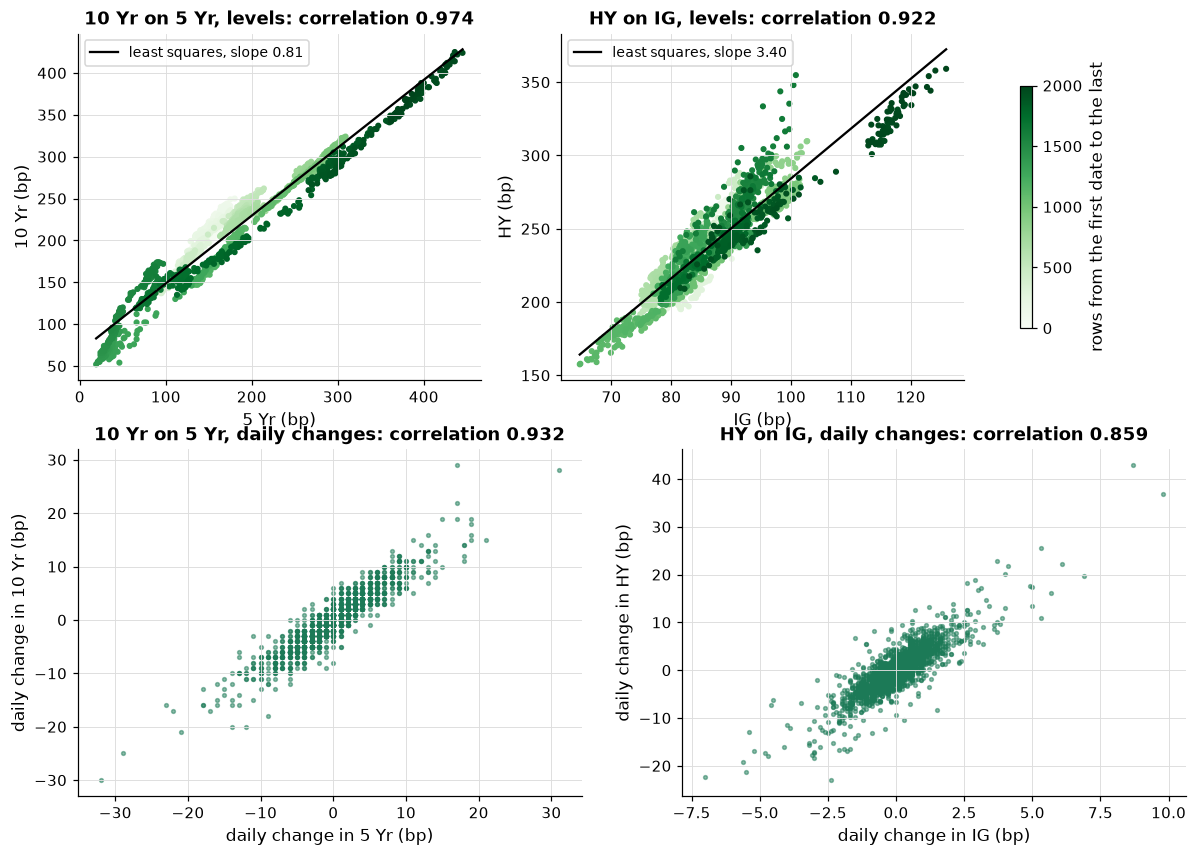

In [12]:
# top: each series against the other in levels, coloured by date, with the least-squares line; bottom: the same in daily changes
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for column, (name, (y, x)) in enumerate(pairs.items()):
    ax = axes[0, column]
    points = ax.scatter(levels[x], levels[y], c=np.arange(len(levels)), cmap="Greens", s=9)
    ratio_line, constant_line = np.polyfit(levels[x], levels[y], 1)
    grid_x = np.array([levels[x].min(), levels[x].max()])
    ax.plot(grid_x, constant_line + ratio_line * grid_x, color="black", linewidth=1.5, label=f"least squares, slope {ratio_line:.2f}")
    ax.set_xlabel(f"{x} (bp)")
    ax.set_ylabel(f"{y} (bp)")
    ax.set_title(f"{name}, levels: correlation {corr_table.loc[name, 'correlation of the levels']:.3f}")
    ax.legend(loc="upper left", fontsize=9)
    ax2 = axes[1, column]
    ax2.scatter(changes[x], changes[y], s=6, color=plotkit.GREEN, alpha=0.5)
    ax2.set_xlabel(f"daily change in {x} (bp)")
    ax2.set_ylabel(f"daily change in {y} (bp)")
    ax2.set_title(f"{name}, daily changes: correlation {corr_table.loc[name, 'correlation of the daily changes']:.3f}")
fig.colorbar(points, ax=axes[0, :], label="rows from the first date to the last", shrink=0.7)
plt.show()

* **Both pairs are highly correlated in levels, and in changes.** The 5 Yr and 10 Yr: 0.974 in levels and 0.932 in changes. The IG and HY spreads: 0.922 and 0.859. The changes are the better guide to how the two move together day to day.
* The colour in the top panels runs from early dates (light) to late (dark): the points drift along the line in a path, not a cloud. A level correlation of 0.97 is easy to get from two series that both trended in the same years.
* **High correlation does not decide cointegration.** The next sections test it, and the two pairs, equally correlated, answer differently.

## 9.2 The Hedge Ratio and the Gap

**How it works.** Fit a straight line of one series on the other, y = constant + ratio x, by least squares. The **ratio** is the slope: the number of bp y moved for each bp x moved, on average over the dates fitted. It is called the hedge ratio because it is the amount of x that moves with one unit of y. What is left over, **y less the line**, is the **gap** between the series: positive when y is above the line, negative when below. By construction its average is zero. If the gap keeps returning to its average, the pair is cointegrated, and the ratio is the one that makes the gap stable. You control which series is y and which is x; what comes out is the constant, the ratio, and the gap on every date.

Q. Write `hedge_ratio`. Read the docstring first.

In [13]:
%%writefile -a tskit.py


def hedge_ratio(y, x) -> tuple[float, float]:
    """The least-squares line of one series on another: the constant and the hedge ratio.

    Inputs: y and x, two arrays or Series of the same length (at least 10 values, no NaN): levels in bp, say. The line is
    y = constant + ratio x.
    Output: (constant, ratio). The ratio is the slope: how many bp y has moved for each bp x moved, on average over these
    rows. The gap between the series is y - constant - ratio x, which this function does not compute (the notebook does,
    so it can be drawn). The line is fitted to all the rows it is given: to describe a later stretch with an earlier fit,
    fit on the earlier rows and apply the numbers to the later ones.
    Raises ValueError for different lengths, fewer than 10 values, a NaN, or an x that does not vary.
    """
    y_values, x_values = np.asarray(y, dtype=float), np.asarray(x, dtype=float)
    if y_values.shape != x_values.shape or y_values.ndim != 1 or len(y_values) < 10:
        raise ValueError(f"need two arrays of one length, at least 10 values; got shapes {y_values.shape} and {x_values.shape}")
    if np.isnan(y_values).any() or np.isnan(x_values).any():
        raise ValueError("a blank in y or x: fill or drop it first (day 1)")
    if np.ptp(x_values) == 0:
        raise ValueError("x does not vary, so there is no slope to fit")
    ratio, constant = np.polyfit(x_values, y_values, 1)
    return float(constant), float(ratio)

Appending to tskit.py


* It returns the constant and the ratio, and does not compute the gap, so the notebook draws the gap itself from the two numbers. That is also how a ratio fitted on earlier dates is applied to later ones in section 9.5.
* It refuses two arrays of different lengths, a NaN, and an x that does not vary (there is no slope to fit).

Q. Write its tests: it recovers the line of a seeded pair, and the refusals.

In [14]:
%%writefile -a test_tskit.py


def pair_frame(rows: int = 800) -> pd.DataFrame:
    """Two seeded levels in bp: x a random walk, y = 5 + 0.8 x + an AR(1) gap with b = 0.9 (so the pair is cointegrated)."""
    rng = np.random.default_rng(3)
    x = 100.0 + np.cumsum(rng.standard_normal(rows))
    gap = np.zeros(rows)
    for row in range(1, rows):
        gap[row] = 0.9 * gap[row - 1] + rng.standard_normal()
    return pd.DataFrame({"x": x, "y": 5.0 + 0.8 * x + gap}, index=pd.bdate_range("2020-01-01", periods=rows))


def test_hedge_ratio_recovers_the_line():
    frame = pair_frame()
    constant, ratio = tskit.hedge_ratio(frame["y"], frame["x"])
    # 800 seeded rows: the line that made them is y = 5 + 0.8 x
    assert ratio == pytest.approx(0.8, abs=0.05) and constant == pytest.approx(5.0, abs=5.0)
    gap = frame["y"] - constant - ratio * frame["x"]
    assert gap.mean() == pytest.approx(0.0, abs=1e-9)


def test_hedge_ratio_refusals():
    frame = pair_frame(rows=50)
    with pytest.raises(ValueError, match="one length"):
        tskit.hedge_ratio(frame["y"].iloc[:30], frame["x"])
    flat = frame["x"].copy()
    flat[:] = 7.0
    with pytest.raises(ValueError, match="does not vary"):
        tskit.hedge_ratio(frame["y"], flat)
    blank = frame["y"].copy()
    blank.iloc[3] = np.nan
    with pytest.raises(ValueError, match="blank"):
        tskit.hedge_ratio(blank, frame["x"])

Appending to test_tskit.py


Q. Reload the modules and run the tests.

In [15]:
# the files changed, so reload before using the new function
importlib.reload(tskit)
print(f"hedge_ratio in tskit: {hasattr(tskit, 'hedge_ratio')}")

hedge_ratio in tskit: True


In [16]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_tskit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

................................................                         [100%]
48 passed in 5.48s



* `48 passed`: day 8's 46 and two new ones.

Q. Fit each pair's hedge ratio on all the development dates and draw the gap, with bands of its own standard deviation.

In [17]:
# the hedge ratio of each pair on all the development dates, and the gap between the series: y less the constant less the ratio times x
spreads, hedge_rows = {}, []
for name, (y, x) in pairs.items():
    constant, ratio = tskit.hedge_ratio(levels[y], levels[x])
    spread = levels[y] - constant - ratio * levels[x]
    spreads[name] = spread
    hedge_rows.append({"pair": name, "hedge ratio": ratio, "constant (bp)": constant, "sd of the gap (bp)": spread.std(),
                       "dates beyond 2 sd of the gap": int(((spread - spread.mean()).abs() > 2 * spread.std()).sum())})
hedge_table = pd.DataFrame(hedge_rows).set_index("pair")
print(hedge_table.round(4).to_string())

plotkit.styled(hedge_table, [], "The hedge ratio of each pair on all the development dates, and the gap between the series", fmt="{:.4f}")

               hedge ratio  constant (bp)  sd of the gap (bp)  dates beyond 2 sd of the gap
pair                                                                                       
10 Yr on 5 Yr       0.8104        67.5559             16.7163                            39
HY on IG            3.4020       -55.9266             12.8329                            60


,hedge ratio,constant (bp),sd of the gap (bp),dates beyond 2 sd of the gap
pair,,,,
10 Yr on 5 Yr,0.8104,67.5559,16.7163,39
HY on IG,3.4020,-55.9266,12.8329,60


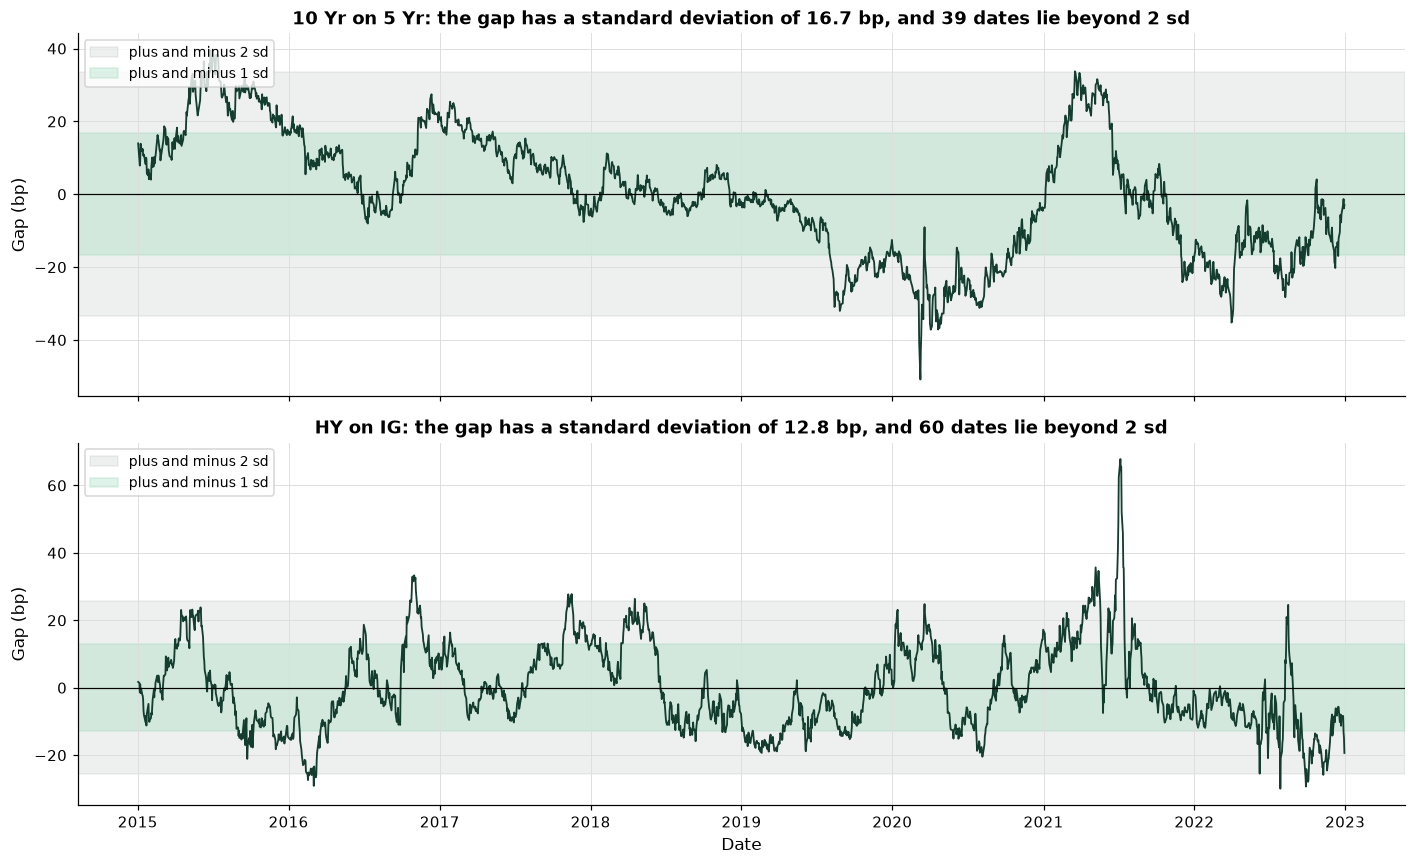

In [18]:
# the gap between the series for each pair, with bands of one and two standard deviations of its own: a description of the gap, not a rule
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for ax, (name, spread) in zip(axes, spreads.items()):
    sd = spread.std()
    ax.axhspan(-2 * sd, 2 * sd, color=plotkit.GREY, alpha=0.12, label="plus and minus 2 sd")
    ax.axhspan(-sd, sd, color=plotkit.GREEN_LIGHT, alpha=0.25, label="plus and minus 1 sd")
    ax.plot(spread.index, spread, color=plotkit.GREEN_DARK, linewidth=1.2)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_ylabel("Gap (bp)")
    ax.set_title(f"{name}: the gap has a standard deviation of {sd:.1f} bp, and {hedge_table.loc[name, 'dates beyond 2 sd of the gap']} dates lie beyond 2 sd")
    ax.legend(loc="upper left", fontsize=9)
axes[-1].set_xlabel("Date")
fig.tight_layout()
plt.show()

* **The 10 Yr on the 5 Yr:** a hedge ratio of 0.810, a constant of 67.6 bp, and a gap with a standard deviation of 16.7 bp. **The invented HY on the IG:** a ratio of 3.402, a constant of -55.9 bp, and a gap with a standard deviation of 12.8 bp.
* The bands are a way to see how big the gap was, in units of its own spread: 39 of 2,001 dates lie beyond two standard deviations for the first pair, and 60 for the second. They are a description of the gap over these years. They are not a rule for anything.
* Look at the **shape** of each gap, not its size. The first wanders for long stretches on one side of zero. The second crosses zero more often. That difference is what the test and the half-life quantify.

## 9.3 Engle-Granger: Do the Two Series Share a Level?

**How it works.** Two series are **cointegrated** if some mix of them, y less ratio times x, is stationary even though each series alone is not: they can wander, but not apart from each other. The **Engle-Granger** test has two steps. First fit the line of y on x, as in section 9.2. Then test the gap for a unit root with an augmented Dickey-Fuller test. The null hypothesis is "no cointegration", so a **small p-value rejects it**. One thing differs from day 3's ADF: the gap was **fitted**, by the line that makes it as small as possible, so it looks more stationary than a raw series would, and the ordinary ADF critical values are too lenient. Engle and Granger's test uses MacKinnon's stricter critical values, which statsmodels' `coint` applies. You control the trend and how the lags are chosen; what comes out is the test statistic, a p-value, and three critical values.

Q. Run `coint` on both pairs and both orders, beside the ordinary ADF p-value on the same gap.

In [19]:
from statsmodels.tsa.stattools import adfuller, coint

# Engle-Granger on both pairs and both orders, beside the ordinary ADF p-value on the same gap
orders = {"10 Yr on 5 Yr": ("10 Yr", "5 Yr"), "5 Yr on 10 Yr": ("5 Yr", "10 Yr"), "HY on IG": ("HY", "IG"), "IG on HY": ("IG", "HY")}
eg_rows = []
for name, (y, x) in orders.items():
    statistic, p_value, critical = coint(levels[y].to_numpy(), levels[x].to_numpy(), trend="c", autolag="aic")
    constant, ratio = tskit.hedge_ratio(levels[y], levels[x])
    naive = adfuller(levels[y] - constant - ratio * levels[x], regression="c", autolag="AIC", result_object=True).pvalue
    eg_rows.append({"pair": name, "Engle-Granger t": statistic, "p-value": p_value, "5% critical value": critical[1], "ordinary ADF p-value on the gap": naive})
eg_table = pd.DataFrame(eg_rows).set_index("pair")
print(eg_table.round(4).to_string())
rejects = [name for name in eg_table.index if eg_table.loc[name, "p-value"] < 0.05]
print(f"Engle-Granger rejects no cointegration at 5 percent for: {', '.join(rejects)}")

plotkit.styled(eg_table, [], "Engle-Granger on both pairs and both orders, with the ordinary ADF p-value on the same gap", fmt="{:.4f}")

               Engle-Granger t  p-value  5% critical value  ordinary ADF p-value on the gap
pair                                                                                       
10 Yr on 5 Yr          -2.1928   0.4281            -3.3392                           0.2091
5 Yr on 10 Yr          -1.9594   0.5496            -3.3392                           0.3056
HY on IG               -4.2353   0.0032            -3.3392                           0.0006
IG on HY               -3.8249   0.0126            -3.3392                           0.0027
Engle-Granger rejects no cointegration at 5 percent for: HY on IG, IG on HY


,Engle-Granger t,p-value,5% critical value,ordinary ADF p-value on the gap
pair,,,,
10 Yr on 5 Yr,-2.1928,0.4281,-3.3392,0.2091
5 Yr on 10 Yr,-1.9594,0.5496,-3.3392,0.3056
HY on IG,-4.2353,0.0032,-3.3392,0.0006
IG on HY,-3.8249,0.0126,-3.3392,0.0027


* **The 10 Yr on the 5 Yr: t = -2.19, p = 0.428.** The statistic is above the 5 percent critical value of -3.34, and the test does not reject "no cointegration". The two yields are highly correlated and the test does not find a stable gap.
* **The HY on the IG: t = -4.24, p = 0.0032.** Below the critical value: rejected. For the invented spreads the gap is stationary over these years.
* **The ordinary ADF p-value is smaller than the proper one in both pairs**: 0.209 against 0.428, and 0.0006 against 0.0032. It is the trap: running day 3's ADF on a fitted gap makes a pair look more cointegrated than it is. Use `coint`.
* **The order matters, a little.** Swapping y and x changes the regression: the p-value for the 5 Yr on the 10 Yr is 0.550, and for the IG on the HY 0.0126. Same verdicts here, different numbers.

## 9.4 Every Setting of `coint`

Q. Read every setting of `coint`, with the defaults taken from the installed statsmodels.

In [20]:
import inspect

coint_defaults = {name: p.default for name, p in inspect.signature(coint).parameters.items()}
coint_rows = [
    ("y0, y1", coint_defaults["y0"], "the two series: the first is regressed on the second", "swapping them changes the regression, so the p-value moves", "yes"),
    ("trend", coint_defaults["trend"], "the deterministic part of the regression: n none, c a constant, ct a constant and a time trend, ctt adds time squared", "ct and ctt let the gap drift in time before it is tested", "yes"),
    ("method", coint_defaults["method"], "the test: 'aeg', the augmented Engle-Granger", "the only one statsmodels offers", "no"),
    ("maxlag", coint_defaults["maxlag"], "the most lagged differences in the test regression: None picks from the sample size", "more lags absorb more autocorrelation and cost degrees of freedom", "no"),
    ("autolag", coint_defaults["autolag"], "how the number of lags is chosen: aic, bic, t-stat, or None for exactly maxlag", "bic picks fewer lags than aic", "yes"),
    ("return_results", coint_defaults["return_results"], "a flag from an older release", "leave it at the default", "no"),
]
coint_settings = pd.DataFrame(coint_rows, columns=["setting", "default", "what it controls", "changing it", "tune first"]).set_index("setting")
coint_settings["default"] = coint_settings["default"].map(repr)
coint_settings.loc["y0, y1", "default"] = "required"

plotkit.styled(coint_settings, [], "Every setting of coint: the defaults read from the installed statsmodels")

,default,what it controls,changing it,tune first
setting,,,,
"y0, y1",required,the two series: the first is regressed on the second,"swapping them changes the regression, so the p-value moves",yes
trend,'c',"the deterministic part of the regression: n none, c a constant, ct a constant and a time trend, ctt adds time squared",ct and ctt let the gap drift in time before it is tested,yes
method,'aeg',"the test: 'aeg', the augmented Engle-Granger",the only one statsmodels offers,no
maxlag,None,the most lagged differences in the test regression: None picks from the sample size,more lags absorb more autocorrelation and cost degrees of freedom,no
autolag,'aic',"how the number of lags is chosen: aic, bic, t-stat, or None for exactly maxlag",bic picks fewer lags than aic,yes
return_results,None,a flag from an older release,leave it at the default,no


* Three settings matter, marked "tune first": which series is y, `trend`, and `autolag`. The rest are fixed by the library.

Q. Sweep the trend and the way the lags are chosen, for both pairs, and draw every p-value.

In [21]:
# the p-value for every trend and lag choice, both pairs: rows are trends, columns are how the lags were chosen
trends = ["n", "c", "ct", "ctt"]
lag_choices = {"aic": dict(autolag="aic"), "bic": dict(autolag="bic"), "t-stat": dict(autolag="t-stat"), "4 lags": dict(autolag=None, maxlag=4)}
pvalues = {}
for name, (y, x) in pairs.items():
    grid = pd.DataFrame(index=pd.Index(trends, name="trend"), columns=pd.Index(list(lag_choices), name="lags chosen by"), dtype=float)
    for trend in trends:
        for label, settings in lag_choices.items():
            grid.loc[trend, label] = coint(levels[y].to_numpy(), levels[x].to_numpy(), trend=trend, **settings)[1]
    pvalues[name] = grid
below = {name: int((grid < 0.05).sum().sum()) for name, grid in pvalues.items()}
print(f"p-values below 0.05 of {pvalues['HY on IG'].size}: " + ", ".join(f"{name} {count}" for name, count in below.items()))
print(f"lowest and highest p-value, 10 Yr on 5 Yr: {pvalues['10 Yr on 5 Yr'].min().min():.4f} and {pvalues['10 Yr on 5 Yr'].max().max():.4f}")
print(f"lowest and highest p-value, HY on IG: {pvalues['HY on IG'].min().min():.4f} and {pvalues['HY on IG'].max().max():.4f}")

p-values below 0.05 of 16: 10 Yr on 5 Yr 0, HY on IG 15
lowest and highest p-value, 10 Yr on 5 Yr: 0.1682 and 0.7975
lowest and highest p-value, HY on IG: 0.0000 and 0.0794


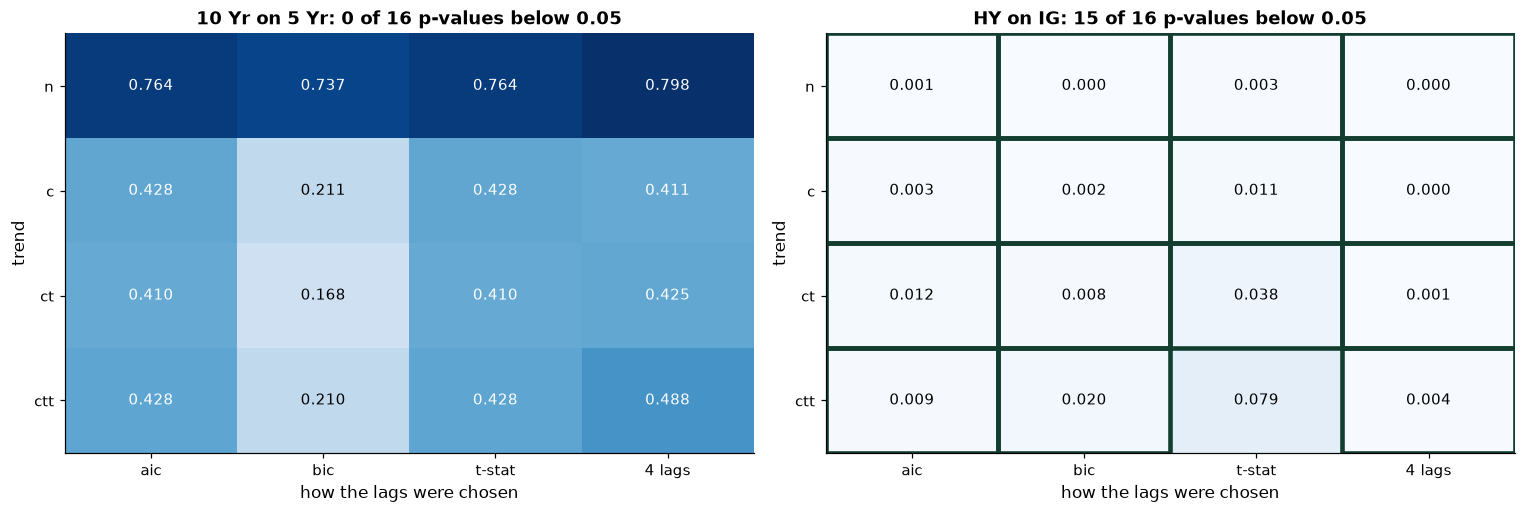

In [22]:
# the Engle-Granger p-value for every trend and lag choice: a darker cell is a larger p-value, and an outlined cell is below 0.05
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, (name, grid) in zip(axes, pvalues.items()):
    matrix = grid.to_numpy(dtype=float)
    ax.imshow(matrix, cmap="Blues", aspect="auto", vmin=0, vmax=0.8)
    for row in range(matrix.shape[0]):
        for column in range(matrix.shape[1]):
            dark = matrix[row, column] > 0.4
            ax.text(column, row, f"{matrix[row, column]:.3f}", ha="center", va="center", fontsize=10, color="white" if dark else "black")
            if matrix[row, column] < 0.05:
                ax.add_patch(plt.Rectangle((column - 0.5, row - 0.5), 1, 1, fill=False, edgecolor=plotkit.GREEN_DARK, linewidth=3))
    ax.set_xticks(range(matrix.shape[1]), list(grid.columns))
    ax.set_yticks(range(matrix.shape[0]), list(grid.index))
    ax.set_xlabel("how the lags were chosen")
    ax.set_ylabel("trend")
    ax.set_title(f"{name}: {int((matrix < 0.05).sum())} of {matrix.size} p-values below 0.05")
    ax.grid(False)
fig.tight_layout()
plt.show()

* How to read it: each cell is the p-value for a trend (down) and a lag choice (across), and an outlined cell is below 0.05. **For the 10 Yr on the 5 Yr, no cell is outlined**: the p-values run from 0.168 to 0.798, so the verdict does not depend on the setting. **For the HY on the IG, 15 of 16 are**: the p-values run from 0.0000 to 0.079, and only one setting, the time trend squared with lags chosen by the t-statistic, tips it above 0.05.
* A conclusion that survives every reasonable setting is worth more than one that needs a particular setting. Here the first pair's non-result and the second pair's result both do, nearly.

## 9.5 The Half-Life of the Gap

**How it works.** If a gap keeps returning to a level, how long does it take to cover half the distance? Fit an **AR(1)** to the gap: each value is a constant plus **b** times the value before, plus a shock. The distance from the level the gap pulls toward, c / (1 - b), shrinks by the factor b each row, so after k rows it is b to the power k of what it was. It has halved when b to the k equals one half: **k = ln(0.5) / ln(b)** rows. This is the same AR(1) as day 5, fitted to the gap. You control nothing but the series; what comes out is b and the half-life. The sign matters: **b must be between 0 and 1.** A b of 1 or more is a series that wanders or grows and has no level to return to, and a b of 0 or less flips sign every row; neither has a half-life.

Q. Write `half_life`, and its tests.

In [23]:
%%writefile -a tskit.py


def half_life(spread) -> float:
    """The number of rows in which a gap between two series closes by half, from an AR(1) fitted to the gap.

    Input: spread, an array or Series of the gap (at least 10 values, no NaN), in bp. Each value is regressed on the one
    before it: gap[t] = c + b x gap[t-1] + shock. A b below 1 pulls each value toward the level c / (1 - b), and the
    distance from that level shrinks by the factor b each row.
    Output: ln(0.5) / ln(b) rows, the number of rows in which the distance halves. At b = 0.9 it is 6.6 rows; at 0.98, 34.3.
    The sign check: b must be above 0 and below 1. A b of 1 or more is a series that wanders (or grows) and has no level
    to return to; a b of 0 or below changes sign every row. Both have no half-life.
    Raises ValueError for a b outside (0, 1), fewer than 10 values, or a NaN.
    """
    values = np.asarray(spread, dtype=float)
    if values.ndim != 1 or len(values) < 10 or np.isnan(values).any():
        raise ValueError("spread must be a one-dimensional array of at least 10 numbers with no blank")
    b, _ = np.polyfit(values[:-1], values[1:], 1)
    if not 0 < b < 1:
        raise ValueError(f"the slope on the row before is {b:.4f}: the series does not return toward a level, so it has no half-life")
    return float(np.log(0.5) / np.log(b))

Appending to tskit.py


* It refuses a b outside (0, 1) with a message that says what the slope was. A function that returned a number for a b of 1.02 would return a negative half-life, or a huge one, and nothing would look wrong.

Q. Write its tests: a seeded AR(1) with b = 0.9, and the refusals.

In [24]:
%%writefile -a test_tskit.py


def test_half_life_of_an_ar1():
    rng = np.random.default_rng(8)
    gap = np.zeros(4000)
    for row in range(1, 4000):
        gap[row] = 0.9 * gap[row - 1] + rng.standard_normal()
    # 4,000 seeded values: b is near 0.9, so the half-life is near ln(0.5) / ln(0.9) = 6.6 rows
    assert tskit.half_life(gap) == pytest.approx(np.log(0.5) / np.log(0.9), abs=1.0)
    assert tskit.half_life(pd.Series(gap)) == tskit.half_life(gap)


def test_half_life_refuses_a_series_that_does_not_revert():
    rng = np.random.default_rng(9)
    for b in (1.02, -0.5):
        values = np.zeros(300)
        for row in range(1, 300):
            values[row] = b * values[row - 1] + rng.standard_normal() * 0.1
        with pytest.raises(ValueError, match="no half-life"):
            tskit.half_life(values)
    with pytest.raises(ValueError, match="at least 10"):
        tskit.half_life(np.arange(5.0))

Appending to test_tskit.py


Q. Reload the modules and run the tests.

In [25]:
# the files changed, so reload before using the new function
importlib.reload(tskit)
print(f"half_life in tskit: {hasattr(tskit, 'half_life')}")

half_life in tskit: True


In [26]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_tskit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

..................................................                       [100%]
50 passed in 5.42s



* `50 passed`.

Q. Fit the AR(1) to each pair's gap by hand, and compare with `half_life`.

In [27]:
# the AR(1) of each gap on the row before, by hand, and the half-life
half_rows = []
for name, spread in spreads.items():
    b_hand, c_hand = np.polyfit(spread.iloc[:-1], spread.iloc[1:], 1)
    half_rows.append({"pair": name, "slope on the row before, b": b_hand, "level it pulls toward (bp)": c_hand / (1 - b_hand),
                      "half-life (rows)": tskit.half_life(spread), "ln(0.5) / ln(b), by hand": np.log(0.5) / np.log(b_hand),
                      "Engle-Granger p-value": eg_table.loc[name, "p-value"]})
half_table = pd.DataFrame(half_rows).set_index("pair")
print(half_table.round(4).to_string())

plotkit.styled(half_table, [], "The AR(1) of each pair's gap on the row before: b, the level it pulls toward, and the half-life", fmt="{:.4f}")

               slope on the row before, b  level it pulls toward (bp)  half-life (rows)  ln(0.5) / ln(b), by hand  Engle-Granger p-value
pair                                                                                                                                    
10 Yr on 5 Yr                      0.9931                     -1.2159           99.5919                   99.5919                 0.4281
HY on IG                           0.9804                     -0.5271           34.9771                   34.9771                 0.0032


,"slope on the row before, b",level it pulls toward (bp),half-life (rows),"ln(0.5) / ln(b), by hand",Engle-Granger p-value
pair,,,,,
10 Yr on 5 Yr,0.9931,-1.2159,99.5919,99.5919,0.4281
HY on IG,0.9804,-0.5271,34.9771,34.9771,0.0032


* **The 10 Yr on the 5 Yr:** b = 0.9931, a half-life of 99.6 rows. **The HY on the IG:** b = 0.9804, a half-life of 35.0 rows. Over these years the gap between the invented spreads closed by half every 35 trading days or so, and the gap between the Treasury yields every 100. `half_life` equals the formula by hand.
* **A half-life is not a test.** The first pair has a b below 1 and a half-life, and the Engle-Granger test did not find it cointegrated: a sample of a series that wanders can give a b slightly under 1. The half-life describes how fast the gap moved; the test says whether to believe it comes back at all.

Q. What does the sign check do? Give `half_life` a gap that grows 2 percent a row.

In [28]:
# the sign check: a gap that grows by 2 percent a row has b above 1, and half_life refuses it
rng = np.random.default_rng(SEED)
growing = np.zeros(300)
for row in range(1, 300):
    growing[row] = 1.02 * growing[row - 1] + rng.standard_normal() * 0.1
try:
    print(tskit.half_life(growing))
except ValueError as error:
    print(f"half_life refused: {error}")

half_life refused: the slope on the row before is 1.0201: the series does not return toward a level, so it has no half-life


* The function refuses and says why. A slope of 1.02 has no half-life: the gap does not return to anything.

Q. Draw four simulated gaps from one set of shocks, with b of 0.5, 0.9, 0.98, and 1.0.

In [29]:
# one set of shocks through four AR(1) gaps: b = 0.5, 0.9, 0.98, and 1.0 (a random walk); half_life on each
rng = np.random.default_rng(SEED)
shocks = rng.standard_normal(600)
b_values = [0.5, 0.9, 0.98, 1.0]
sim_gaps, sim_rows = {}, []
for b_true in b_values:
    gap = np.zeros(600)
    for row in range(1, 600):
        gap[row] = b_true * gap[row - 1] + shocks[row]
    sim_gaps[b_true] = gap
    b_found = np.polyfit(gap[:-1], gap[1:], 1)[0]
    try:
        found = tskit.half_life(gap)
    except ValueError:
        found = np.nan
    sim_rows.append({"true b": b_true, "b found": b_found, "half-life found (rows)": found,
                     "half-life of the true b (rows)": np.log(0.5) / np.log(b_true) if b_true < 1 else np.nan})
sim_table = pd.DataFrame(sim_rows).set_index("true b")
print(sim_table.round(3).to_string())

plotkit.styled(sim_table, [], "Four simulated gaps from the same 600 shocks: the b used, the b found, and the half-life found and true", fmt="{:.3f}")

        b found  half-life found (rows)  half-life of the true b (rows)
true b                                                                 
0.50      0.539                   1.120                           1.000
0.90      0.877                   5.279                           6.579
0.98      0.958                  15.981                          34.310
1.00      0.979                  33.357                             NaN


,b found,half-life found (rows),half-life of the true b (rows)
true b,,,
0.5,0.539,1.120,1.000
0.9,0.877,5.279,6.579
0.98,0.958,15.981,34.310
1,0.979,33.357,


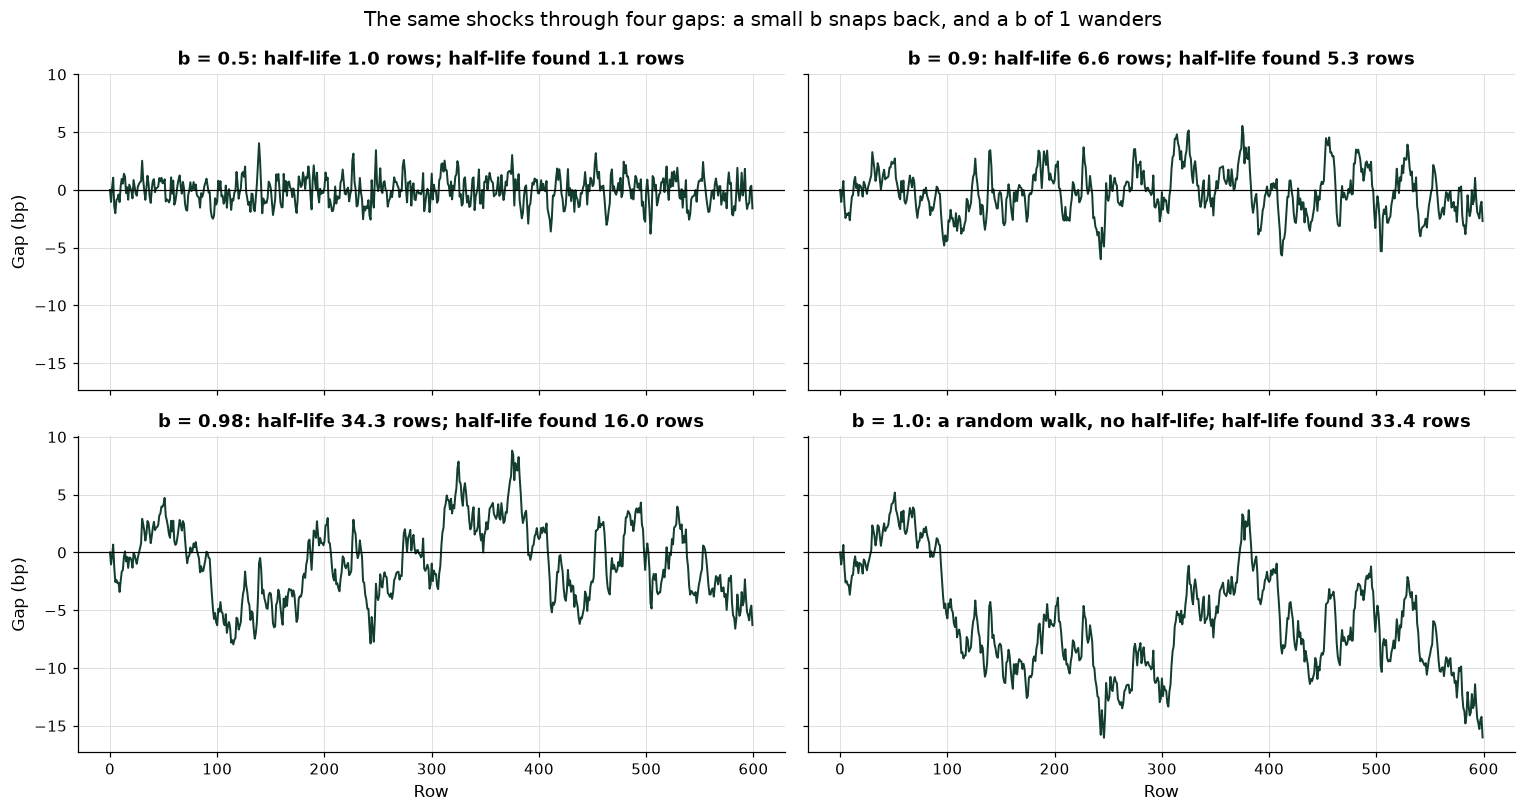

In [30]:
# one set of shocks through four AR(1) gaps: the closer b is to 1, the longer a gap takes to come back
fig, axes = plt.subplots(2, 2, figsize=(14, 7.5), sharex=True, sharey=True)
for ax, (b_true, gap) in zip(axes.ravel(), sim_gaps.items()):
    ax.plot(gap, color=plotkit.GREEN_DARK, linewidth=1.3)
    ax.axhline(0, color="black", linewidth=0.8)
    found = sim_table.loc[b_true, "half-life found (rows)"]
    verdict = f"half-life found {found:.1f} rows" if found == found else "no half-life"
    ax.set_title(f"b = {b_true}: " + (f"half-life {sim_table.loc[b_true, 'half-life of the true b (rows)']:.1f} rows" if b_true < 1 else "a random walk, no half-life") + f"; {verdict}")
for ax in axes[1]:
    ax.set_xlabel("Row")
for ax in axes[:, 0]:
    ax.set_ylabel("Gap (bp)")
fig.suptitle("The same shocks through four gaps: a small b snaps back, and a b of 1 wanders")
fig.tight_layout()
plt.show()

* How to read it: a small b snaps back within a few rows, b = 0.9 returns in about 7 rows, b = 0.98 wanders for months before it returns (34-row half-life), and b = 1 is a random walk that has no level to return to. **The closer b is to 1, the longer the memory and the less the gap is pulled.**
* The last panel is the warning. A random walk, with a true b of exactly 1, gave a **found b of 0.979** from 600 rows: close enough to 1 that a half-life is computed, and a long one. A sample cannot tell b = 0.998 from b = 1.

## 9.6 The Ratio Over Time, and the Next Fold

**How it works.** Every number so far used all the development dates, to describe those years. A relationship is only worth describing if it holds on dates the fit did not see. Two views check that. A **rolling hedge ratio** refits the line on the last 252 dates for every date: it shows whether the ratio is a constant or a path. And the **fold view** uses day 2's folds: fit the ratio on a fold's training dates, build the gap on the **next** dates with that training fit (the constant and the ratio, applied to dates they were not fitted on), and ask whether that gap still returns to a level: its AR(1) slope, and its half-life if it has one. You control the window and the folds; what comes out is a ratio over time and a table by fold.

Q. Add `rolling_hedge_ratio`, and its test.

In [31]:
%%writefile -a tskit.py


def rolling_hedge_ratio(y: pd.Series, x: pd.Series, window: int) -> pd.Series:
    """The hedge ratio of y on x over the last `window` rows, on every date.

    Inputs: y and x, dated Series of levels in bp on the same dates, with no NaN; window, a whole number of 20 or more.
    Output: a Series on the same dates: the slope of y on x fitted to the `window` rows that end on the date (covariance of
    the two over the variance of x), NaN for the first window - 1 rows. The window includes the date itself, so this
    describes how the relationship stood on each date; it is not a value to score a later date with.
    Raises ValueError for different dates, a window below 20, or a NaN.
    """
    if not y.index.equals(x.index):
        raise ValueError("y and x must be on the same dates")
    if int(window) != window or window < 20:
        raise ValueError(f"window must be a whole number of 20 or more; got {window}")
    if y.isna().any() or x.isna().any():
        raise ValueError("a blank in y or x: fill or drop it first (day 1)")
    return y.rolling(window).cov(x) / x.rolling(window).var()

Appending to tskit.py


In [32]:
%%writefile -a test_tskit.py


def test_rolling_hedge_ratio_equals_a_fit_on_each_window():
    frame = pair_frame(rows=300)
    rolling = tskit.rolling_hedge_ratio(frame["y"], frame["x"], 60)
    assert rolling.iloc[:59].isna().all()
    for row in (59, 150, 299):
        window = frame.iloc[row - 59:row + 1]
        assert rolling.iloc[row] == pytest.approx(tskit.hedge_ratio(window["y"], window["x"])[1], abs=1e-9)
    with pytest.raises(ValueError, match="20 or more"):
        tskit.rolling_hedge_ratio(frame["y"], frame["x"], 5)

Appending to test_tskit.py


* The window ends on the date and includes it: this describes how the relationship stood on each date, and is never a value to score a later date with. Section 9.6's fold view is the walk-forward version.

Q. Reload the modules and run the tests.

In [33]:
# the files changed, so reload before using the new function
importlib.reload(tskit)
print(f"rolling_hedge_ratio in tskit: {hasattr(tskit, 'rolling_hedge_ratio')}")

rolling_hedge_ratio in tskit: True


In [34]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_tskit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

...................................................                      [100%]
51 passed in 7.35s



* `51 passed`: day 8's 46 and today's five.

Q. Draw the hedge ratio over a rolling window of 252 dates, with the ratio fitted on each fold's training dates.

In [35]:
# the hedge ratio over a rolling window of 252 dates, and the ratios fitted on each fold's training dates
rolling_ratio = {name: tskit.rolling_hedge_ratio(levels[y], levels[x], 252) for name, (y, x) in pairs.items()}
for name, series in rolling_ratio.items():
    print(f"{name}: rolling hedge ratio from {series.min():.3f} to {series.max():.3f}; on all development dates {hedge_table.loc[name, 'hedge ratio']:.3f}")

10 Yr on 5 Yr: rolling hedge ratio from 0.396 to 1.815; on all development dates 0.810
HY on IG: rolling hedge ratio from 2.378 to 5.651; on all development dates 3.402


In [36]:
# fit the ratio on a fold's training dates, build the gap on the training dates and on the next dates with that fit, and ask whether the next gap still reverts
fold_rows = []
for name, (y, x) in pairs.items():
    for number, (train, test) in enumerate(splits, start=1):
        constant, ratio = tskit.hedge_ratio(levels[y].iloc[train], levels[x].iloc[train])
        gap_train = levels[y].iloc[train] - constant - ratio * levels[x].iloc[train]
        gap_next = levels[y].iloc[test] - constant - ratio * levels[x].iloc[test]
        b_next = np.polyfit(gap_next.iloc[:-1], gap_next.iloc[1:], 1)[0]
        half_next = tskit.half_life(gap_next) if 0 < b_next < 1 else np.nan
        fold_rows.append({"pair": name, "fold": number, "hedge ratio on the training dates": ratio, "sd of the gap, training (bp)": gap_train.std(),
                          "sd of the gap, next dates (bp)": gap_next.std(), "half-life, training (rows)": tskit.half_life(gap_train),
                          "b, next dates": b_next, "half-life, next dates (rows)": half_next})
fold_table = pd.DataFrame(fold_rows).set_index(["pair", "fold"])
print(fold_table.round(3).to_string())
reverts = {name: int(fold_table.loc[name, "half-life, next dates (rows)"].notna().sum()) for name in pairs}
print(f"folds where the next dates' gap still reverted, of {len(splits)}: " + ", ".join(f"{name} {count}" for name, count in reverts.items()))

                    hedge ratio on the training dates  sd of the gap, training (bp)  sd of the gap, next dates (bp)  half-life, training (rows)  b, next dates  half-life, next dates (rows)
pair          fold                                                                                                                                                                          
10 Yr on 5 Yr 1                                 1.162                         7.499                          10.469                      21.505          1.004                           NaN
              2                                 0.872                        10.087                           3.786                      69.024          0.948                        13.055
              3                                 0.741                         9.852                          11.486                      43.543          0.989                        64.546
              4                                 0.765  

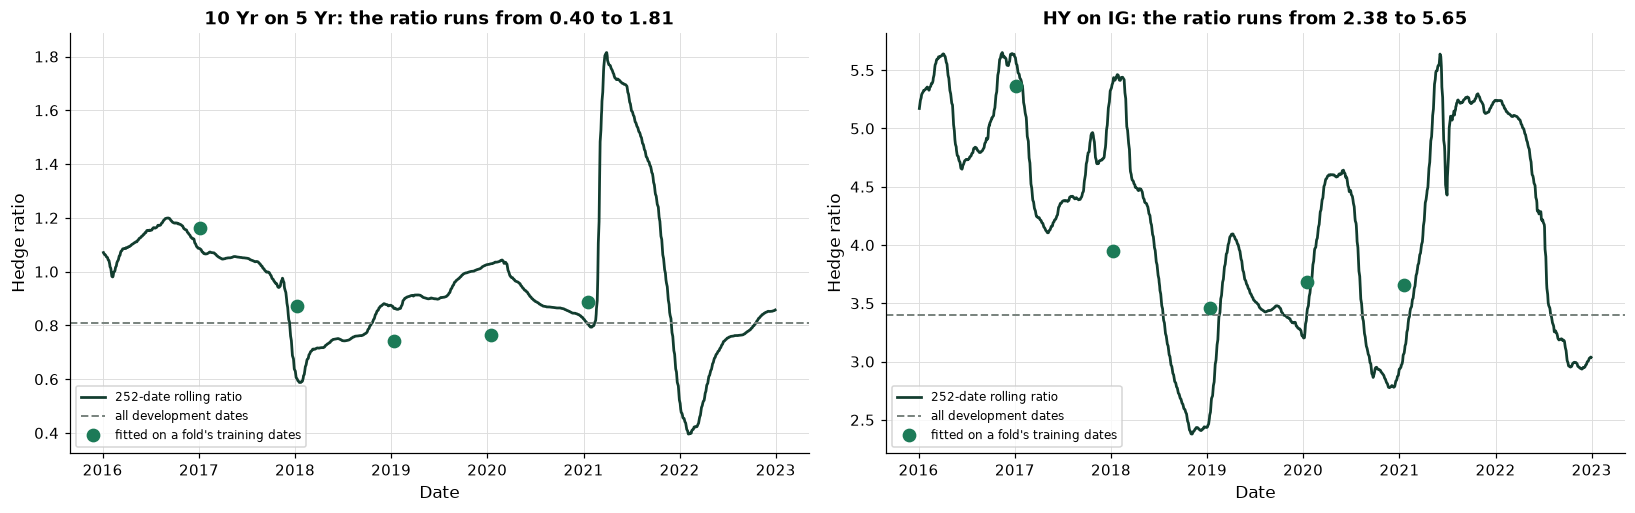

In [37]:
# the hedge ratio over a rolling window of 252 dates (a line), and the ratio fitted on each fold's training dates (a dot at the end of the training window)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, (name, series) in zip(axes, rolling_ratio.items()):
    ax.plot(series.index, series, color=plotkit.GREEN_DARK, linewidth=1.8, label="252-date rolling ratio")
    ax.axhline(hedge_table.loc[name, "hedge ratio"], color=plotkit.GREY, linestyle="--", linewidth=1.3, label="all development dates")
    fold_dates = [levels.index[train[-1]] for train, _ in splits]
    ax.plot(fold_dates, fold_table.loc[name, "hedge ratio on the training dates"], "o", color=plotkit.GREEN, markersize=8, label="fitted on a fold's training dates")
    ax.set_xlabel("Date")
    ax.set_ylabel("Hedge ratio")
    ax.set_title(f"{name}: the ratio runs from {series.min():.2f} to {series.max():.2f}")
    ax.legend(loc="lower left", fontsize=8)
fig.tight_layout()
plt.show()

* **The ratio is a path, not a constant.** The 5 Yr and 10 Yr ratio runs from 0.40 to 1.81 over rolling 252-date windows, against 0.81 on all the dates. The invented HY on IG ratio runs from 2.38 to 5.65, against 3.40. The dots are the ratios the fold view fits: 0.74 to 1.16 for the first pair and 3.46 to 5.36 for the second.
* A hedge ratio fitted on one stretch is **a description of that stretch**. Applied to the next, it is a different line from the one the next stretch would give.

Q. Read the fold table, and draw the half-life on the training dates against the half-life on the next dates.

In [38]:
plotkit.styled(fold_table, ["half-life, next dates (rows)"], "Each fold: the ratio fitted on its training dates, and whether the gap on the next dates still reverted", higher_is_better=False, fmt="{:.3f}")

<styled table: Each fold: the ratio fitted on its training dates, and whether the gap on the next dates still reverted>

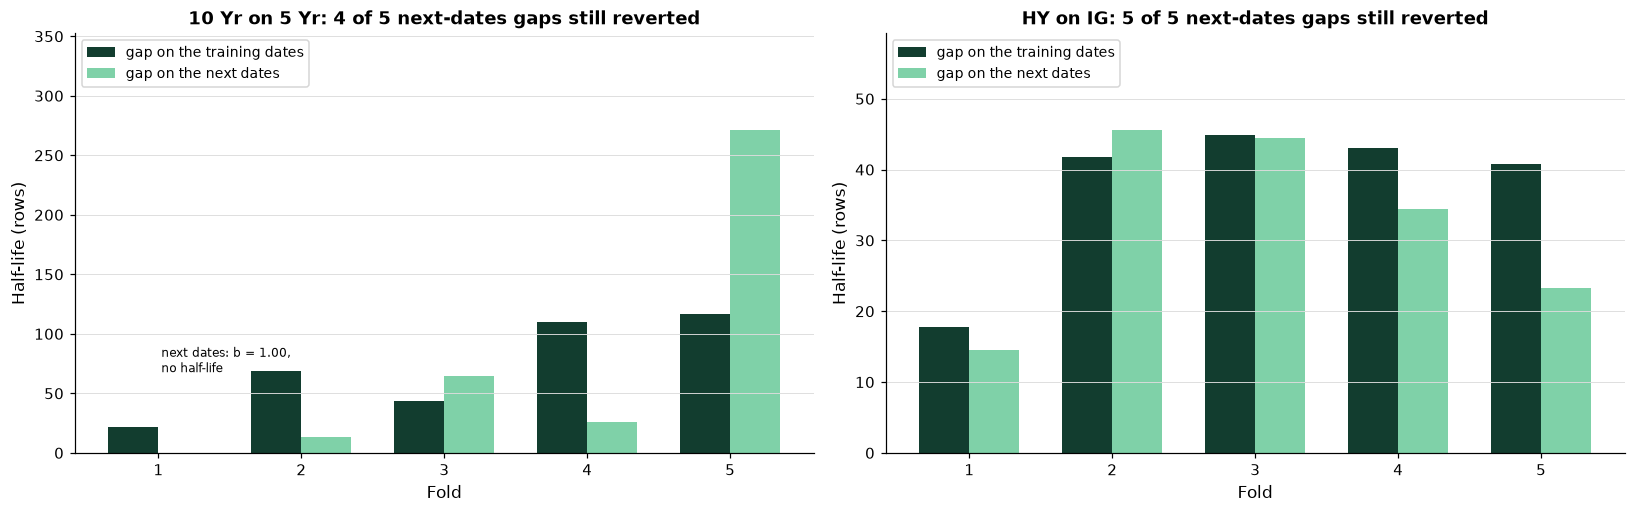

In [39]:
# the half-life of the gap on a fold's training dates, and of the gap on the next dates built with the training fit; a missing bar means no half-life
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
width = 0.35
for ax, name in zip(axes, pairs):
    table = fold_table.loc[name]
    positions = table.index.to_numpy()
    ax.bar(positions - width / 2, table["half-life, training (rows)"], width, color=plotkit.GREEN_DARK, label="gap on the training dates")
    ax.bar(positions + width / 2, table["half-life, next dates (rows)"].fillna(0), width, color=plotkit.GREEN_LIGHT, label="gap on the next dates")
    top = max(table["half-life, training (rows)"].max(), table["half-life, next dates (rows)"].max())
    ax.set_ylim(0, top * 1.3)
    for position, value, b_next in zip(positions, table["half-life, next dates (rows)"], table["b, next dates"]):
        if value != value:
            ax.text(position + 0.02, top * 0.25, f"next dates: b = {b_next:.2f},\nno half-life", ha="left", fontsize=8)
    ax.set_xlabel("Fold")
    ax.set_ylabel("Half-life (rows)")
    ax.set_title(f"{name}: {int(table['half-life, next dates (rows)'].notna().sum())} of 5 next-dates gaps still reverted")
    ax.set_xticks(positions)
    ax.grid(axis="x", visible=False)
    ax.legend(loc="upper left", fontsize=9)
fig.tight_layout()
plt.show()

* **The HY on the IG: the gap on the next dates reverted in 5 of 5 folds**, with half-lives of 14, 46, 44, 34, 23 rows, against 18, 42, 45, 43, 41 on the training dates. The half-life moved a good deal from fold to fold, and the gap kept returning.
* **The 10 Yr on the 5 Yr: the gap on the next dates reverted in 4 of 5 folds**, with half-lives of 13, 65, 26, 271 rows against 22, 69, 44, 110, 117 on the training dates. In the fold where it did not, the slope was 1 or above, so `half_life` has nothing to return (the bar is missing and the slope is printed). The half-lives ranged from 13 to 271 rows: the relationship that the full-sample half-life of 100 rows describes did not hold evenly in every later stretch.
* This is the walk-forward version of the question, on the same folds as every other day. It describes how the pair behaved on dates the ratio was not fitted on. It is not a statement about any date after 2022-12-30.

## What These Numbers Describe, and What They Do Not

**What they describe.** Over 2015-01-02 to 2022-12-30, the 10 Yr and 5 Yr yields moved together with a correlation of 0.93 in daily changes and a hedge ratio of 0.81, and the test did not find them cointegrated (p = 0.43). The gap between the invented HY and IG spreads closed at a half-life of 35 trading days over these years, and the test found it cointegrated (p = 0.0032). On the next fold's dates it reverted in 5 of 5 folds, with a half-life that ranged from 14 to 46 rows.

**What they do not.** They are not a forecast that a gap will close, and not a view that a gap is wide or narrow. The bands drawn at one and two standard deviations describe how big the gap was, in units of its own spread, and say nothing about what anyone should do. A cointegration test rejects "no cointegration" for a stretch of dates; the relationship can and did change between stretches (the rolling ratio, and the fold table). The invented spreads were made by a generator that ties them together, so the test finding them cointegrated says the generator did its job.

**What was not tested.** Other pairs, other windows, a refitted ratio at every date, the Johansen test for more than two series, a gap in logs, and the held-out years, which stay closed until the capstone.

## Excel Side by Side

**Excel does the regression and the half-life, and not the tests.** A hedge ratio is `SLOPE`, the constant is `INTERCEPT`, the gap is a column of one formula, the AR(1) slope is `SLOPE` of the gap on the gap one row up, and the half-life is `LN(0.5)/LN(b)`. Excel has no augmented Dickey-Fuller test and no Engle-Granger test, so the p-values stay in Python. Each formula below was typed into Excel by script (Excel 16.0 build 20430, 2026-10-21) on the 2,001 development dates in bp: the 5 Yr in B, the 10 Yr in C, the IG in D, the HY in E.

| Job | Python | Excel (10 Yr on 5 Yr) | Excel returned |
| --- | --- | --- | --- |
| The hedge ratio | `hedge_ratio(y, x)` | `=SLOPE(C2:C2002,B2:B2002)` | 0.8104 |
| The constant | `hedge_ratio(y, x)` | `=INTERCEPT(C2:C2002,B2:B2002)` | 67.5559 bp |
| The gap, a column | `y - constant - ratio * x` | `=C2-($M$2+$M$1*B2)`, filled down | its standard deviation `=STDEV.S(F2:F2002)`: 16.7163 bp |
| Dates beyond 2 sd | `(abs(gap - gap.mean()) > 2 * gap.std()).sum()` | `=SUMPRODUCT(--(ABS(F2:F2002-AVERAGE(F2:F2002))>2*M3))` | 39 |
| The AR(1) slope of the gap | `np.polyfit(gap[:-1], gap[1:], 1)[0]` | `=SLOPE(F3:F2002,F2:F2001)` | 0.993064 |
| The half-life | `half_life(gap)` | `=LN(0.5)/LN(M4)` | 99.5919 rows |
| Correlation of the levels | `y.corr(x)` | `=CORREL(B2:B2002,C2:C2002)` | 0.9741 |
| Correlation of the daily changes | `changes[y].corr(changes[x])` | `=CORREL(H3:H2002,I3:I2002)` | 0.9316 |

**The gap is a column and the half-life is a cell.** Put the ratio and the constant in two cells, write the gap as `=C2-($M$2+$M$1*B2)` with `$` signs holding them fixed, and fill down. The AR(1) slope is `SLOPE` of the gap from row 3 down against the gap from row 2 down: the value on a row against the value on the row before. Then `=LN(0.5)/LN(M4)`. The HY on the IG is the same with column E on column D: a ratio of 3.4020, a b of 0.980378, and a half-life of **35.0 rows**. Change the ratio by hand and watch the gap and the half-life move: the quickest way to see that the half-life belongs to one ratio.

**What Excel cannot do** is the cointegration test. The p-value of Engle-Granger comes from MacKinnon's tables, which no cell function holds, and the ordinary ADF p-value is the wrong one for a fitted gap. Say so on a sheet: the half-life is a description, and the test is a separate question.

Q. Do Excel's values equal Python's?

In [40]:
# Excel's results, from the course's Excel check, beside Python's, for both pairs
excel_side = pd.DataFrame({
    "Excel": [0.8104461148431464, 0.9930642921047911, 99.59194786358763, 3.4020207607672486, 0.9803778869566186, 34.97707978125243],
    "Python": [hedge_table.loc["10 Yr on 5 Yr", "hedge ratio"], half_table.loc["10 Yr on 5 Yr", "slope on the row before, b"], half_table.loc["10 Yr on 5 Yr", "half-life (rows)"],
               hedge_table.loc["HY on IG", "hedge ratio"], half_table.loc["HY on IG", "slope on the row before, b"], half_table.loc["HY on IG", "half-life (rows)"]],
}, index=pd.Index(["10 Yr on 5 Yr: hedge ratio", "10 Yr on 5 Yr: AR(1) slope b", "10 Yr on 5 Yr: half-life (rows)",
                   "HY on IG: hedge ratio", "HY on IG: AR(1) slope b", "HY on IG: half-life (rows)"], name="Quantity"))
excel_side["equal within 1e-8"] = (excel_side["Excel"] - excel_side["Python"]).abs() < 1e-8
plotkit.styled(excel_side, [], "Excel beside Python for both pairs: the hedge ratio, the AR(1) slope of the gap, and the half-life", fmt="{:.6f}")

,Excel,Python,equal within 1e-8
Quantity,,,
10 Yr on 5 Yr: hedge ratio,0.810446,0.810446,True
10 Yr on 5 Yr: AR(1) slope b,0.993064,0.993064,True
10 Yr on 5 Yr: half-life (rows),99.591948,99.591948,True
HY on IG: hedge ratio,3.402021,3.402021,True
HY on IG: AR(1) slope b,0.980378,0.980378,True
HY on IG: half-life (rows),34.977080,34.977080,True


* Every quantity is equal to within 1e-8.

## Save the Day with Git

Today's Git step is searching the history for a value. A results file changes over several commits, and `git log -S` finds the commit in which a given piece of text first appeared or disappeared.

Q. Start a repository in the work folder, and commit the code.

In [41]:
# stop here, with the steps to install it, if Git is not on this machine
if shutil.which("git") is None:
    raise RuntimeError("Git is not installed. Install Git for Windows from https://git-scm.com/downloads "
                       "(or run  winget install --id Git.Git  where your firm allows it), restart VS Code, "
                       "and run this cell again. Colab has Git already.")

# -C "{work}" points every Git command at the work folder, whatever folder the notebook is in
!git -C "{work}" --version
# make the work folder a repository
!git -C "{work}" init -q -b main
# settings for this repository only: a course name, a reserved example email, line endings left as they are,
# and no commit signing, so a signing setup on your machine does not ask for a key here
!git -C "{work}" config user.name "Course Student"
!git -C "{work}" config user.email "student@example.com"
!git -C "{work}" config core.autocrlf false
!git -C "{work}" config commit.gpgsign false

git version 2.50.1.windows.1


Q. Is Git working in the work folder, and only there?

In [42]:
# the guard: Git must report the work folder as the top of this repository, or the notebook stops
top = subprocess.run(["git", "-C", str(work), "rev-parse", "--show-toplevel"],
                     capture_output=True, text=True, check=True).stdout.strip()
assert os.path.samefile(top, work), "Git is not working in the work folder. Stop, and run the setup cell again."
print(f"Git is working in {work.name} and nowhere else")

Git is working in pfi_course5b_09_o07l31a8 and nowhere else


In [43]:
%%writefile .gitignore
__pycache__/
.pytest_cache/
*.xlsx

Writing .gitignore


In [44]:
!git -C "{work}" add .gitignore mlkit.py tskit.py test_tskit.py
!git -C "{work}" commit -q -m "Day 9: tskit with hedge_ratio, half_life, and rolling_hedge_ratio"
!git -C "{work}" show --stat --format=%s HEAD

Day 9: tskit with hedge_ratio, half_life, and rolling_hedge_ratio

 .gitignore    |   3 +
 mlkit.py      | 568 +++++++++++++++++++++++++++++++++++++++++++++
 test_tskit.py | 635 ++++++++++++++++++++++++++++++++++++++++++++++++++
 tskit.py      | 735 ++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
 4 files changed, 1941 insertions(+)


Q. Save the two hedge ratios and commit them.

In [45]:
# the two pairs' hedge ratios as a file: 4 decimals and LF line endings
pair_results = hedge_table[["hedge ratio"]].round(4).rename(columns={"hedge ratio": "hedge_ratio"})
pair_results.to_csv("pair_results.csv", lineterminator="\n")
print((work / "pair_results.csv").read_text(encoding="utf-8"))

pair,hedge_ratio
10 Yr on 5 Yr,0.8104
HY on IG,3.402



In [46]:
!git -C "{work}" add pair_results.csv
!git -C "{work}" commit -q -m "Day 9: hedge ratios"

Q. Add the half-lives to the same file, and commit again.

In [47]:
# the same file with the half-lives added as a second column
pair_results["half_life_rows"] = half_table["half-life (rows)"].round(1)
pair_results.to_csv("pair_results.csv", lineterminator="\n")
pickaxe = f"{half_table.loc['HY on IG', 'half-life (rows)']:.1f}"
print((work / "pair_results.csv").read_text(encoding="utf-8"))
print(f"searching the history for the text {pickaxe}")

pair,hedge_ratio,half_life_rows
10 Yr on 5 Yr,0.8104,99.6
HY on IG,3.402,35.0

searching the history for the text 35.0


In [48]:
!git -C "{work}" add pair_results.csv
!git -C "{work}" commit -q -m "Day 9: add the half-lives"

Q. In which commit did the HY on IG half-life first appear?

In [49]:
# -S finds the commits that changed the number of times the text appears in the file
!git -C "{work}" log --oneline -S{pickaxe} -- pair_results.csv

84cfa02 Day 9: add the half-lives


* `log -S` lists only the second commit: the text was not in the file before it. A line of results is something you can ask Git about.

## Bring It Home

Add today's functions to your own `my_bondmath` folder. Open a PowerShell terminal in VS Code.

**Step 1.** Go to your folder and activate the course's environment.

```powershell
Set-Location "$HOME\projects\python-fixed-income"
.\.venv\Scripts\Activate.ps1
Set-Location "$HOME\projects\my_bondmath"
```

**Step 2.** Open `tskit.py` and paste the code of today's three `tskit.py` cells (sections 9.2, 9.5, and 9.6) at the end, without their first lines. Do the same for the three `test_tskit.py` cells in `test_tskit.py`. Save both.

**Step 3.** Run the tests.

```powershell
python -m pytest -q test_tskit.py
```

The last line says `51 passed`.

**Step 4.** Commit.

```powershell
git add tskit.py test_tskit.py
git commit -m "Day 9: tskit with hedge_ratio, half_life, and rolling_hedge_ratio"
```

## You Can Now

* Compare the correlation of two series' levels with the correlation of their changes, and say why neither settles whether two series share a level.
* Fit a hedge ratio, draw the gap, and describe it with bands of its own standard deviation without calling it anything but a description.
* Test a pair for cointegration with `coint`, say why the ordinary ADF p-value on a fitted gap is the wrong one, read every setting, and sweep the trend and the lag choice.
* Measure a half-life from an AR(1) on the gap, check the sign of b, and say why a half-life is not a test.
* Read a rolling hedge ratio, and ask fold by fold whether the gap on the next dates still reverted.
* Say plainly what was found: the 5 Yr and 10 Yr were not found cointegrated (p = 0.43), and the invented IG and HY spreads were (p = 0.0032), with a half-life of 35 trading days over these years; and the gap reverted on the next dates in 5 of 5 folds for the second pair and 4 for the first.

Next, week 2, day 5: the Course 5B capstone, the whole workflow on two series, with the held-out years opened once.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`. Give each exercise a real try first, then check your work against it.

Replace each `...` with your own code, then run the check cell.

Q. Run the next cell first. It loads the four series, makes day 2's five folds (`splits`), the daily changes, and the two pairs (`pairs`), and defines `check`, a small function that marks your answers.

In [50]:
# the Treasury curve (percent) and the course's synthetic spreads (bp): one row per date, the same dates in both files
treasury = pd.read_csv("treasury_par_yields.csv", parse_dates=["date"]).set_index("date")
spreads = pd.read_csv("course3_synthetic_spreads.csv", parse_dates=["date"]).set_index("date")
print(f"Treasury file: {len(treasury):,} dates; spread file: {len(spreads):,} dates; same dates: {treasury.index.equals(spreads.index)}")

# the development and held-out years, set now, before any model is fitted
DEVELOPMENT_END = "2022-12-30"
development = treasury.loc[:DEVELOPMENT_END]
dev_spreads = spreads.loc[:DEVELOPMENT_END]
held_out_dates = treasury.index[treasury.index > DEVELOPMENT_END]
print(f"development years: {len(development):,} dates, {development.index[0].date()} to {development.index[-1].date()}")
print(f"held-out years: {len(held_out_dates):,} dates, {held_out_dates[0].date()} to {held_out_dates[-1].date()}, not opened until the capstone")

# four series, all in bp: yields times 100 (rounded to the file's two decimals of a percent), spreads as they are
levels = pd.DataFrame({
    "5 Yr": (development["5 Yr"] * 100).round(2),
    "10 Yr": (development["10 Yr"] * 100).round(2),
    "IG": dev_spreads["ig_spread_bp"],
    "HY": dev_spreads["hy_spread_bp"],
})
# nothing below reads a held-out row: drop the full tables
del treasury, spreads, development, dev_spreads
print(f"four series in bp: {list(levels.columns)}; blank cells: {int(levels.isna().sum().sum())}")

# the walk-forward windows of section 2.5: fit on 504 dates first, then score 252 at a time
MIN_TRAIN, TEST_SIZE = 504, 252
# day 2's five folds on the levels, and the two pairs: each is (the series to be described, the series it is described by)
splits = mlkit.walk_forward_splits(levels.index, min_train=MIN_TRAIN, test_size=TEST_SIZE)
for number, (train, test) in enumerate(splits, start=1):
    mlkit.assert_past_only(levels.index[train], levels.index[test])
    print(f"fold {number}: fit on {len(train)} dates to {levels.index[train[-1]].date()}, "
          f"describe {len(test)} from {levels.index[test[0]].date()} to {levels.index[test[-1]].date()}")
changes = levels.diff().dropna()
pairs = {"10 Yr on 5 Yr": ("10 Yr", "5 Yr"), "HY on IG": ("HY", "IG")}


def check(label, answer, expected):
    """Compare an exercise answer with the expected value and print the result."""
    if answer is ...:
        print(f"{label}: not attempted yet")
        return
    if isinstance(expected, float):
        # numbers with a decimal point: within a small tolerance
        correct = abs(answer - expected) < 1e-6
    else:
        correct = answer == expected
    if correct:
        print(f"{label}: correct")
    else:
        print(f"{label}: not yet. You have {answer}.")

Treasury file: 2,940 dates; spread file: 2,940 dates; same dates: True
development years: 2,001 dates, 2015-01-02 to 2022-12-30
held-out years: 939 dates, 2023-01-03 to 2026-10-02, not opened until the capstone
four series in bp: ['5 Yr', '10 Yr', 'IG', 'HY']; blank cells: 0
fold 1: fit on 504 dates to 2017-01-05, describe 252 from 2017-01-06 to 2018-01-08
fold 2: fit on 756 dates to 2018-01-08, describe 252 from 2018-01-09 to 2019-01-11
fold 3: fit on 1008 dates to 2019-01-11, describe 252 from 2019-01-14 to 2020-01-15
fold 4: fit on 1260 dates to 2020-01-15, describe 252 from 2020-01-16 to 2021-01-19
fold 5: fit on 1512 dates to 2021-01-19, describe 252 from 2021-01-20 to 2022-01-19


### Exercise 1

Q. Fit the hedge ratio of the 10 Yr on the 5 Yr on the **first fold's training dates** only (`levels.iloc[splits[0][0]]`) with `tskit.hedge_ratio`, and store the ratio, rounded to 3 decimals, in **ex1_ratio**. Is it above or below the ratio on all the development dates?

In [51]:
ex1_ratio = ...

In [52]:
check("Exercise 1 hedge ratio, first fold, 10 Yr on 5 Yr", ex1_ratio, 1.162)

Exercise 1 hedge ratio, first fold, 10 Yr on 5 Yr: not attempted yet


### Exercise 2

Q. Add a function to your module. `engle_granger_p(y, x, trend="c")` returns the p-value of statsmodels' `coint` for y on x with `autolag="aic"`. It refuses arrays of different lengths, fewer than 50 values, and a NaN with `ValueError`. Write the docstring first. Add `test_engle_granger_p_separates_a_cointegrated_pair_from_two_random_walks`, which checks that the p-value for the test file's `pair_frame` is below 0.05, and that two seeded independent random walks give a p-value above 0.05, and the refusals. Run pytest, reload the module, and store the p-value for the HY on the IG over all the development dates, rounded to 4 decimals, in **ex2_p**.

Write the function in the cell that starts with `%%writefile -a tskit.py` and the test in the one that starts with `%%writefile -a test_tskit.py`, and run each of those cells once.

In [53]:
%%writefile -a tskit.py


# Exercise 2: write engle_granger_p(y, x, trend) below this line

Appending to tskit.py


In [54]:
%%writefile -a test_tskit.py


# Exercise 2: write test_engle_granger_p_separates_a_cointegrated_pair_from_two_random_walks() below this line

Appending to test_tskit.py


In [55]:
# run pytest, reload the module, then use your function on the HY and IG levels
ex2_p = ...

In [56]:
check("Exercise 2 Engle-Granger p-value, HY on IG", ex2_p, 0.0032)

Exercise 2 Engle-Granger p-value, HY on IG: not attempted yet


### Exercise 3

Q. Fit the hedge ratio of the HY on the IG on the **last fold's training dates** (`splits[-1][0]`), build the gap on the **last fold's test dates** (`splits[-1][1]`) with that constant and ratio, and store its half-life (`tskit.half_life`), rounded to 1 decimal, in **ex3_half_life**. Does the gap on those dates still revert?

In [57]:
ex3_half_life = ...

In [58]:
check("Exercise 3 half-life on the last fold, HY on IG, rows", ex3_half_life, 23.3)

Exercise 3 half-life on the last fold, HY on IG, rows: not attempted yet


### Exercise 4

Q. Run `coint` the other way round: the IG on the HY (`coint(levels["IG"].to_numpy(), levels["HY"].to_numpy(), trend="c", autolag="aic")`), and store its p-value, rounded to 4 decimals, in **ex4_p**. Is it the same as the HY on the IG's? Does it change the verdict?

In [59]:
ex4_p = ...

In [60]:
check("Exercise 4 Engle-Granger p-value, IG on HY", ex4_p, 0.0126)

Exercise 4 Engle-Granger p-value, IG on HY: not attempted yet


### Optional: the same workflow on a real spread

If you have Course 3's FRED key, you can run this day's steps on an ICE BofA option-adjusted spread series against a Treasury yield, **on your own screen only**: fit the hedge ratio, run `coint`, and measure the half-life, with the same development and held-out years. That data is licensed. It is pulled live through your own key, it is never saved to a file, never put in a notebook that you share, never committed, and never shown in a slide. Nothing in this course's notebooks calls FRED, and this exercise has no check cell. Whatever you find describes the dates you pulled, and says nothing about the dates after them.

### Exercise 5: AI check

You ask an AI assistant for a function that returns the half-life of the gap between two series, and you give it a docstring as the request. **The docstring is the prompt.** This is what you gave it:

```
The half-life, in rows, of the gap between two series, from the slope of its change on its level.

    spread is a pandas Series of the gap in bp with no blank. Its daily change is regressed on the gap one row earlier:
    change[t] = c + k x gap[t-1] + shock. A k below 0 pulls the gap back toward a level, and the half-life is the number of
    rows in which the distance from that level halves. Returns a positive float.
```

The function below came back. It was written for this course in the style of an AI assistant's answer. It runs without an error, returns a float, and contains one bug.

In [61]:
# written for this course in the style of an AI assistant's answer. It runs, and it contains one bug.
def half_life_rows(spread):
    """The half-life, in rows, of the gap between two series, from the slope of its change on its level.

    spread is a pandas Series of the gap in bp with no blank. Its daily change is regressed on the gap one row earlier:
    change[t] = c + k x gap[t-1] + shock. A k below 0 pulls the gap back toward a level, and the half-life is the number of
    rows in which the distance from that level halves. Returns a positive float.
    """
    change = spread.diff().dropna()
    previous = spread.shift(1).dropna()
    slope = np.polyfit(previous, change, 1)[0]
    return float(np.log(2) / slope)

Q. Before you run the next cell: a gap that reverts has a change that is negative when the gap is positive. What sign should the slope k have, and what sign should a half-life have?

Q. Test the function against its docstring before you trust it.

In [62]:
# the test, written from the docstring before the code is trusted
rng = np.random.default_rng(SEED)
gap = np.zeros(800)
for row in range(1, 800):
    gap[row] = 0.9 * gap[row - 1] + rng.standard_normal()
found = half_life_rows(pd.Series(gap))
true = np.log(0.5) / np.log(0.9)
assert found > 0, f"the half-life is {found:.1f} rows: a half-life cannot be negative"
assert abs(found - true) < 2.0, f"the half-life is {found:.1f} rows; a gap with b = 0.9 has {true:.1f}"
print(f"half-life {found:.1f} rows against {true:.1f} for b = 0.9")

AssertionError: the half-life is -6.0 rows: a half-life cannot be negative

Q. Read the test's message, fix the function in the cell that defines it, and run that cell and the test again until the test passes. Then store the fixed function's half-life on the test gap, rounded to 1 decimal, in **ex5_half_life**.

In [63]:
# fix the function above and run the test again, then store the answer
ex5_half_life = ...

In [64]:
check("Exercise 5 half-life of the fixed function, rows", ex5_half_life, 6.0)

Exercise 5 half-life of the fixed function, rows: not attempted yet


## Tidying Up

The work folder stays where it is, so you can open it: its name was printed by the setup cell, and on Windows it is under `$env:TEMP`. Every run of the setup cell makes a new one. To delete a work folder, run these lines in a cell of the same notebook session. Git marks its own files read-only, and on Windows a plain delete stops at them with a `PermissionError`, so the handler clears that flag and tries again.

```python
import stat

def clear_read_only(function, path, error):
    """Make a read-only file writable, then retry the delete that failed on it."""
    os.chmod(path, stat.S_IWRITE)
    function(path)

os.chdir(notebook_folder)
shutil.rmtree(work, onexc=clear_read_only)
print(f"{work.name} exists: {work.exists()}")
```